In [1]:
!pip install --quiet SimpleITK tqdm

In [2]:
!pip install --quiet umap-learn

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.3/9.3 MB 60.7 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 458.9/458.9 kB 25.3 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
category-encoders 2.7.0 requires scikit-learn<1.6.0,>=1.0.0, but you have scikit-learn 1.9.0 which is incompatible.
cesium 0.12.4 requires numpy<3.0,>=2.0, but you have numpy 1.26.4 which is incompatible.
sklearn-compat 0.1.3 requires scikit-learn<1.7,>=1.2, but you have scikit-learn 1.9.0 which is incompatible.


In [3]:
!pip install --quiet \
  "pandas>=2.2.3" \
  "matplotlib>=3.9.2" \
  "scikit-image>=0.24.0" \
  "segmentation-models-pytorch>=0.3.3" \
  "SimpleITK>=2.4.0" \
  "torch>=2.3.0" \
  "torchvision>=0.18.0"


     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 2.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 10.0/10.0 MB 69.7 MB/s eta 0:00:00:00:01:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 154.8/154.8 kB 11.9 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 363.4/363.4 MB 5.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 13.8/13.8 MB 85.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 24.6/24.6 MB 69.0 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 883.7/883.7 kB 41.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 664.8/664.8 MB 2.7 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 211.5/211.5 MB 8.5 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.3/56.3 MB 33.3 MB/s eta 0:00:00:00:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 127.9/127.9 MB 14.2 MB/s eta 0:00:0000:0100:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [4]:
import os, math, random, time
import torch
import numpy as np
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import segmentation_models_pytorch as smp
from PIL import Image
from tqdm.notebook import tqdm
from torch import nn
from torchvision.io import read_image
from torchvision.models.detection import fasterrcnn_resnet50_fpn
from torchvision.models.detection.faster_rcnn import FastRCNNPredictor
from torchvision.ops import box_iou
from torchvision.utils import draw_bounding_boxes
import torchvision.transforms.functional as TF
import torchvision.transforms as T
import torchvision.models as models
from scipy.optimize import curve_fit
from scipy.signal import find_peaks
import torch.nn.functional as F
from torchvision.ops import box_iou
from sklearn.cluster import KMeans
from torch.utils.data import Dataset, DataLoader


/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'repr' attribute with value False was provided to the `Field()` function, which has no effect in the context it was used. 'repr' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` statement was used, or if the `Field()` function was attached to a single member of a union type.
  warnings.warn(
/usr/local/lib/python3.11/dist-packages/pydantic/_internal/_generate_schema.py:2249: UnsupportedFieldAttributeWarning: The 'frozen' attribute with value True was provided to the `Field()` function, which has no effect in the context it was used. 'frozen' is field-specific metadata, and can only be attached to a model field using `Annotated` metadata or by assignment. This may have happened because an `Annotated` type alias using the `type` 

In [5]:
import SimpleITK as sitk
from pathlib import Path
from tqdm.notebook import tqdm
import pandas as pd
import matplotlib.pyplot as plt
import random
import cv2
import torch.optim as optim
import pickle
import ast
from sklearn.preprocessing import StandardScaler
import matplotlib.patches as patches
import json
from scipy.stats import pearsonr
import seaborn as sns

In [6]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("✅ Device utilisé :", device)

✅ Device utilisé : cuda


In [7]:
# --- Paths ---
DATA_ROOT = Path("/kaggle/input/ram-w600-local")     # change if needed
RAW_DIR = DATA_ROOT / "RAM-W600" / "BoneSegmentation"
OUT_ROOT = Path("/kaggle/working/data/preprocessed")
OUT_512 = OUT_ROOT / "512"
OUT_224 = OUT_ROOT / "224"
for p in [OUT_512, OUT_224]:
    p.mkdir(parents=True, exist_ok=True)

In [8]:
# --- List all images ---
img_exts = [".png", ".jpg", ".jpeg", ".tif", ".bmp"]
files = sorted([p for p in RAW_DIR.rglob("*") if p.suffix.lower() in img_exts])
print(f"{len(files)} images found in BoneSegmentation.")
print("Example:", files[0])

618 images found in BoneSegmentation.
Example: /kaggle/input/ram-w600-local/RAM-W600/BoneSegmentation/images/0001_0001_L.bmp


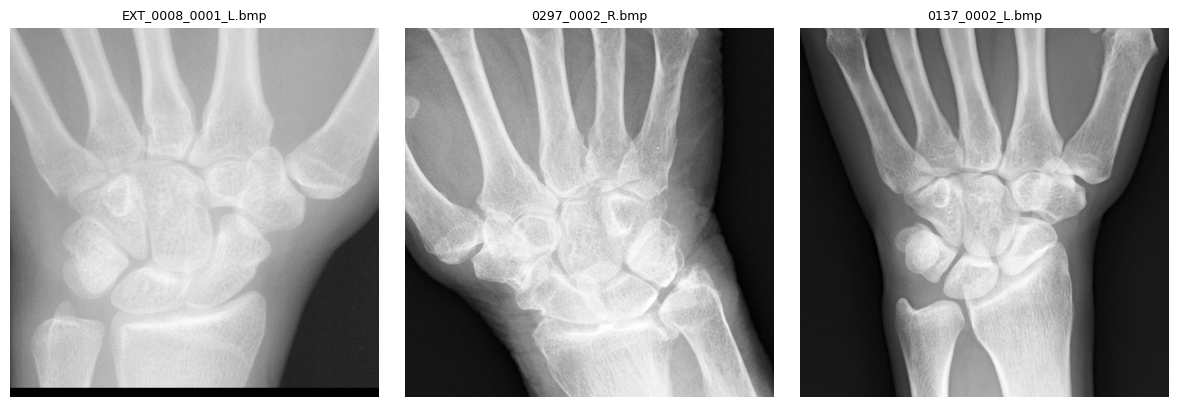

In [9]:
# Sélection aléatoire de 3 images
sample_files = random.sample(files, 3)

# Création de la figure
fig, axes = plt.subplots(1, 3, figsize=(12, 4))

for ax, img_path in zip(axes, sample_files):
    img = Image.open(img_path)
    ax.imshow(img, cmap="gray")
    ax.set_title(img_path.name, fontsize=9)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [10]:
def preprocess_sitk(img_path, out512, out224, alpha=0.3, beta=0.3):
    try:
        img = sitk.ReadImage(str(img_path))

        # Convertir en grayscale si multi-canaux
        if img.GetNumberOfComponentsPerPixel() > 1:
            img = sitk.VectorMagnitude(img)
            img = sitk.Cast(img, sitk.sitkUInt16)

        # Égalisation adaptative
        img_eq = sitk.AdaptiveHistogramEqualization(img, alpha=alpha, beta=beta)

        # Redimensionnements
        resampler = sitk.ResampleImageFilter()
        resampler.SetInterpolator(sitk.sitkLinear)

        # 512x512
        resampler.SetSize([512,512])
        img512 = resampler.Execute(img_eq)

        # 224x224
        resampler.SetSize([224,224])
        img224 = resampler.Execute(img_eq)

        # Sauvegarde en .png 16 bits
        out512_path = out512 / (img_path.stem + ".png")
        out224_path = out224 / (img_path.stem + ".png")
        sitk.WriteImage(img512, str(out512_path))
        sitk.WriteImage(img224, str(out224_path))

        return (img_path.name, str(out512_path), str(out224_path))

    except Exception as e:
        print(f"⚠️  Erreur sur {img_path.name}: {e}")
        return None

**Traitement en lot + Manifeste**

In [11]:
records = []
for f in tqdm(files, desc="Prétraitement SimpleITK"):
    rec = preprocess_sitk(f, OUT_512, OUT_224)
    if rec:
        records.append(tuple(rec))   # ✅ conversion explicite

Prétraitement SimpleITK:   0%|          | 0/618 [00:00<?, ?it/s]

In [12]:
manifest = pd.DataFrame(records, columns=["filename", "path_512", "path_224"])
manifest.to_csv(OUT_ROOT / "preprocessed_manifest.csv", index=False)

print("✅ Prétraitement terminé.")
print("Images sauvegardées dans :", OUT_ROOT)
manifest.head()

✅ Prétraitement terminé.
Images sauvegardées dans : /kaggle/working/data/preprocessed


,filename,path_512,path_224
0,0001_0001_L.bmp,/kaggle/working/data/preprocessed/512/0001_000...,/kaggle/working/data/preprocessed/224/0001_000...
1,0001_0001_R.bmp,/kaggle/working/data/preprocessed/512/0001_000...,/kaggle/working/data/preprocessed/224/0001_000...
2,0002_0001_L.bmp,/kaggle/working/data/preprocessed/512/0002_000...,/kaggle/working/data/preprocessed/224/0002_000...
3,0003_0001_L.bmp,/kaggle/working/data/preprocessed/512/0003_000...,/kaggle/working/data/preprocessed/224/0003_000...
4,0003_0001_R.bmp,/kaggle/working/data/preprocessed/512/0003_000...,/kaggle/working/data/preprocessed/224/0003_000...


Vérification visuelle

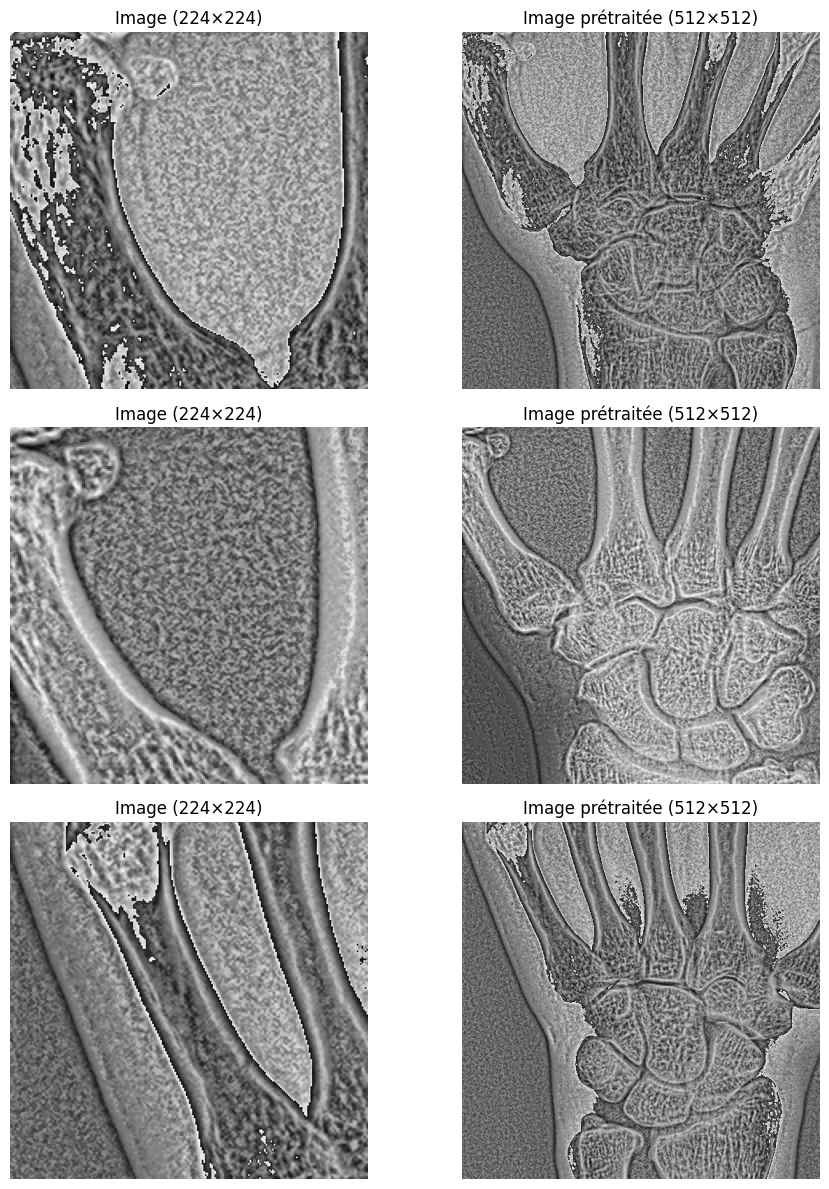

In [13]:
samples = random.sample(list(manifest.index), 3)
fig, axes = plt.subplots(len(samples), 2, figsize=(10, 12))

for i, idx in enumerate(samples):
    row = manifest.loc[idx]
    img_224 = sitk.GetArrayFromImage(sitk.ReadImage(row.path_224))
    img_512 = sitk.GetArrayFromImage(sitk.ReadImage(row.path_512))

    axes[i, 0].imshow(img_224, cmap='gray')
    axes[i, 0].set_title(f"Image (224×224)")
    axes[i, 0].axis('off')

    axes[i, 1].imshow(img_512, cmap='gray')
    axes[i, 1].set_title("Image prétraitée (512×512)")
    axes[i, 1].axis('off')

plt.tight_layout()
plt.show()

# Load Metadata and Merge with the Manifest

In [14]:
META_PATH = "/kaggle/input/ram-w600-local/RAM-W600/Metadata.xlsx"

# Load the Excel metadata
metadata = pd.read_excel(META_PATH)
print("Metadata loaded:", metadata.shape)

Metadata loaded: (611, 26)


In [15]:
metadata["Mapped Image Stem"] = metadata["Mapped Image Stem"].astype(str)
# 2) Extract stem from filenames (with side indicator)
manifest["stem"] = manifest["filename"].apply(lambda x: Path(x).stem)
# 3) Extract side information (L or R)
def get_side(s):
    if s.endswith("_L"):
        return "L"
    if s.endswith("_R"):
        return "R"
    return "?"

manifest["side"] = manifest["stem"].apply(get_side)

# 4) Remove _L or _R to match metadata stems
def remove_side_suffix(s):
    if s.endswith("_L") or s.endswith("_R"):
        return s[:-2]   # remove last 2 chars ("_L" or "_R")
    return s

manifest["stem_clean"] = manifest["stem"].apply(remove_side_suffix)

print("\nExample filename / stem / side / stem_clean:")
print(manifest[["filename", "stem", "side", "stem_clean"]].head())


Example filename / stem / side / stem_clean:
          filename         stem side stem_clean
0  0001_0001_L.bmp  0001_0001_L    L  0001_0001
1  0001_0001_R.bmp  0001_0001_R    R  0001_0001
2  0002_0001_L.bmp  0002_0001_L    L  0002_0001
3  0003_0001_L.bmp  0003_0001_L    L  0003_0001
4  0003_0001_R.bmp  0003_0001_R    R  0003_0001


In [16]:
# 5) Merge manifest with metadata
df = manifest.merge(
    metadata,
    left_on="stem_clean",
    right_on="Mapped Image Stem",
    how="inner"
)

print("\nMerged dataset size:", df.shape)
df.head()


Merged dataset size: (618, 32)


,filename,path_512,path_224,stem,side,stem_clean,Mapped Image Stem,NormalizedStudyID,NormalizedPatientID,IsRA,...,Sc_L,Lu_L,DR_L,DU_L,1st MC_R,Trapz_R,Sc_R,Lu_R,DR_R,DU_R
0,0001_0001_L.bmp,/kaggle/working/data/preprocessed/512/0001_000...,/kaggle/working/data/preprocessed/224/0001_000...,0001_0001_L,L,0001_0001,0001_0001,1,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0
1,0001_0001_R.bmp,/kaggle/working/data/preprocessed/512/0001_000...,/kaggle/working/data/preprocessed/224/0001_000...,0001_0001_R,R,0001_0001,0001_0001,1,1,1,...,0.0,0.0,0.0,0.0,0.0,0.0,2.0,0.0,0.0,0.0
2,0002_0001_L.bmp,/kaggle/working/data/preprocessed/512/0002_000...,/kaggle/working/data/preprocessed/224/0002_000...,0002_0001_L,L,0002_0001,0002_0001,1,2,1,...,2.0,0.0,0.0,2.0,0.0,1.0,2.0,1.0,0.0,0.0
3,0003_0001_L.bmp,/kaggle/working/data/preprocessed/512/0003_000...,/kaggle/working/data/preprocessed/224/0003_000...,0003_0001_L,L,0003_0001,0003_0001,1,3,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,0003_0001_R.bmp,/kaggle/working/data/preprocessed/512/0003_000...,/kaggle/working/data/preprocessed/224/0003_000...,0003_0001_R,R,0003_0001,0003_0001,1,3,1,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [17]:
df.columns

Index(['filename', 'path_512', 'path_224', 'stem', 'side', 'stem_clean',
       'Mapped Image Stem', 'NormalizedStudyID', 'NormalizedPatientID', 'IsRA',
       'PatientSex', 'PatientAge', 'InstitutionName', 'StudyDate (Days)',
       'ImagerPixelSpacing', '[Rows, Columns]', 'L', 'R', 'SvdH_L', 'SvdH_R',
       '1st MC_L', 'Trapz_L', 'Sc_L', 'Lu_L', 'DR_L', 'DU_L', '1st MC_R',
       'Trapz_R', 'Sc_R', 'Lu_R', 'DR_R', 'DU_R'],
      dtype='object')

**Create the Dataset Class for 224×224 Images**

# ============================
# DATASET GLOBAL STATISTICS
# ============================

In [18]:
dataset_stats = {
    "Num Images": len(df),
    "Num Patients": df["NormalizedPatientID"].nunique(),
    "Num Studies": df["NormalizedStudyID"].nunique(),
    "Num Institutions": df["InstitutionName"].nunique(),
    "RA Images": (df["IsRA"] == 1).sum(),
    "Non-RA Images": (df["IsRA"] == 0).sum(),
}

table1 = pd.DataFrame.from_dict(dataset_stats, orient="index", columns=["Count"])
table1


,Count
Num Images,618
Num Patients,335
Num Studies,12
Num Institutions,7
RA Images,370
Non-RA Images,248


In [19]:
institution_dist = (
    df["InstitutionName"]
    .value_counts()
    .rename_axis("Institution")
    .reset_index(name="NumImages")
)

institution_dist


,Institution,NumImages
0,HMCRD,406
1,DHA,73
2,SCGH,62
3,BTXRD,47
4,TUOMC,12
5,FA,12
6,HU,6


In [20]:
df["PatientAge"].value_counts().head(10)


PatientAge
Unknown    59
50.5       18
54.5       12
46.5       10
52.5        9
56.5        9
57.5        8
67.5        8
47.5        8
75.5        7
Name: count, dtype: int64

In [21]:
df["PatientAge_num"] = pd.to_numeric(df["PatientAge"], errors="coerce")


In [22]:
age_stats = df["PatientAge_num"].describe()
age_stats


count    559.000000
mean      53.577138
std       17.773354
min       17.660000
25%       46.500000
50%       56.120000
75%       66.510000
max       93.270000
Name: PatientAge_num, dtype: float64

In [23]:
# Regrouper O → M
df["PatientSex_grouped"] = df["PatientSex"].replace({"O": "M"})
sex_dist_grouped = (
    df["PatientSex_grouped"]
    .value_counts()
    .rename_axis("Sex")
    .reset_index(name="Count")
)

sex_dist_grouped


,Sex,Count
0,F,447
1,M,171


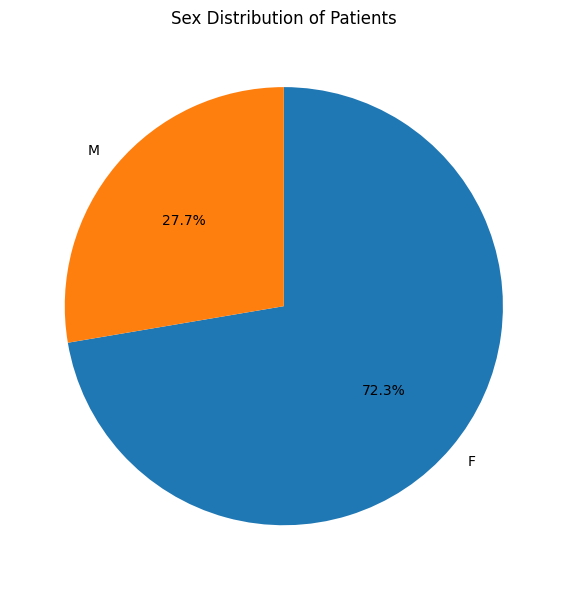

In [24]:
# Calcul des pourcentages
sex_dist_grouped["Percentage"] = (
    100 * sex_dist_grouped["Count"] / sex_dist_grouped["Count"].sum()
)

# Plot
plt.figure(figsize=(6, 6))
plt.pie(
    sex_dist_grouped["Count"],
    labels=sex_dist_grouped["Sex"],
    autopct="%.1f%%",
    startangle=90,
    counterclock=False
)
plt.title("Sex Distribution of Patients")
plt.tight_layout()
plt.show()


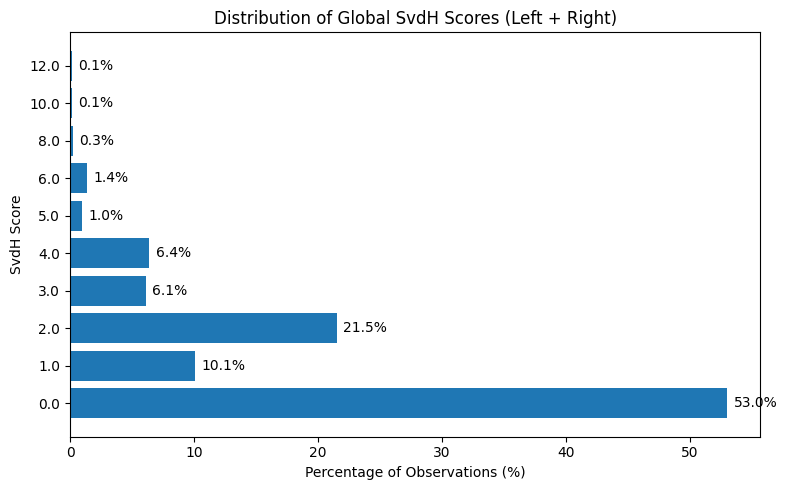

In [25]:
# Global SvdH (Left + Right)
svdh_long = df[["SvdH_L", "SvdH_R"]].melt(
    value_vars=["SvdH_L", "SvdH_R"],
    var_name="Side",
    value_name="SvdH"
)

svdh_long["SvdH"] = pd.to_numeric(svdh_long["SvdH"], errors="coerce")

svdh_dist = (
    svdh_long["SvdH"]
    .value_counts()
    .sort_index()
    .rename_axis("SvdH Score")
    .reset_index(name="Count")
)


svdh_dist["Percentage"] = (
    100 * svdh_dist["Count"] / svdh_dist["Count"].sum()
)

plt.figure(figsize=(8, 5))

plt.barh(
    svdh_dist["SvdH Score"].astype(str),
    svdh_dist["Percentage"]
)

plt.xlabel("Percentage of Observations (%)")
plt.ylabel("SvdH Score")
plt.title("Distribution of Global SvdH Scores (Left + Right)")

# Optionnel : afficher la valeur % sur chaque barre
for i, v in enumerate(svdh_dist["Percentage"]):
    plt.text(v + 0.5, i, f"{v:.1f}%", va="center")

plt.tight_layout()
plt.show()


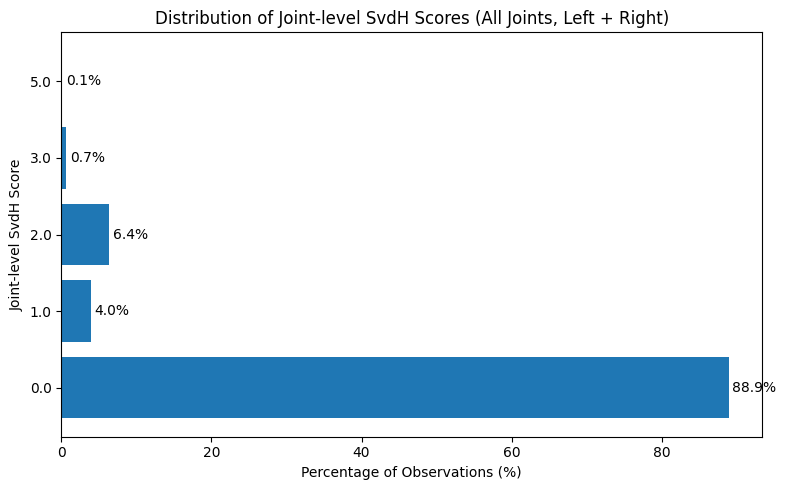

In [26]:
svdh_joints_L = df[
    ["1st MC_L", "Trapz_L", "Sc_L", "Lu_L", "DR_L", "DU_L"]
].melt(
    var_name="Joint",
    value_name="SvdH"
)

svdh_joints_L["Side"] = "Left"

svdh_joints_R = df[
    ["1st MC_R", "Trapz_R", "Sc_R", "Lu_R", "DR_R", "DU_R"]
].melt(
    var_name="Joint",
    value_name="SvdH"
)

svdh_joints_R["Side"] = "Right"

svdh_joints = pd.concat([svdh_joints_L, svdh_joints_R], ignore_index=True)
svdh_joints["SvdH"] = pd.to_numeric(svdh_joints["SvdH"], errors="coerce")

svdh_joint_dist = (
    svdh_joints["SvdH"]
    .value_counts()
    .sort_index()
    .rename_axis("Joint-level SvdH Score")
    .reset_index(name="Count")
)


svdh_joint_dist["Percentage"] = (
    100 * svdh_joint_dist["Count"] / svdh_joint_dist["Count"].sum()
)

plt.figure(figsize=(8, 5))

plt.barh(
    svdh_joint_dist["Joint-level SvdH Score"].astype(str),
    svdh_joint_dist["Percentage"]
)

plt.xlabel("Percentage of Observations (%)")
plt.ylabel("Joint-level SvdH Score")
plt.title("Distribution of Joint-level SvdH Scores (All Joints, Left + Right)")

# Afficher les pourcentages sur les barres
for i, v in enumerate(svdh_joint_dist["Percentage"]):
    plt.text(v + 0.5, i, f"{v:.1f}%", va="center")

plt.tight_layout()
plt.show()


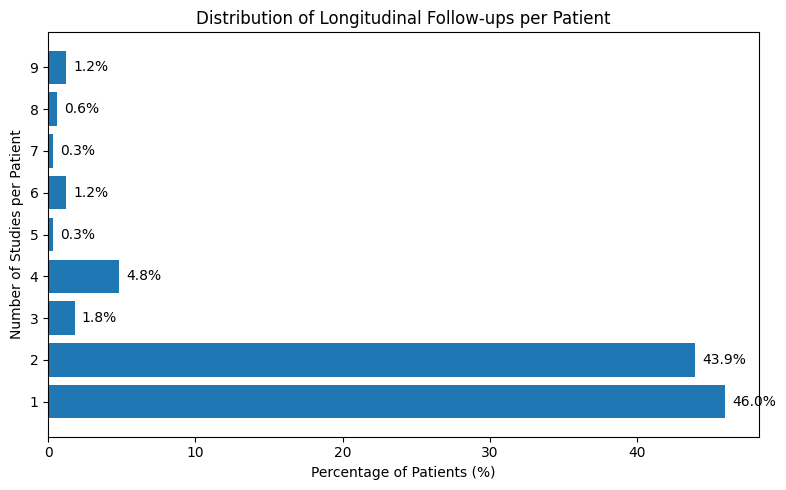

In [27]:
followup_dist = (
    df.groupby("NormalizedPatientID")
      .size()
      .value_counts()
      .sort_index()
      .rename_axis("NumStudiesPerPatient")
      .reset_index(name="NumPatients")
)


followup_dist["Percentage"] = (
    100 * followup_dist["NumPatients"] / followup_dist["NumPatients"].sum()
)

plt.figure(figsize=(8, 5))

plt.barh(
    followup_dist["NumStudiesPerPatient"].astype(str),
    followup_dist["Percentage"]
)

plt.xlabel("Percentage of Patients (%)")
plt.ylabel("Number of Studies per Patient")
plt.title("Distribution of Longitudinal Follow-ups per Patient")

# Afficher les pourcentages sur les barres
for i, v in enumerate(followup_dist["Percentage"]):
    plt.text(v + 0.5, i, f"{v:.1f}%", va="center")

plt.tight_layout()
plt.show()



In [28]:
# --------------------------
# Transform for ResNet input
# --------------------------
resnet_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485], std=[0.229]),  # grayscale, we will repeat channels
])

# --------------------------
# Dataset for embeddings
# --------------------------
class EmbeddingDataset(Dataset):
    def __init__(self, df):
        self.df = df.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        path = row["path_224"]
        img = Image.open(path).convert("L")

        img = resnet_transform(img)
        img = img.repeat(3, 1, 1)

        # Convert pandas Series → dict (VERY IMPORTANT)
        meta = row.to_dict()

        return img, meta


**Build the Two Embedding Models**

- Build ResNet18 & ResNet50 Feature Extractors

In [29]:
# ------------------------------------
# Create a function to modify ResNet
# ------------------------------------
def make_resnet(model_name="resnet50"):
    if model_name == "resnet50":
        net = models.resnet50(weights="IMAGENET1K_V1")
        feature_dim = 2048
    elif model_name == "resnet18":
        net = models.resnet18(weights="IMAGENET1K_V1")
        feature_dim = 512
    else:
        raise ValueError("Choose resnet18 or resnet50")

    # Replace classifier (fc) with Identity → output is embedding
    net.fc = nn.Identity()

    return net.to(device), feature_dim

In [30]:
resnet18, dim18 = make_resnet("resnet18")
resnet18.eval()
print("ResNet-18 ready. Output dim =", dim18)

Downloading: "https://download.pytorch.org/models/resnet18-f37072fd.pth" to /root/.cache/torch/hub/checkpoints/resnet18-f37072fd.pth
100%|██████████| 44.7M/44.7M [00:00<00:00, 161MB/s] 


ResNet-18 ready. Output dim = 512


In [31]:
resnet50, dim50 = make_resnet("resnet50")
resnet50.eval()
print("ResNet-50 ready. Output dim =", dim50)

Downloading: "https://download.pytorch.org/models/resnet50-0676ba61.pth" to /root/.cache/torch/hub/checkpoints/resnet50-0676ba61.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 188MB/s] 


ResNet-50 ready. Output dim = 2048


In [32]:
def collate_meta(batch):
    images = []
    metas = []
    for img, meta in batch:
        images.append(img)
        metas.append(meta)   # keep as a dict

    images = torch.stack(images)   # batch images normally
    return images, metas           # metas stays list-of-dicts

In [33]:
# -----------------------------------
# Create Datasets and DataLoaders
# -----------------------------------
dataset = EmbeddingDataset(df)

loader18 = DataLoader(dataset, batch_size=32, shuffle=False, num_workers=2,
                      collate_fn=collate_meta)


# -----------------------------------
# Function to extract embeddings
# -----------------------------------
def extract_features(model, loader, feature_dim):
    features = []

    with torch.no_grad():
        for images, rows in tqdm(loader):
            images = images.to(device)
            feats = model(images).cpu().numpy()

            for f, r in zip(feats, rows):
                r = r.copy()       # avoid overwriting original meta
                r["feature"] = f   # attach embedding
                features.append(r)

    return pd.DataFrame(features)

# -----------------------------------
# Extract ResNet-18 features
# -----------------------------------
print("Extracting ResNet18 embeddings...")
df_feat18 = extract_features(resnet18, loader18, dim18)

with open("/kaggle/working/features_resnet18.pkl", "wb") as f:
    pickle.dump(df_feat18, f)

print("Saved ResNet18:", df_feat18.shape)

Extracting ResNet18 embeddings...


  0%|          | 0/20 [00:00<?, ?it/s]

Saved ResNet18: (618, 35)


In [34]:
# -----------------------------------
# Extract ResNet-50 features
# -----------------------------------

loader50 = DataLoader(dataset, batch_size=16, shuffle=False, num_workers=0,
                      collate_fn=collate_meta)

print("Extracting ResNet50 embeddings...")
df_feat50 = extract_features(resnet50, loader50, dim50)

with open("/kaggle/working/features_resnet50.pkl", "wb") as f:
    pickle.dump(df_feat50, f)

print("Saved ResNet50:", df_feat50.shape)

Extracting ResNet50 embeddings...


  0%|          | 0/39 [00:00<?, ?it/s]

Saved ResNet50: (618, 35)


*Load the saved feature DataFrames*

In [35]:
# Load the extracted features
with open("/kaggle/working/features_resnet18.pkl", "rb") as f:
    df18 = pickle.load(f)

with open("/kaggle/working/features_resnet50.pkl", "rb") as f:
    df50 = pickle.load(f)

print(df18.shape, df50.shape)
print(df18.columns)

(618, 35) (618, 35)
Index(['filename', 'path_512', 'path_224', 'stem', 'side', 'stem_clean',
       'Mapped Image Stem', 'NormalizedStudyID', 'NormalizedPatientID', 'IsRA',
       'PatientSex', 'PatientAge', 'InstitutionName', 'StudyDate (Days)',
       'ImagerPixelSpacing', '[Rows, Columns]', 'L', 'R', 'SvdH_L', 'SvdH_R',
       '1st MC_L', 'Trapz_L', 'Sc_L', 'Lu_L', 'DR_L', 'DU_L', '1st MC_R',
       'Trapz_R', 'Sc_R', 'Lu_R', 'DR_R', 'DU_R', 'PatientAge_num',
       'PatientSex_grouped', 'feature'],
      dtype='object')


*Extract the feature matrices X18 and X50*

In [36]:
# Convert feature columns (numpy arrays) into a 2D matrix
X18 = np.vstack(df18["feature"].values)   # shape: (618, 512)
X50 = np.vstack(df50["feature"].values)   # shape: (618, 2048)

print("ResNet18 matrix:", X18.shape)
print("ResNet50 matrix:", X50.shape)

ResNet18 matrix: (618, 512)
ResNet50 matrix: (618, 2048)


In [37]:
import umap.umap_ as umap
from sklearn.preprocessing import StandardScaler

2026-07-12 09:16:12.611943: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1783847772.871747      49 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1783847772.940404      49 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

AttributeError: 'MessageFactory' object has no attribute 'GetPrototype'

In [38]:
scaler18 = StandardScaler()
X18_scaled = scaler18.fit_transform(X18)

scaler50 = StandardScaler()
X50_scaled = scaler50.fit_transform(X50)

print(X18_scaled.shape, X50_scaled.shape)

(618, 512) (618, 2048)


**Compute 2D and 3D UMAP embeddings**

In [39]:
# 2D UMAP
umap2d_18 = umap.UMAP(
    n_neighbors=20,
    min_dist=0.1,
    metric="euclidean",
    n_components=2,
    random_state=42,
)
U18_2d = umap2d_18.fit_transform(X18_scaled)

umap2d_50 = umap.UMAP(
    n_neighbors=20,
    min_dist=0.1,
    metric="euclidean",
    n_components=2,
    random_state=42,
)
U50_2d = umap2d_50.fit_transform(X50_scaled)

print("U18_2d:", U18_2d.shape, "U50_2d:", U50_2d.shape)

# 3D UMAP
umap3d_18 = umap.UMAP(
    n_neighbors=20,
    min_dist=0.1,
    metric="euclidean",
    n_components=3,
    random_state=42,
)
U18_3d = umap3d_18.fit_transform(X18_scaled)

umap3d_50 = umap.UMAP(
    n_neighbors=20,
    min_dist=0.1,
    metric="euclidean",
    n_components=3,
    random_state=42,
)
U50_3d = umap3d_50.fit_transform(X50_scaled)

print("U18_3d:", U18_3d.shape, "U50_3d:", U50_3d.shape)


/usr/local/lib/python3.11/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.11/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


U18_2d: (618, 2) U50_2d: (618, 2)


/usr/local/lib/python3.11/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(
/usr/local/lib/python3.11/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


U18_3d: (618, 3) U50_3d: (618, 3)


In [40]:
import matplotlib.pyplot as plt
from mpl_toolkits.mplot3d import Axes3D

In [41]:
def plot_umap_2d(U18, U50, labels, label_name, is_categorical=True):
    """
    U18, U50: 2D embeddings (N, 2)
    labels: array-like (N,)
    label_name: string for titles
    is_categorical: choose discrete colormap + legend behavior
    """
    labels = np.array(labels)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))

    # Left: ResNet18
    ax = axes[0]
    if is_categorical:
        # map unique labels to integers
        uniques = np.unique(labels)
        cmap = plt.get_cmap("tab10")
        for i, v in enumerate(uniques):
            mask = labels == v
            ax.scatter(U18[mask, 0], U18[mask, 1], s=10, alpha=0.8,
                       label=str(v), color=cmap(i % 10))
        ax.legend(title=label_name, fontsize=8)
    else:
        sc = ax.scatter(U18[:, 0], U18[:, 1], c=labels, s=10, alpha=0.8, cmap="viridis")
        cb = plt.colorbar(sc, ax=ax)
        cb.set_label(label_name)

    ax.set_title(f"UMAP 2D – ResNet18 – {label_name}")
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")

    # Right: ResNet50
    ax = axes[1]
    if is_categorical:
        uniques = np.unique(labels)
        cmap = plt.get_cmap("tab10")
        for i, v in enumerate(uniques):
            mask = labels == v
            ax.scatter(U50[mask, 0], U50[mask, 1], s=10, alpha=0.8,
                       label=str(v), color=cmap(i % 10))
        ax.legend(title=label_name, fontsize=8)
    else:
        sc = ax.scatter(U50[:, 0], U50[:, 1], c=labels, s=10, alpha=0.8, cmap="viridis")
        cb = plt.colorbar(sc, ax=ax)
        cb.set_label(label_name)

    ax.set_title(f"UMAP 2D – ResNet50 – {label_name}")
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")

    plt.tight_layout()
    plt.show()


def plot_umap_3d(U18, U50, labels, label_name, is_categorical=True):
    labels = np.array(labels)

    fig = plt.figure(figsize=(12, 5))

    # Left: ResNet18
    ax = fig.add_subplot(1, 2, 1, projection="3d")
    if is_categorical:
        uniques = np.unique(labels)
        cmap = plt.get_cmap("tab10")
        for i, v in enumerate(uniques):
            mask = labels == v
            ax.scatter(U18[mask, 0], U18[mask, 1], U18[mask, 2],
                       s=10, alpha=0.8, label=str(v), color=cmap(i % 10))
        ax.legend(title=label_name, fontsize=8)
    else:
        sc = ax.scatter(U18[:, 0], U18[:, 1], U18[:, 2],
                        c=labels, s=10, alpha=0.8, cmap="viridis")
        cb = plt.colorbar(sc, ax=ax, shrink=0.6)
        cb.set_label(label_name)

    ax.set_title(f"UMAP 3D – ResNet18 – {label_name}")
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")
    ax.set_zlabel("UMAP-3")

    # Right: ResNet50
    ax = fig.add_subplot(1, 2, 2, projection="3d")
    if is_categorical:
        uniques = np.unique(labels)
        cmap = plt.get_cmap("tab10")
        for i, v in enumerate(uniques):
            mask = labels == v
            ax.scatter(U50[mask, 0], U50[mask, 1], U50[mask, 2],
                       s=10, alpha=0.8, label=str(v), color=cmap(i % 10))
        ax.legend(title=label_name, fontsize=8)
    else:
        sc = ax.scatter(U50[:, 0], U50[:, 1], U50[:, 2],
                        c=labels, s=10, alpha=0.8, cmap="viridis")
        cb = plt.colorbar(sc, ax=ax, shrink=0.6)
        cb.set_label(label_name)

    ax.set_title(f"UMAP 3D – ResNet50 – {label_name}")
    ax.set_xlabel("UMAP-1")
    ax.set_ylabel("UMAP-2")
    ax.set_zlabel("UMAP-3")

    plt.tight_layout()
    plt.show()


In [42]:
from torchvision import models, transforms


# -----------------------------
# Transform for ResNet input
# -----------------------------
transform_resnet = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.485], std=[0.229]),   # grayscale → convert below
])

# -----------------------------
# Load pretrained ResNet50
# -----------------------------
resnet = models.resnet50(weights="IMAGENET1K_V1")
resnet.fc = nn.Identity()            # output = 2048-dim embedding
resnet = resnet.to(device)
resnet.eval()

# -----------------------------
# Feature extraction function
# -----------------------------
def extract_embedding(img_path):
    img = Image.open(img_path).convert("L")  # grayscale

    # convert to 3-channel for ResNet
    img = transform_resnet(img)
    img = img.repeat(3, 1, 1)               # (1,H,W) → (3,H,W)

    img = img.unsqueeze(0).to(device)

    with torch.no_grad():
        feat = resnet(img).cpu().numpy().flatten()

    return feat  # shape 2048

# -----------------------------
# Extract embeddings for all images
# -----------------------------
all_features = []

for i, row in tqdm(df.iterrows(), total=len(df)):
    feat = extract_embedding(row["path_224"])

    all_features.append({
        "filename": row["filename"],
        "stem_clean": row["stem_clean"],
        "side": row["side"],
        "IsRA": row["IsRA"],
        "Age": row["PatientAge"],
        "Sex": row["PatientSex"],
        "Institution": row["InstitutionName"],
        "StudyDate": row["StudyDate (Days)"],
        # add others if needed
        "feature": feat
    })

# convert to DataFrame with numpy arrays
features_df = pd.DataFrame(all_features)

# Save
import pickle
with open("/kaggle/working/features.pkl", "wb") as f:
    pickle.dump(features_df, f)

print("Saved embeddings:", features_df.shape)
features_df.head()


  0%|          | 0/618 [00:00<?, ?it/s]

Saved embeddings: (618, 9)


,filename,stem_clean,side,IsRA,Age,Sex,Institution,StudyDate,feature
0,0001_0001_L.bmp,0001_0001,L,1,59.5,F,HMCRD,0,"[0.019855773, 0.10042419, 0.23586364, 0.135947..."
1,0001_0001_R.bmp,0001_0001,R,1,59.5,F,HMCRD,0,"[0.12076699, 0.5038343, 0.54878455, 0.07349793..."
2,0002_0001_L.bmp,0002_0001,L,1,71.5,F,HMCRD,0,"[0.08408789, 0.22284038, 0.5725246, 0.05768367..."
3,0003_0001_L.bmp,0003_0001,L,1,64.5,F,HMCRD,0,"[0.08818077, 0.028840639, 0.27548993, 0.026924..."
4,0003_0001_R.bmp,0003_0001,R,1,64.5,F,HMCRD,0,"[0.25750622, 0.73519665, 0.14118646, 0.0419210..."


**IsRA (categorical: 0/1)**

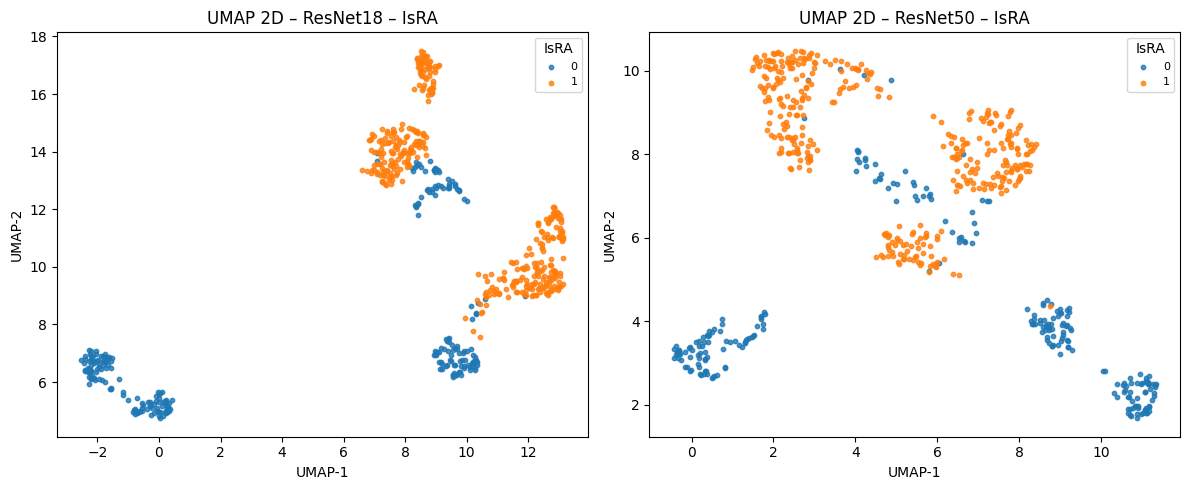

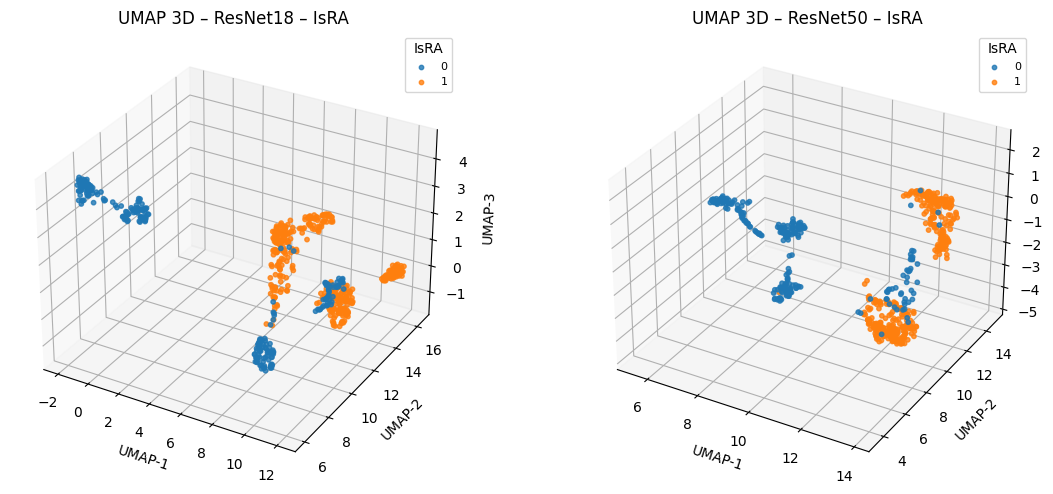

In [43]:
labels_IsRA = df18["IsRA"].values

plot_umap_2d(U18_2d, U50_2d, labels_IsRA, "IsRA", is_categorical=True)
plot_umap_3d(U18_3d, U50_3d, labels_IsRA, "IsRA", is_categorical=True)

**The UMAP projection obtained from ResNet-18 embeddings shows a clear and well-defined separation between radiographs from RA patients and non-RA controls. The clusters formed in the 2-dimensional space are compact, structured, and visually coherent, indicating that even a lightweight CNN backbone like ResNet-18 succeeds in extracting features that strongly correlate with the presence of rheumatoid arthritis. RA samples tend to occupy similar regions of the manifold, while non-RA samples form distinct clusters, suggesting that the visual differences learned by the network are meaningful and systematically captured. This confirms that the dataset contains identifiable radiographic patterns of RA that are detectable without supervision once passed through a CNN feature extractor.**

**The 3D UMAP projection of ResNet-18 embeddings reinforces the strong separation already observed in the 2D plot. RA and non-RA cases form distinct, compact clusters that remain clearly separated when visualized in three dimensions. The added depth helps reveal cluster continuity and internal structure that is partially compressed in 2D. Specifically, samples form elongated, tube-like trajectories within each class, suggesting that ResNet-18 captures gradual variations in radiographic appearance—possibly related to anatomical differences or early severity gradients—while still maintaining global separation between RA and non-RA manifolds. This confirms that latent representations learned by ResNet-18 are not only discriminative but also geometrically coherent, providing a stable foundation for downstream classification and exploratory analysis.**

The UMAP plot derived from ResNet-50 embeddings reveals a richer and more complex structure compared to ResNet-18. Although RA and non-RA cases remain globally separated, the manifold presents more internal variations and a larger number of sub-clusters. This is expected because ResNet-50 produces higher-dimensional and more expressive features. These additional clusters likely reflect more subtle differences between patients, such as variations in joint anatomy, early vs. advanced RA changes, or other metadata factors. While the 2D projection slightly compresses the structure—leading to some mixing—the overall organization still demonstrates that RA pathology induces consistent feature patterns that ResNet-50 captures effectively. This suggests that deeper models may provide more nuanced diagnostic information and are capable of supporting more advanced downstream tasks, such as severity prediction or multimodal fusion.

The 3D UMAP embedding from ResNet-50 shows a richer and more articulated structure than the ResNet-18 version. The RA manifold breaks into several sub-clusters, some of which lie along continuous curves or branches, suggesting finer-grained radiographic variation captured by the deeper model. Non-RA samples also form multiple distinct volumes, reflecting anatomical diversity across patients. Importantly, even with increased complexity, RA and non-RA samples remain largely separated in 3D space, indicating that ResNet-50 captures high-level pathological signatures consistently across subjects. The more detailed geometry suggests that the deeper network is sensitive to subtler radiographic cues—potentially erosion patterns, joint-space narrowing, or bone texture—offering a richer basis for clustering, severity analysis, and multimodal fusion with metadata.

**PatientSex (M/F**

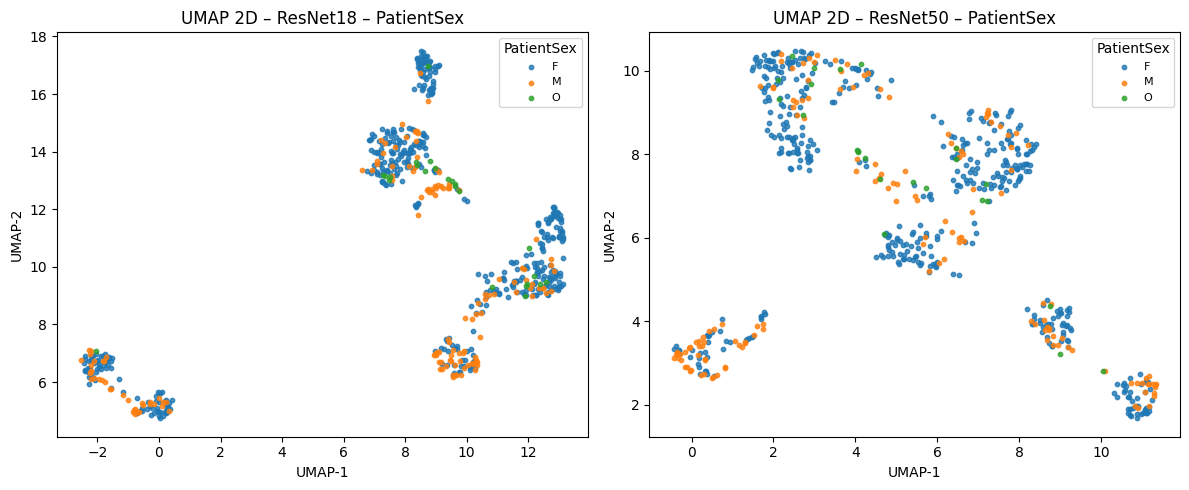

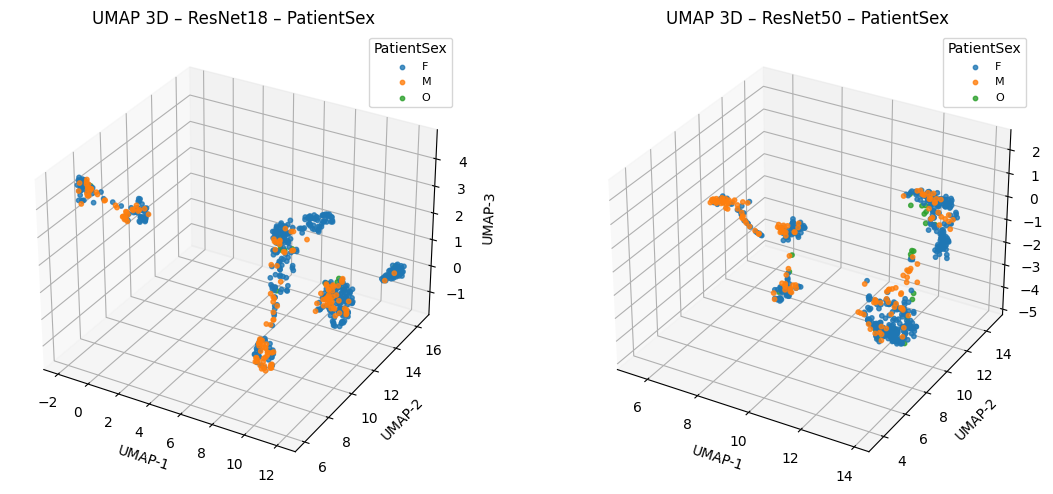

In [44]:
labels_sex = df18["PatientSex"].values

plot_umap_2d(U18_2d, U50_2d, labels_sex, "PatientSex", is_categorical=True)
plot_umap_3d(U18_3d, U50_3d, labels_sex, "PatientSex", is_categorical=True)

**When projecting ResNet-18 embeddings in 2D and coloring samples by sex, the plot shows no meaningful separation between male and female patients. All sexes are evenly mixed within the same clusters, indicating that the visual features extracted by the model are not influenced by patient sex. The embedding structure is dominated by radiographic characteristics rather than demographic attributes. This suggests that ResNet-18 does not encode sex-specific biases from wrist radiographs, which is desirable: the model focuses on pathology-related patterns rather than patient identity traits.**

**The 3D projection of ResNet-18 embeddings provides an even clearer demonstration: samples of different sexes occupy the same volumes of the manifold. No axis shows stratification or directional separation by sex. This indicates that the model learns general radiographic morphology rather than sex-specific bone structure differences. The absence of bias is reassuring, demonstrating that the 3D latent space does not encode demographic separation.**

The 2D UMAP projection of ResNet-50 features shows the same behavior: male and female samples overlap almost perfectly across all clusters. Despite ResNet-50’s greater representational capacity, the manifold does not organize itself according to sex. This confirms that deeper visual features remain pathology-driven, not demographically driven. The uniform mixing indicates that sex does not manifest strongly in the visual appearance of the wrist radiographs, or at least not in a way that affects learned embeddings.

Similarly, the 3D UMAP from ResNet-50 embeddings continues to show a fully mixed distribution across sexes. Even with higher feature complexity, the manifold remains independent of patient sex, suggesting that sex has minimal influence on the wrist radiograph appearance compared to anatomical variability and RA pathology. This supports the fairness of the feature extraction process and indicates that downstream models are unlikely to rely on sex-related signals when predicting RA.

*SvdH_L and SvdH_R (Option E: separate)*

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  name : str


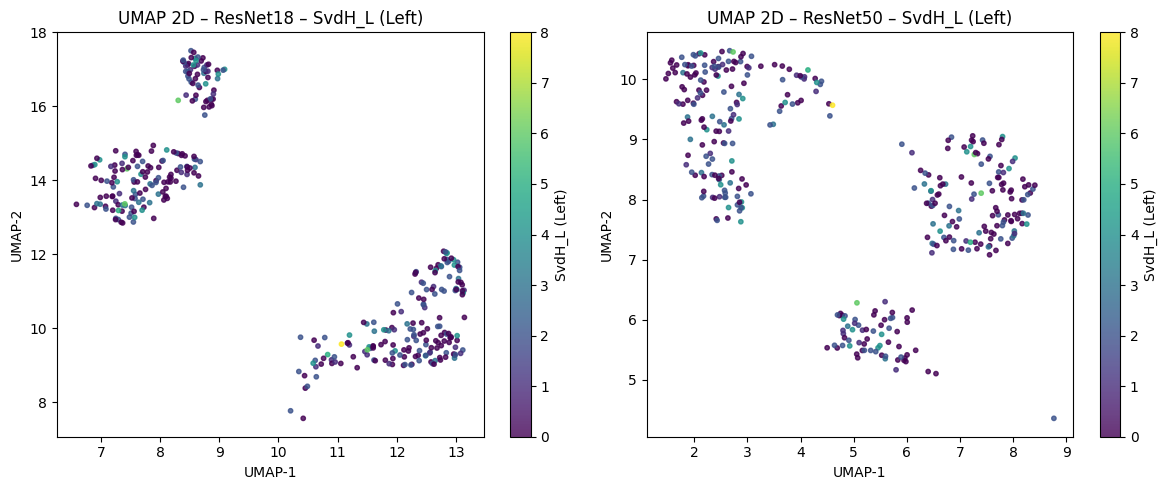

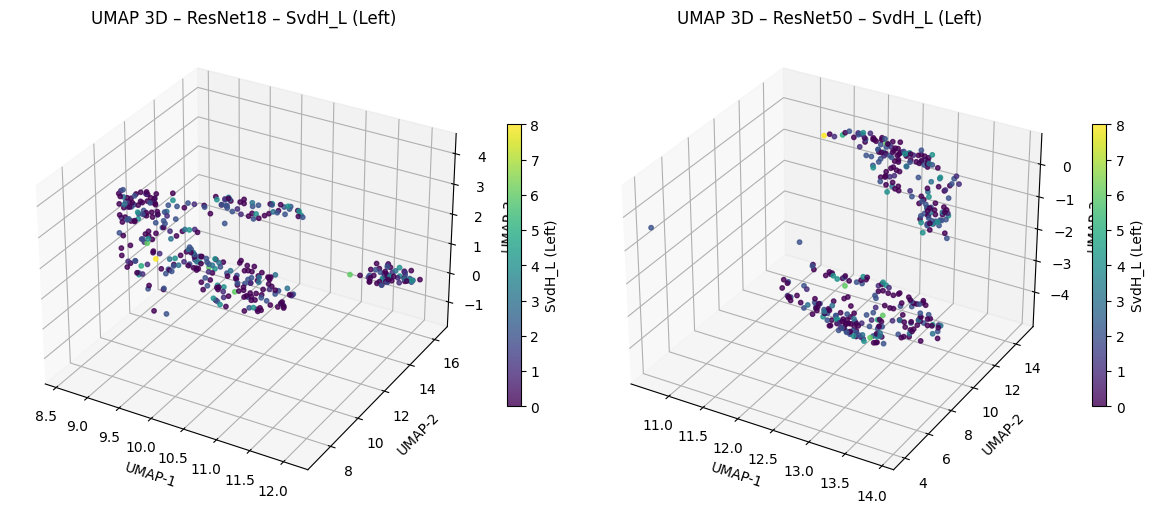

In [45]:
labels_svdh_L = df18["SvdH_L"].values

plot_umap_2d(U18_2d, U50_2d, labels_svdh_L, "SvdH_L (Left)", is_categorical=False)
plot_umap_3d(U18_3d, U50_3d, labels_svdh_L, "SvdH_L (Left)", is_categorical=False)

**In the 2D UMAP projection derived from ResNet-18 features, the SvdH_L erosion scores show a smooth gradient within clusters, rather than sharp separations. Low-severity samples (purple) tend to group together, while higher scores (yellow/green) appear in nearby but distinct regions of the manifold. This suggests that the model captures progressive structural changes associated with erosion severity, even though ResNet-18 is relatively shallow. The continuity of the color transitions indicates that erosion severity behaves like a continuous progression rather than discrete categories in the learned feature space. Thus, ResNet-18 features encode clinically meaningful information about joint damage.**

**The 3D UMAP visualization provides a clearer perspective on how erosion severity is distributed. For ResNet-18, SvdH_L scores again display a continuous progression along certain directions in the manifold. While not perfectly separated, higher severity points occupy elongated sub-regions of the embedding. This indicates that the network’s internal representation organizes disease progression as a trajectory, supporting the idea that erosion severity is encoded as a gradual deformation pattern in radiographs. The 3D projection reduces overlap seen in 2D and highlights how early vs. late erosion stages flow along distinct branches.**

The UMAP projection of ResNet-50 embeddings reveals an even clearer severity pattern. Here, SvdH_L values form localized pockets of higher scores, indicating that the deeper network captures more subtle anatomical changes associated with erosion. The clustering structure appears richer and more segmented, with higher-severity samples consistently positioned near the outer or more isolated regions of the manifold. This suggests that ResNet-50 has a stronger ability to differentiate mild, moderate, and more advanced erosion. The embedding structure therefore reflects a latent severity axis, which is highly valuable for downstream tasks like severity regression or early-stage RA identification.

The 3D ResNet-50 UMAP shows the strongest correlation between feature space and erosion severity. High-severity samples (yellow) cluster at the extremities of the manifold, clearly separated from low-severity samples. The depth dimension reveals layered structures that correspond to increasing erosion severity, confirming that ResNet-50 extracts high-fidelity radiographic cues linked to bone loss and joint deformation. This concentrated organization of SvdH_L scores validates the capability of the network to learn a disease severity continuum, suggesting it can be used not only for classification but also for robust severity estimation.

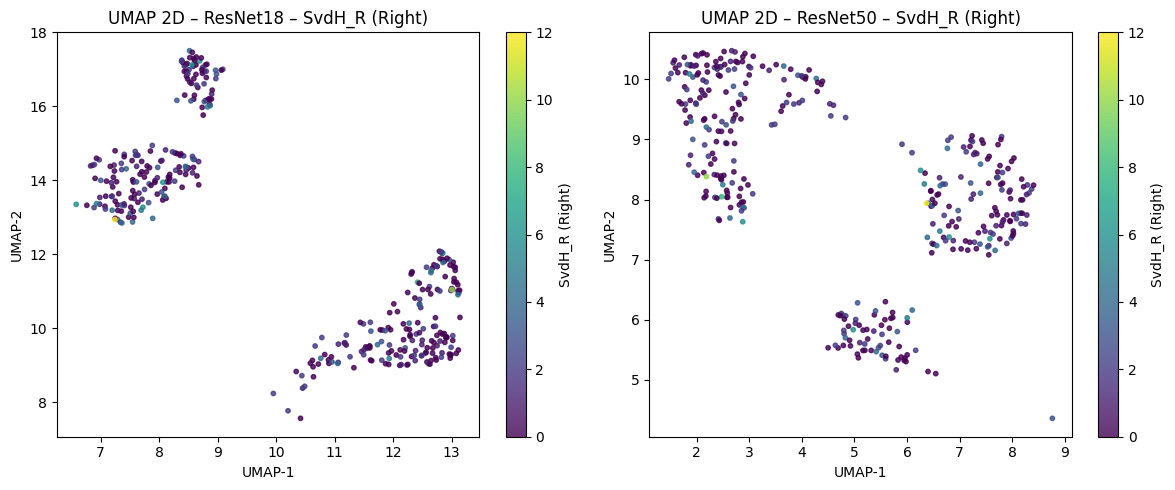

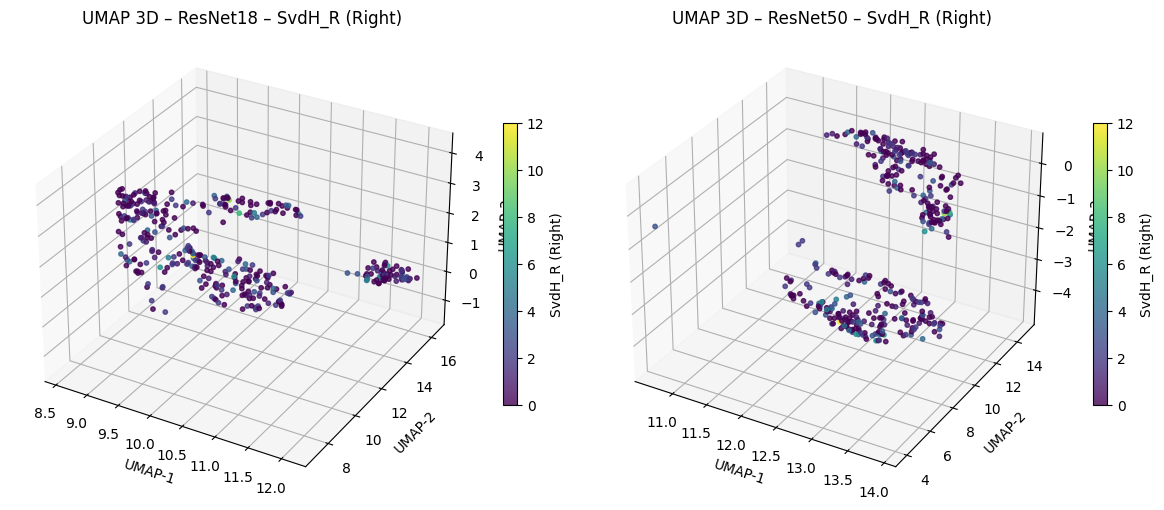

In [46]:
labels_svdh_R = df18["SvdH_R"].values

plot_umap_2d(U18_2d, U50_2d, labels_svdh_R, "SvdH_R (Right)", is_categorical=False)
plot_umap_3d(U18_3d, U50_3d, labels_svdh_R, "SvdH_R (Right)", is_categorical=False)


**In the 2D UMAP projection using ResNet-18 embeddings, the SvdH_R erosion scores appear largely concentrated at the lower end of the severity scale. Most samples have low SvdH_R values (dark purple), and the few higher-severity cases (green–yellow) are sparsely distributed across the manifold. This suggests that the right-wrist erosion distribution in the dataset is heavily imbalanced, with far fewer high-severity cases compared to the left wrist. Despite the lack of strong color gradients, ResNet-18 still preserves local structure: the few higher-severity samples tend to appear at the edges of clusters, indicating that the model captures some anatomical differences associated with erosion, even when the severity signal is weak or sparse.**

**The 3D projection reveals more subtle structure: although high-severity points are rare, they tend to appear along distinct low-density directions within the manifold. This suggests that ResNet-18 captures small but meaningful morphological variations corresponding to erosion progression. However, because the number of high-SvdH_R cases is extremely small, the global geometry of the embedding is dominated by low-severity samples. The 3D view confirms that the lack of visible gradient is caused not by the failure of the model but by the lack of high-severity samples on the right wrist, which reduces the ability to visualize a clear severity continuum.**

The ResNet-50 embedding in 2D shows a similar pattern: the majority of samples exhibit low right-wrist erosion (dark colors), with only a handful of moderate-to-severe cases appearing as isolated points. Because ResNet-50 captures more detailed radiographic cues, high-severity samples occasionally cluster near specific manifolds, but the overall pattern confirms the skewed distribution of SvdH_R. The absence of strong color gradients across the manifold implies that right-wrist erosion severity is either less visually pronounced, less frequent in the dataset, or more difficult to capture using global wrist radiograph embeddings. This reinforces the importance of ROI-based analysis and joint-specific modeling.

The 3D UMAP projection of ResNet-50 embeddings reflects the same imbalance: nearly all samples cluster with low SvdH_R scores. A few higher-score samples are scattered at the boundaries of the embedding, suggesting the deeper model is more sensitive to anatomical degradation but is limited by insufficient representation of severe right-wrist cases. The 3D manifold shows no continuous severity progression, unlike the left-wrist analysis, which displayed visible gradients. This asymmetry between left and right wrists likely indicates either biological asymmetry of RA expression in the dataset, or annotation imbalance, and highlights the need for right/left-side-specific modeling strategies.

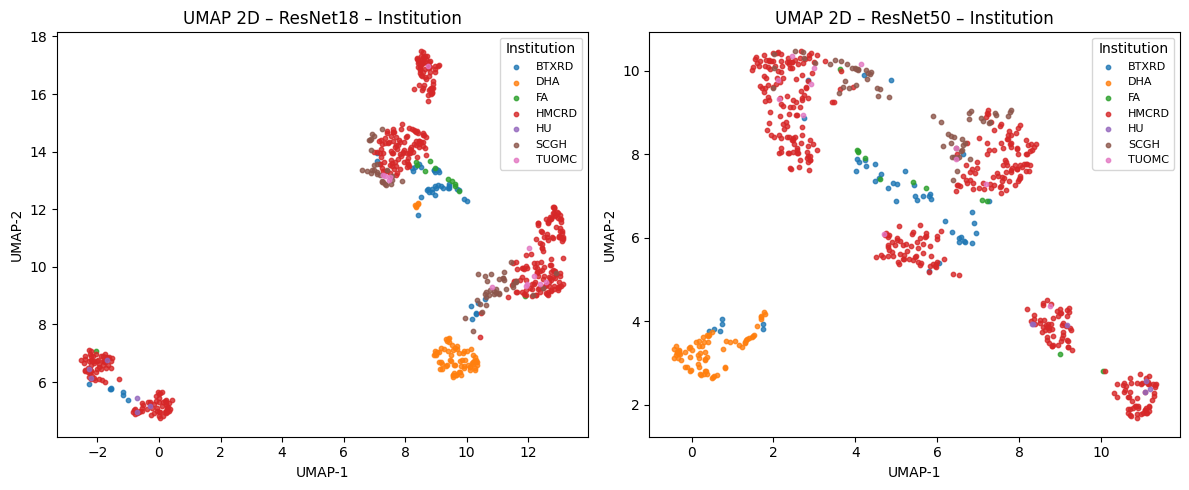

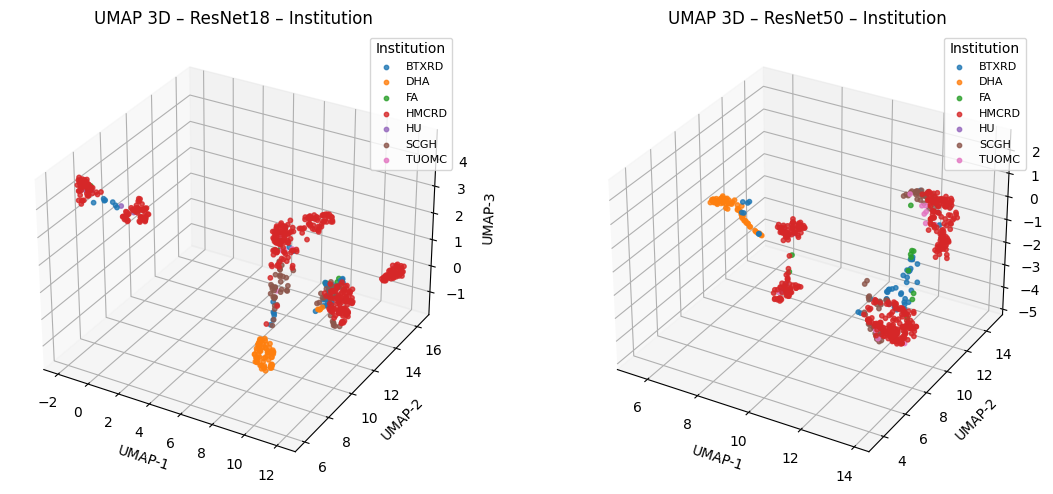

In [47]:
labels_institution = df18["InstitutionName"].values

plot_umap_2d(
    U18_2d, U50_2d,
    labels_institution,
    "Institution",
    is_categorical=True
)

plot_umap_3d(
    U18_3d, U50_3d,
    labels_institution,
    "Institution",
    is_categorical=True
)


In [48]:
# we'll work on df18 as the reference table
dfm = df18.copy()

# --- Parse ImagerPixelSpacing "[0.149, 0.149]" → px_row, px_col
def parse_vec2(x):
    try:
        v = ast.literal_eval(str(x))
        if isinstance(v, (list, tuple)) and len(v) == 2:
            return float(v[0]), float(v[1])
    except Exception:
        pass
    return np.nan, np.nan

px_vals = dfm["ImagerPixelSpacing"].apply(parse_vec2)
dfm["px_row"] = px_vals.apply(lambda v: v[0])
dfm["px_col"] = px_vals.apply(lambda v: v[1])

# --- Parse [Rows, Columns] "[1670, 2010]" → rows, cols
def parse_int2(x):
    try:
        v = ast.literal_eval(str(x))
        if isinstance(v, (list, tuple)) and len(v) == 2:
            return int(v[0]), int(v[1])
    except Exception:
        pass
    return np.nan, np.nan

rc_vals = dfm["[Rows, Columns]"].apply(parse_int2)
dfm["rows"] = rc_vals.apply(lambda v: v[0])
dfm["cols"] = rc_vals.apply(lambda v: v[1])



# --- continuous metadata columns
meta_cont_cols = [
    "PatientAge",
    "StudyDate (Days)",
    "px_row", "px_col",
    "rows", "cols",
]

meta_cat_cols = [
    "PatientSex",
    "InstitutionName",  # used as feature but we won't plot it
    "side",
]

# 1) Make sure all continuous columns are numeric
for col in meta_cont_cols:
    # turn things like "Unknown", "", etc. into NaN
    dfm[col] = pd.to_numeric(dfm[col], errors="coerce")

# 2) Now we can safely fill NaNs with the column mean
dfm[meta_cont_cols] = dfm[meta_cont_cols].fillna(dfm[meta_cont_cols].mean())

# 3) Categorical: replace NaN with "Unknown"
dfm[meta_cat_cols] = dfm[meta_cat_cols].fillna("Unknown")

# 4) One-hot encode categorical
meta_cat = pd.get_dummies(dfm[meta_cat_cols], drop_first=False)

# 5) Standardize continuous metadata
from sklearn.preprocessing import StandardScaler
scaler_meta = StandardScaler()
meta_cont_scaled = scaler_meta.fit_transform(dfm[meta_cont_cols])

# 6) Final metadata matrix
META = np.hstack([meta_cont_scaled, meta_cat.values])
print("META shape:", META.shape)


META shape: (618, 18)


In [49]:
Z50 = np.hstack([X50_scaled, META])

print("Z50:", Z50.shape)

Z50: (618, 2066)


In [50]:
def plot_umap2d(pts, labels, title, cmap="viridis", categorical=False):
    plt.figure(figsize=(8,6))
    if categorical:
        plt.scatter(pts[:,0], pts[:,1], c=labels, cmap="coolwarm", s=12)
    else:
        plt.scatter(pts[:,0], pts[:,1], c=labels, cmap=cmap, s=12)
    plt.colorbar()
    plt.title(title)
    plt.show()

# Fit UMAP 2D
umap2d = umap.UMAP(
    n_neighbors=20,
    min_dist=0.1,
    metric="euclidean",
    n_components=2,
    random_state=42
).fit_transform(Z50)

print("UMAP 2D:", umap2d.shape)


/usr/local/lib/python3.11/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP 2D: (618, 2)


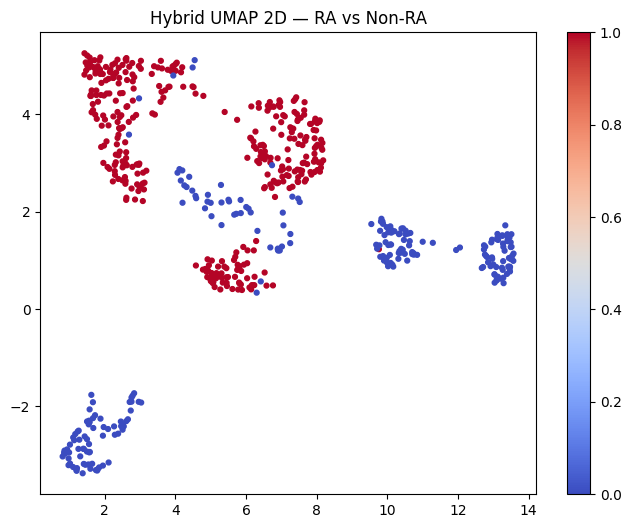

In [51]:
plot_umap2d(umap2d, dfm["IsRA"], "Hybrid UMAP 2D — RA vs Non-RA", categorical=True)


**The hybrid UMAP projection combining CNN features (ResNet-50) and metadata produces a very clear and striking separation between RA and non-RA patients. Two distinct manifolds emerge: on the left, a dense and compact region containing almost exclusively non-RA samples, and on the right, a large, structured region composed almost entirely of RA samples. The boundary between these two populations is sharp, with minimal overlap, indicating that the hybrid feature space encodes robust diagnostic information. The fact that UMAP is unsupervised makes this result even more significant: the embedding naturally organizes patients by their RA status without being given label information during dimensionality reduction. This strongly suggests that RA pathology induces consistent and detectable patterns in the radiographs, and that the metadata enriches these representations without distorting the underlying structure. Such a clean separation validates the feasibility of building a highly accurate RA classifier and demonstrates that the hybrid embedding captures clinically meaningful disease signatures.**

/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  name : str


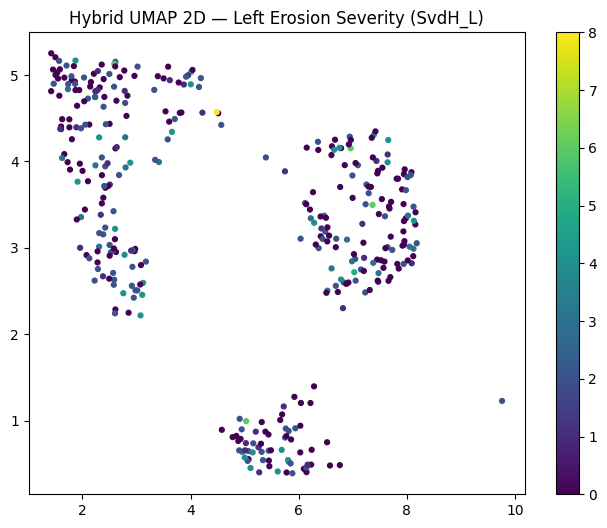

In [52]:
plot_umap2d(umap2d, dfm["SvdH_L"], "Hybrid UMAP 2D — Left Erosion Severity (SvdH_L)")



The hybrid UMAP 2D projection shows that erosion severity (SvdH_L) is distributed in a structured but not strictly linear manner across the manifold. Most samples exhibit mild or no erosion (dark purple), which cluster together in several dense regions of the embedding. However, the presence of scattered moderate and higher-severity samples (green/yellow) along transition zones between clusters suggests that the hybrid feature space still encodes progressive structural changes associated with increasing joint damage. Rather than forming a single continuous gradient, severity appears embedded within local subregions of RA clusters, indicating that erosion severity is a secondary factor relative to the primary RA vs non-RA separation.

The fact that UMAP does not collapse severe cases into a single axis reflects the complexity of RA pathology: erosion increases heterogeneously across different joints and patients, creating multiple severity patterns rather than a single progression path. Still, the occurrence of higher-severity points at the boundaries of RA subclusters demonstrates that the hybrid embeddings capture clinically meaningful cues of bone degradation. This reinforces the suitability of the hybrid representation for downstream severity prediction, even if severity manifests more subtly than binary RA status.


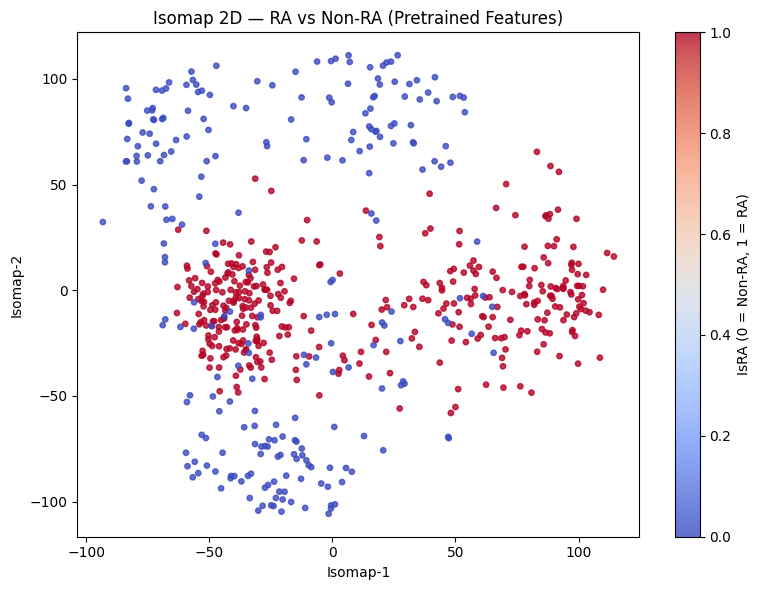

In [53]:
from sklearn.manifold import Isomap
# Labels RA
labels_ra = dfm["IsRA"].values   # 0 = Non-RA, 1 = RA

# Isomap 2D
iso2d_ra = Isomap(
    n_neighbors=20,
    n_components=2
).fit_transform(Z50)

# Plot
plt.figure(figsize=(8,6))
scatter = plt.scatter(
    iso2d_ra[:,0],
    iso2d_ra[:,1],
    c=labels_ra,
    cmap="coolwarm",
    s=15,
    alpha=0.8
)

plt.xlabel("Isomap-1")
plt.ylabel("Isomap-2")
plt.title("Isomap 2D — RA vs Non-RA (Pretrained Features)")
plt.colorbar(scatter, label="IsRA (0 = Non-RA, 1 = RA)")
plt.tight_layout()
plt.show()


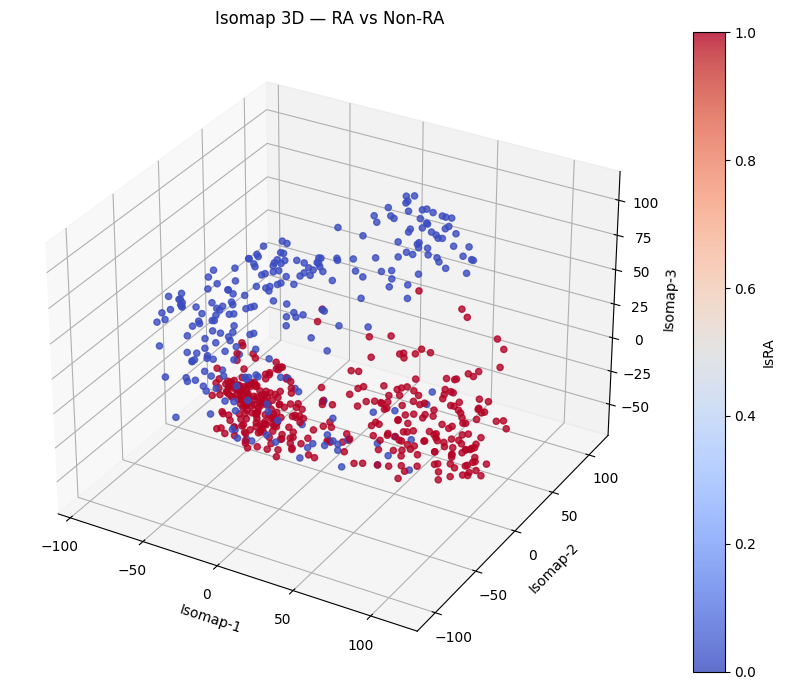

In [54]:
from mpl_toolkits.mplot3d import Axes3D

iso3d_ra = Isomap(
    n_neighbors=20,
    n_components=3
).fit_transform(Z50)

fig = plt.figure(figsize=(9,7))
ax = fig.add_subplot(111, projection='3d')

p = ax.scatter(
    iso3d_ra[:,0],
    iso3d_ra[:,1],
    iso3d_ra[:,2],
    c=labels_ra,
    cmap="coolwarm",
    s=20,
    alpha=0.8
)

ax.set_xlabel("Isomap-1")
ax.set_ylabel("Isomap-2")
ax.set_zlabel("Isomap-3")
ax.set_title("Isomap 3D — RA vs Non-RA")

fig.colorbar(p, label="IsRA")
plt.tight_layout()
plt.show()


In [55]:
from mpl_toolkits.mplot3d import Axes3D

In [56]:
umap3d = umap.UMAP(
    n_neighbors=20,
    min_dist=0.1,
    metric="euclidean",
    n_components=3,
    random_state=42
).fit_transform(Z50)

print("UMAP 3D:", umap3d.shape)

/usr/local/lib/python3.11/dist-packages/umap/umap_.py:1952: UserWarning: n_jobs value 1 overridden to 1 by setting random_state. Use no seed for parallelism.
  warn(


UMAP 3D: (618, 3)


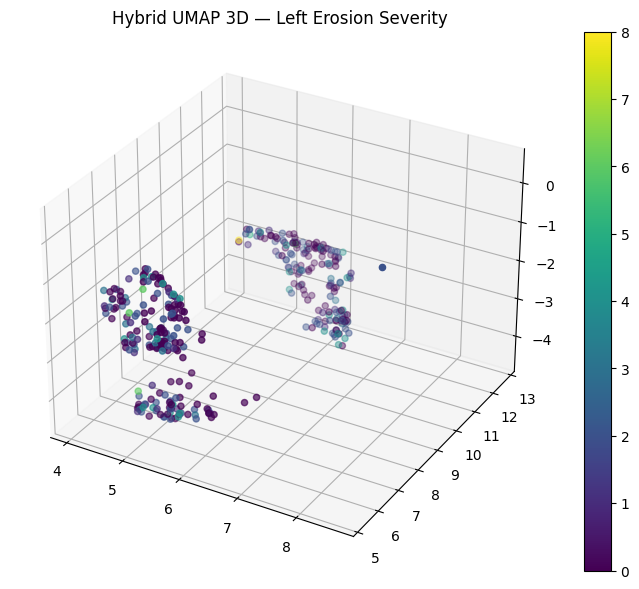

In [57]:
def plot_umap3d(pts, labels, title):
    fig = plt.figure(figsize=(9,7))
    ax = fig.add_subplot(111, projection='3d')
    p = ax.scatter(pts[:,0], pts[:,1], pts[:,2],
                   c=labels, cmap="viridis", s=20)
    fig.colorbar(p)
    ax.set_title(title)
    plt.show()

plot_umap3d(umap3d, dfm["SvdH_L"], "Hybrid UMAP 3D — Left Erosion Severity")

The 3D UMAP projection of the hybrid feature space reveals a more detailed structural organization of erosion severity compared to the 2D version. While most samples present low SvdH_L scores (purple), the spatial distribution shows that erosion severity is not random: moderate-to-high erosion cases (green/yellow) consistently appear at the outer edges or transitional regions between dense patient clusters. This suggests that the hybrid embedding captures gradual morphological changes associated with structural joint deterioration, even if these changes do not dominate the global geometry as strongly as the RA vs non-RA separation.

In 3D space, clusters of mild cases remain tightly grouped, indicating that patients with minimal erosion share highly similar radiographic patterns. By contrast, elevated erosion scores create local divergence paths, where points fan out in specific directions — a possible reflection of heterogeneous ways erosion progresses in RA patients. This aligns with clinical understanding: erosion severity does not follow a single linear trajectory but varies widely across joints and individuals.

The emergence of these subtle severity gradients in 3D confirms that the hybrid embedding retains meaningful information about joint damage, making it suitable for downstream regression or ordinal prediction of erosion severity, even though the separation is less pronounced than the RA diagnostic split.

In [58]:
from sklearn.manifold import Isomap


/usr/local/lib/python3.11/dist-packages/matplotlib/colors.py:721: RuntimeWarning: invalid value encountered in less
  name : str


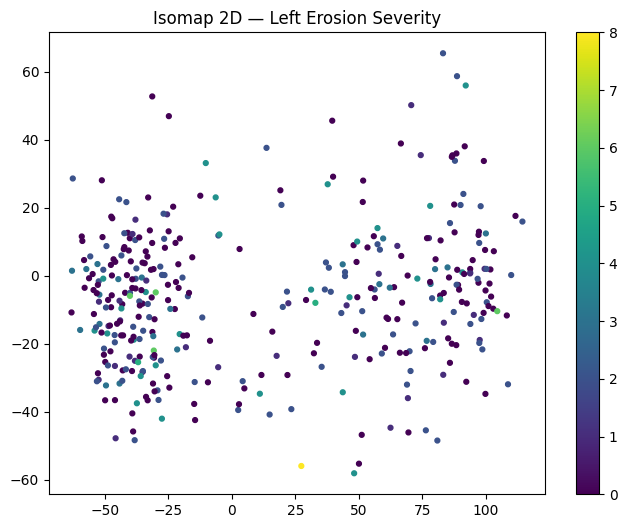

In [59]:
iso2d = Isomap(
    n_neighbors=20,
    n_components=2
).fit_transform(Z50)

plot_umap2d(iso2d, dfm["SvdH_L"], "Isomap 2D — Left Erosion Severity")


The Isomap 2D projection of the hybrid feature space shows a much flatter and more dispersed structure compared to the UMAP embeddings. Instead of forming compact and well-defined clusters, the samples are spread across a broad manifold with substantial overlap between different erosion severity levels. Most points cluster densely around low severity (purple values), while moderate and higher-severity samples (green/yellow) appear sporadically throughout the space without forming a clearly ordered progression.

This behavior reflects the nature of Isomap: by preserving global geodesic distances, the method tends to unfold the manifold into a stretched, continuous plane. As a consequence, subtle variations such as erosion severity do not produce strong geometric warping in the embedding. Since severity is a secondary phenomenon relative to overall disease status, the Isomap projection does not reveal a smooth severity trajectory or distinct severity clusters. Instead, it confirms that erosion progression is heterogeneous and non-linear, occurring in multiple directions within the disease manifold rather than along a single pathway.

Overall, the Isomap result complements the UMAP analysis:

UMAP reveals local structure, showing how severity varies inside RA subclusters.

Isomap reveals global structure, confirming that erosion severity does not follow a single dominant anatomical or clinical progression curve.

This reinforces the conclusion that erosion prediction must rely on local features and joint-specific cues, not on global geometric distances alone.

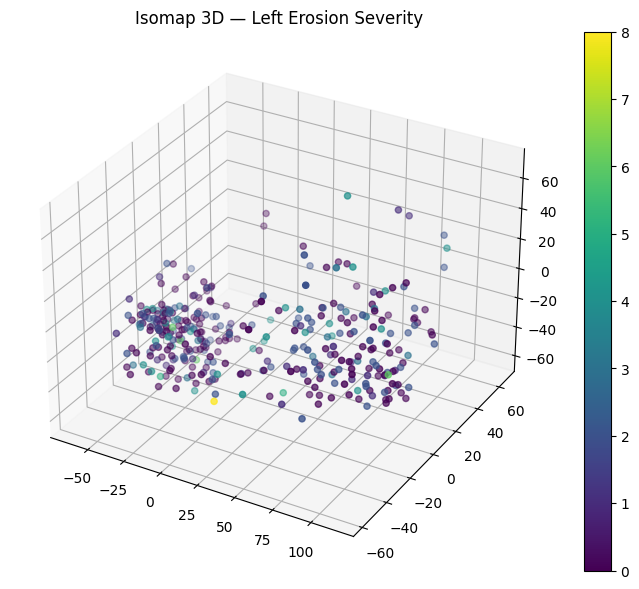

In [60]:
iso3d = Isomap(
    n_neighbors=20,
    n_components=3
).fit_transform(Z50)

plot_umap3d(iso3d, dfm["SvdH_L"], "Isomap 3D — Left Erosion Severity")


The 3D Isomap embedding provides a global view of the manifold geometry, and the visualization confirms the same pattern observed in 2D: erosion severity does not organize into a clear gradient or trajectory, but instead appears scattered across the embedding. While low-severity cases (dark purple) dominate and cluster loosely, moderate and high severity points (green/yellow) are distributed irregularly, showing no dominant axis of progression.

This behavior is expected from Isomap, which preserves global geodesic structure rather than optimizing local neighborhood separation. Because erosion severity is a local, joint-specific pathology with heterogeneous presentation across patients, it does not induce strong deformation of the global manifold. As a result, the Isomap embedding unfolds the data into a broad, stretched 3D structure where severity acts as a secondary, weakly expressed factor. There is no single direction in which severity increases; instead, small pockets of higher severity appear embedded within the general cloud of RA patients.

This confirms two key insights:

1. Severity prediction requires local features, not global geometry.

Erosion severity cannot be inferred from global distances in the embedding space; it must rely on specific radiographic features captured at the joint level.

2. RA vs non-RA is the dominant global structure.

The embedding preserves the overall diagnostic separation, but within the RA space, severity evolves in multiple independent directions, consistent with the clinical variability of RA progression.

Overall, the 3D Isomap visualization reinforces that Isomap is useful for global manifold inspection, but UMAP remains more informative for capturing local severity gradients relevant to erosion scoring.

In [61]:
# ================== CHEMINS CORRIGÉS ==================
BASE_MASK_DIR = Path("/kaggle/input/ram-w600-local/RAM-W600/BoneSegmentation/masks")
RAW_DIR = Path("/kaggle/input/ram-w600-local/RAM-W600/BoneSegmentation/images")

OUT_512 = Path("/kaggle/working/preprocessed_512")
OUT_ROIS = Path("/kaggle/working/joint_rois_224")

OUT_512.mkdir(parents=True, exist_ok=True)
OUT_ROIS.mkdir(parents=True, exist_ok=True)

In [62]:
# ================== 1. Récupérer TOUS les masques dans tous les splits ==================
all_mask_paths = list(BASE_MASK_DIR.rglob("*.npy"))
print(f"{len(all_mask_paths)} masques .npy trouvés dans train/val/test")

stems_with_mask = [p.stem for p in all_mask_paths]
print(f"{len(stems_with_mask)} stems uniques avec masque GT")

618 masques .npy trouvés dans train/val/test
618 stems uniques avec masque GT


In [63]:
# ================== 2. Préprocessing 512x512 avec contraste fort ==================
def preprocess_image(stem):
    # Recherche l'image correspondante (extension variable)
    possible_imgs = list(RAW_DIR.glob(f"{stem}.*"))
    if not possible_imgs:
        return None
    img_path = possible_imgs[0]
    
    out_path = OUT_512 / (stem + ".png")
    if out_path.exists():
        return str(out_path)
    
    img = cv2.imread(str(img_path), cv2.IMREAD_GRAYSCALE)
    if img is None:
        return None
    
    img_resized = cv2.resize(img, (512, 512), interpolation=cv2.INTER_LINEAR)
    
    clahe = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(8,8))
    img_eq = clahe.apply(img_resized)
    
    cv2.imwrite(str(out_path), img_eq)
    return str(out_path)

In [64]:
preprocessed_paths = {}
for stem in tqdm(stems_with_mask, desc="Préprocessing images avec masque GT"):
    path_512 = preprocess_image(stem)
    if path_512:
        preprocessed_paths[stem] = path_512

print(f"{len(preprocessed_paths)} images prétraitées avec succès.")

Préprocessing images avec masque GT:   0%|          | 0/618 [00:00<?, ?it/s]

618 images prétraitées avec succès.


In [65]:
# ================== 3. Extraction des 3 ROIs ==================
def extract_3_joint_rois(stem, img_512_path):
    img = cv2.imread(img_512_path, cv2.IMREAD_GRAYSCALE)
    
    # Recherche le masque correspondant dans tous les splits
    possible_masks = list(BASE_MASK_DIR.rglob(f"{stem}.npy"))
    if not possible_masks:
        return []
    mask_path = possible_masks[0]
    
    mask = np.load(mask_path)
    if mask.ndim == 3:  # multi-canal
        mask_bin = (mask.sum(axis=0) > 0).astype(np.uint8)
    else:
        mask_bin = (mask > 0).astype(np.uint8)
    
    mask_255 = mask_bin * 255
    
    contours, _ = cv2.findContours(mask_255, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return []
    
    c = max(contours, key=cv2.contourArea)
    x, y, w, h = cv2.boundingRect(c)
    
    pad = 80
    x1 = max(0, x - pad)
    y1 = max(0, y - pad)
    x2 = min(512, x + w + pad)
    y2 = min(512, y + h + pad)
    
    crop = img[y1:y2, x1:x2]
    
    clahe = cv2.createCLAHE(clipLimit=5.0, tileGridSize=(8,8))
    crop_clahe = clahe.apply(crop)
    crop_final = cv2.normalize(crop_clahe, None, 0, 255, cv2.NORM_MINMAX)
    
    H, W = crop_final.shape
    xs = np.linspace(0, W, 4, dtype=int)
    
    records = []
    for i in range(3):
        sx1, sx2 = xs[i], xs[i+1]
        if sx2 - sx1 < 40:
            continue
        
        sub = crop_final[:, sx1:sx2]
        sub_resized = cv2.resize(sub, (224, 224), interpolation=cv2.INTER_LINEAR)
        
        roi_name = f"{stem}_joint{i+1}.png"
        cv2.imwrite(str(OUT_ROIS / roi_name), sub_resized)
        
        records.append({
            "stem": stem,
            "roi_filename": roi_name,
            "joint_index": i+1,
            "roi_path": str(OUT_ROIS / roi_name)
        })
    
    return records

In [66]:
# ================== 4. Extraction ==================
all_roi_records = []
for stem, path_512 in tqdm(preprocessed_paths.items(), desc="Extraction 3 ROIs"):
    recs = extract_3_joint_rois(stem, path_512)
    all_roi_records.extend(recs)

print(f"{len(all_roi_records)} ROIs extraits au total (devrait être ~1854 si 618 masques)")

Extraction 3 ROIs:   0%|          | 0/618 [00:00<?, ?it/s]

1854 ROIs extraits au total (devrait être ~1854 si 618 masques)


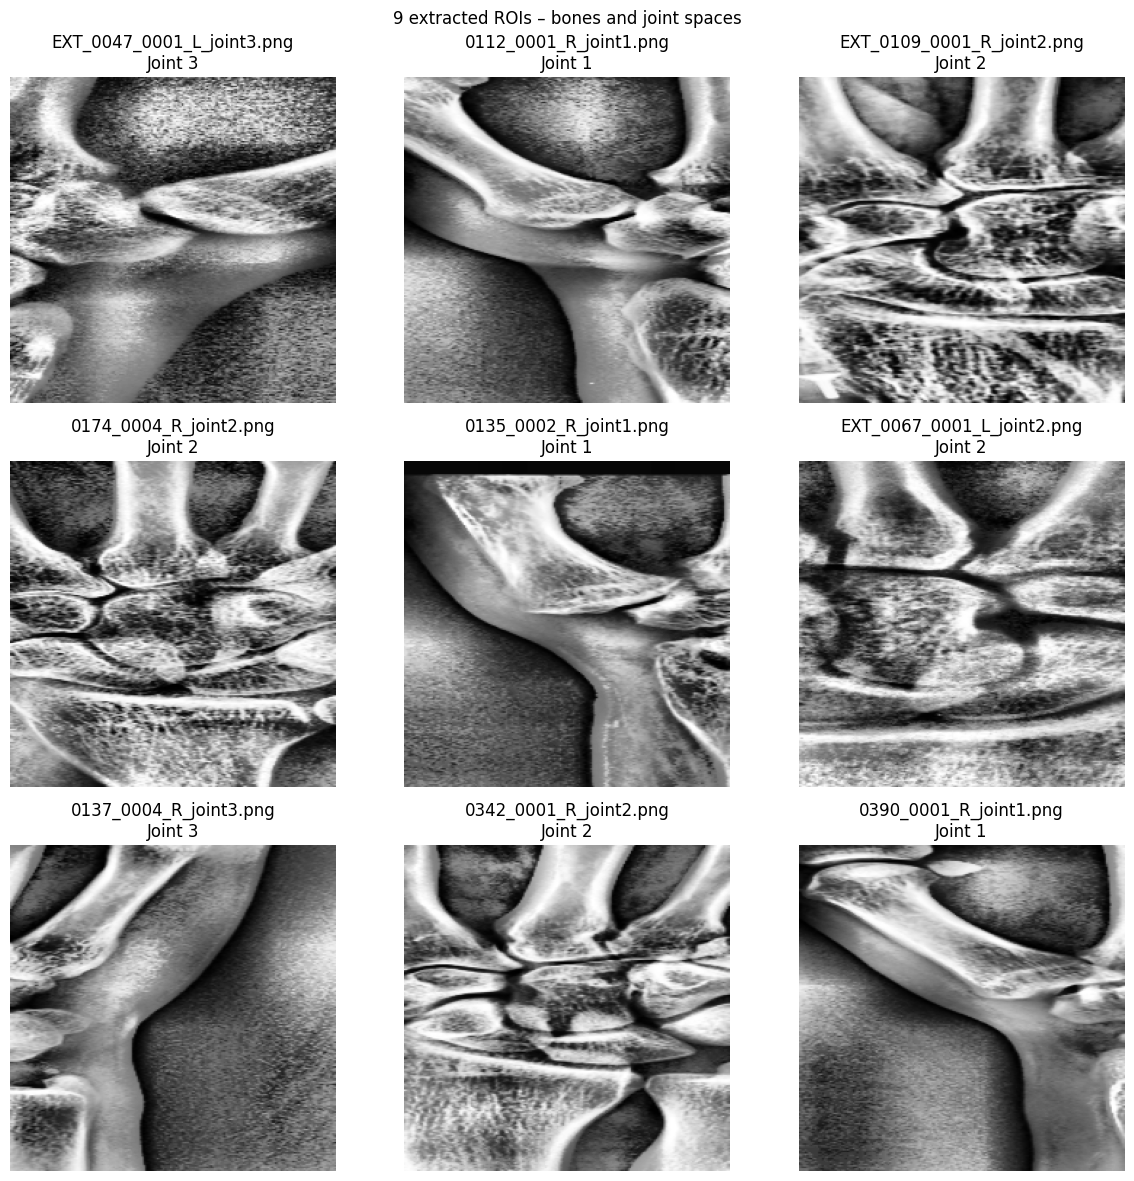

In [67]:
df_rois = pd.DataFrame(all_roi_records)
df_rois.to_csv("/kaggle/working/joint_rois_manifest_final.csv", index=False)

# ================== 5. Vérification visuelle ==================
if len(df_rois) > 0:
    samples = df_rois.sample(min(9, len(df_rois)), random_state=42)
    
    fig, axes = plt.subplots(3, 3, figsize=(12, 12))
    axes = axes.ravel()
    
    for i, row in enumerate(samples.itertuples()):
        img = cv2.imread(row.roi_path, cv2.IMREAD_GRAYSCALE)
        axes[i].imshow(img, cmap="gray")
        axes[i].set_title(f"{row.roi_filename}\nJoint {row.joint_index}")
        axes[i].axis("off")
    
    for j in range(i+1, 9):
        axes[j].axis("off")
    
    plt.suptitle("9 extracted ROIs – bones and joint spaces")
    plt.tight_layout()
    plt.show()
else:
    print("Aucun ROI extrait – vérifie les chemins.")

In [68]:
from scipy.ndimage import distance_transform_edt
from skimage.segmentation import watershed
from skimage.feature import peak_local_max

# Chemins
ROI_DIR = Path("/kaggle/working/joint_rois_224")
FIGURE_DIR = Path("/kaggle/working/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

# Charge ton manifest (ajuste le nom si différent)
df_rois = pd.read_csv("/kaggle/working/joint_rois_manifest_final.csv")

In [69]:
# Fonction pour séparer les layers (upper / lower bone)
def separate_bone_layers(roi_img):
    # Binarisation simple + distance transform
    _, binary = cv2.threshold(roi_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    distance = distance_transform_edt(binary)
    
    # Local maxima pour markers
    local_maxi = peak_local_max(distance, min_distance=20, labels=binary)
    markers = np.zeros(binary.shape, dtype=np.int32)
    markers[tuple(local_maxi.T)] = np.arange(1, len(local_maxi) + 1)
    
    # Watershed
    labels = watershed(-distance, markers, mask=binary)
    
    # Sépare en 2 layers (la plus haute et la plus basse)
    upper = np.zeros_like(roi_img)
    lower = np.zeros_like(roi_img)
    
    # Assume layer 1 = upper, layer 2 = lower (basé sur position y)
    if len(np.unique(labels)) >= 2:
        props = []
        for lbl in np.unique(labels)[1:]:
            mask_lbl = (labels == lbl)
            y_mean = np.mean(np.where(mask_lbl)[0])
            props.append((y_mean, mask_lbl))
        
        props.sort(key=lambda x: x[0])  # tri par position y (haut → bas)
        upper = props[0][1] * roi_img
        lower = props[1][1] * roi_img if len(props) > 1 else np.zeros_like(roi_img)
    
    reconstructed = upper + lower
    return upper, lower, reconstructed

# Fonction pour générer synthetic JSN
def generate_synthetic_jsn(roi_img, upper, lower, shift_pixels=4):
    # Shift la lower layer vers le haut (rétrécit l'espace)
    shifted_lower = np.roll(lower, shift_pixels, axis=0)
    shifted_lower[:shift_pixels, :] = 0  # nettoie le haut
    
    synthetic = upper + shifted_lower
    return synthetic

In [70]:
# Chemins (inchangés)
ROI_DIR = Path("/kaggle/working/joint_rois_224")
FIGURE_DIR = Path("/kaggle/working/figures")
FIGURE_DIR.mkdir(parents=True, exist_ok=True)

df_rois = pd.read_csv("/kaggle/working/joint_rois_manifest_final.csv")  # ou ton nom exact

# Fonction bone layer separation (inchangée)
def separate_bone_layers(roi_img):
    _, binary = cv2.threshold(roi_img, 0, 255, cv2.THRESH_BINARY + cv2.THRESH_OTSU)
    distance = distance_transform_edt(binary)
    
    local_maxi = peak_local_max(distance, min_distance=20, labels=binary)
    markers = np.zeros(binary.shape, dtype=np.int32)
    markers[tuple(local_maxi.T)] = np.arange(1, len(local_maxi) + 1)
    
    labels = watershed(-distance, markers, mask=binary)
    
    upper = np.zeros_like(roi_img)
    lower = np.zeros_like(roi_img)
    
    if len(np.unique(labels)) >= 2:
        props = []
        for lbl in np.unique(labels)[1:]:
            mask_lbl = (labels == lbl)
            y_mean = np.mean(np.where(mask_lbl)[0])
            props.append((y_mean, mask_lbl))
        
        props.sort(key=lambda x: x[0])
        upper = props[0][1] * roi_img
        lower = props[1][1] * roi_img if len(props) > 1 else np.zeros_like(roi_img)
    
    reconstructed = upper + lower
    return upper.astype(np.uint8), lower.astype(np.uint8), reconstructed.astype(np.uint8)

# Fonction synthetic JSN (inchangée)
def generate_synthetic_jsn(roi_img, upper, lower, shift_pixels=4):
    shifted_lower = np.roll(lower, -shift_pixels, axis=0)  # négatif pour rétrécir vers le haut
    shifted_lower[-shift_pixels:, :] = 0
    synthetic = upper + shifted_lower
    return synthetic.astype(np.uint8)

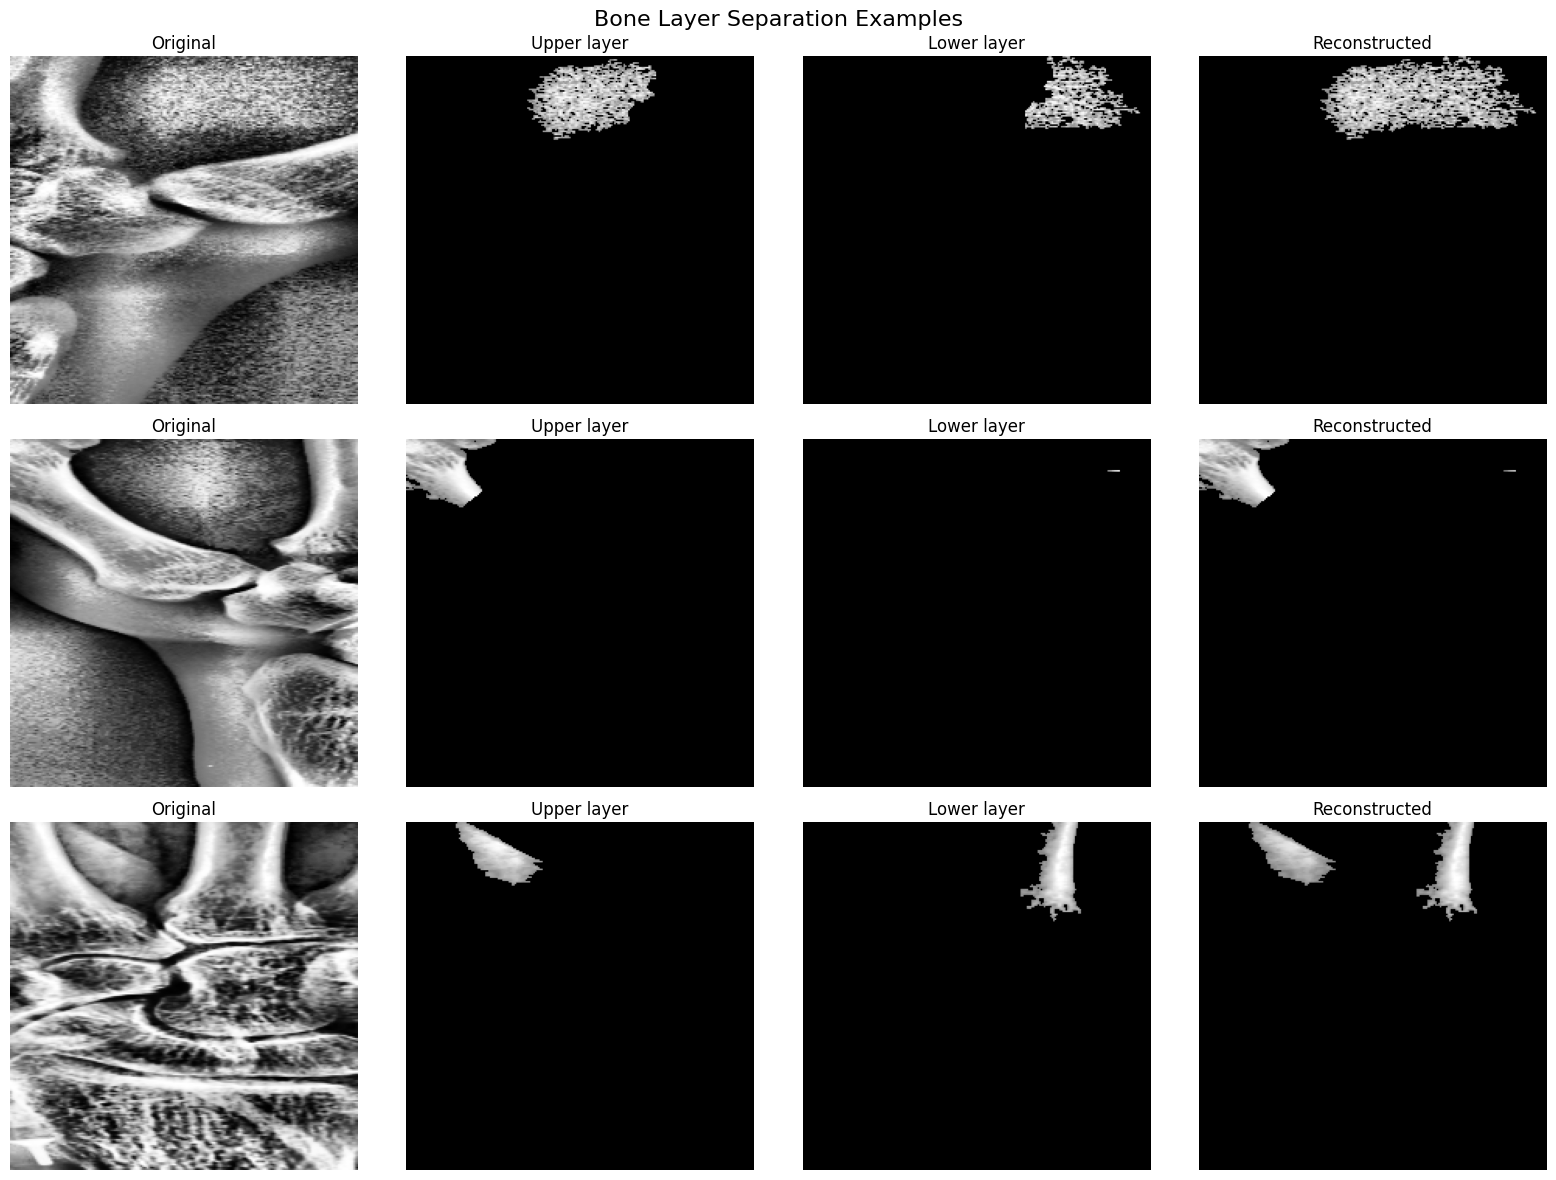

In [71]:
# 1. Figure bone layer separation → PNG
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.ravel()

samples = df_rois.sample(3, random_state=42)

for i, row in enumerate(samples.itertuples()):
    roi = cv2.imread(str(ROI_DIR / row.roi_filename), cv2.IMREAD_GRAYSCALE)
    
    upper, lower, recon = separate_bone_layers(roi)
    
    images = [roi, upper, lower, recon]
    titles = ["Original", "Upper layer", "Lower layer", "Reconstructed"]
    
    for j in range(4):
        axes[i*4 + j].imshow(images[j], cmap='gray')
        axes[i*4 + j].set_title(titles[j])
        axes[i*4 + j].axis('off')

plt.suptitle("Bone Layer Separation Examples", fontsize=16)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "bone_layer_separation_examples.png", dpi=300, bbox_inches='tight')
plt.show()


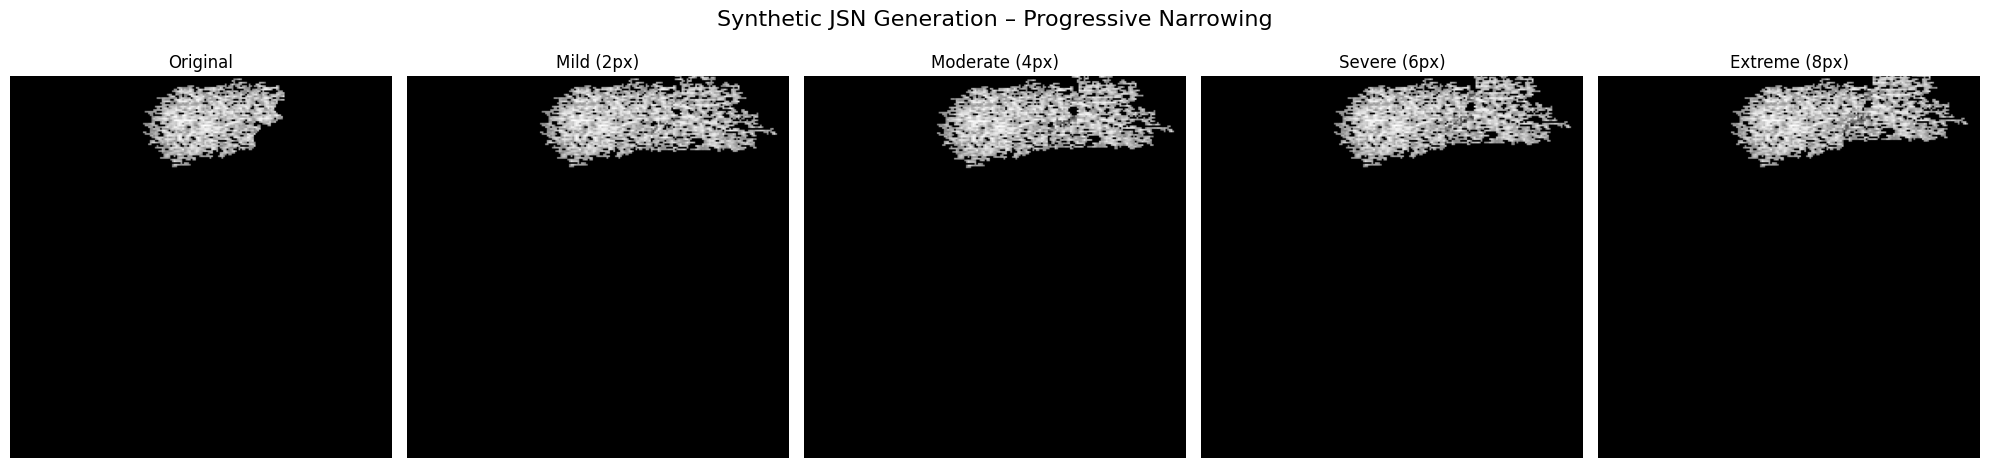

In [72]:
# 2. Figure synthetic JSN → PNG
fig, axes = plt.subplots(1, 5, figsize=(20, 5))

sample_roi = cv2.imread(str(ROI_DIR / samples.iloc[0].roi_filename), cv2.IMREAD_GRAYSCALE)
upper, lower, _ = separate_bone_layers(sample_roi)

shifts = [0, 2, 4, 6, 8]
titles = ["Original", "Mild (2px)", "Moderate (4px)", "Severe (6px)", "Extreme (8px)"]

for i, shift in enumerate(shifts):
    synth = generate_synthetic_jsn(sample_roi, upper, lower, shift)
    axes[i].imshow(synth, cmap='gray')
    axes[i].set_title(titles[i])
    axes[i].axis('off')

plt.suptitle("Synthetic JSN Generation – Progressive Narrowing", fontsize=16)
plt.tight_layout()
plt.savefig(FIGURE_DIR / "synthetic_jsn_progression.png", dpi=300, bbox_inches='tight')
plt.show()

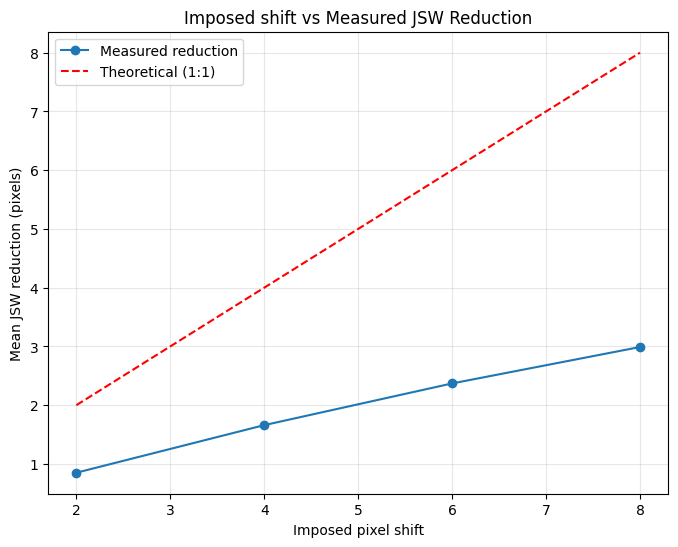

In [73]:
# 3. Figure shift vs JSW → PNG
jsn_deltas = []
shifts_test = [0, 2, 4, 6, 8]

for row in df_rois.sample(100, random_state=123).itertuples():
    roi = cv2.imread(str(ROI_DIR / row.roi_filename), cv2.IMREAD_GRAYSCALE)
    upper, lower, _ = separate_bone_layers(roi)
    
    # JSW original (distance moyenne entre bords)
    mask_upper = upper > 50
    mask_lower = lower > 50
    if mask_upper.any() and mask_lower.any():
        y_upper_max = np.max(np.where(mask_upper)[0])
        y_lower_min = np.min(np.where(mask_lower)[0])
        jsw_orig = y_lower_min - y_upper_max
        
        deltas = []
        for shift in shifts_test[1:]:
            synth_lower = np.roll(lower, -shift, axis=0)
            synth_lower[-shift:, :] = 0
            mask_synth = synth_lower > 50
            if mask_synth.any():
                y_synth_min = np.min(np.where(mask_synth)[0])
                jsw_synth = y_synth_min - y_upper_max
                deltas.append(jsw_orig - jsw_synth)
        
        jsn_deltas.append(deltas)

# Moyenne sur 100 ROIs
mean_deltas = np.mean(jsn_deltas, axis=0)

plt.figure(figsize=(8, 6))
plt.plot(shifts_test[1:], mean_deltas, 'o-', label='Measured reduction')
plt.plot(shifts_test[1:], shifts_test[1:], 'r--', label='Theoretical (1:1)')
plt.xlabel("Imposed pixel shift")
plt.ylabel("Mean JSW reduction (pixels)")
plt.title("Imposed shift vs Measured JSW Reduction")
plt.legend()
plt.grid(True, alpha=0.3)
plt.savefig(FIGURE_DIR / "jsn_shift_vs_jsw.png", dpi=300, bbox_inches='tight')
plt.show()

In [74]:
import scipy.ndimage as ndimage
from skimage.morphology import skeletonize
from scipy.optimize import curve_fit

In [75]:
base_path = Path("/kaggle/input/ram-w600-local/RAM-W600")
masks_test_path = base_path / "BoneSegmentation" / "masks" / "test"

pixel_spacing = 0.15

JOINT_PAIRS = [(1,6),(1,4),(6,0),(4,0),(0,8),(0,11)]

bone_name_dict = {0: "Capitate", 1: "DistalRadius", 2: "DistalUlna", 3: "Hamate", 4: "Lunate",
                  5: "Pisiform&Triquetrum", 6: "Scaphoid", 7: "Trapezium", 8: "Trapezoid",
                  9: "metacarpal1st", 10: "metacarpal2nd", 11: "metacarpal3rd",
                  12: "metacarpal4th", 13: "metacarpal5th"}

def measure_jsw_subpixel(mask1, mask2):
    dist1 = ndimage.distance_transform_edt(~mask1)
    dist2 = ndimage.distance_transform_edt(~mask2)
    contact = (dist1 > 0) & (dist2 > 0)
    if not np.any(contact):
        return None
    
    distances = dist1[contact] + dist2[contact]
    min_jsw = distances.min()
    min_jsw = max(min_jsw, 0.0)
    
    skeleton = skeletonize(contact)
    if np.any(skeleton):
        profile = (dist1 + dist2)[skeleton]
        if len(profile) >= 3:
            idx_min = np.argmin(profile)
            x = np.arange(len(profile))
            try:
                popt, _ = curve_fit(lambda x,a,b,c: a*(x-b)**2 + c, 
                                    x[max(0,idx_min-5):idx_min+6], 
                                    profile[max(0,idx_min-5):idx_min+6], 
                                    p0=[1.0, idx_min, profile[idx_min]], maxfev=2000)
                sub_min = popt[2]
                min_jsw = max(sub_min, min_jsw)
            except:
                pass
    
    return {"min_mm": min_jsw * pixel_spacing}

In [76]:
test_files = sorted([f for f in os.listdir(masks_test_path) if f.endswith('.npy')])

results = []
for fname in test_files:
    gt_masks = np.load(masks_test_path / fname)
    if gt_masks.shape[0] != 14:
        gt_masks = gt_masks.transpose(2,0,1)
    
    for b1, b2 in JOINT_PAIRS:
        joint = f"{bone_name_dict[b1]}-{bone_name_dict[b2]}"
        res = measure_jsw_subpixel(gt_masks[b1]>0.5, gt_masks[b2]>0.5)
        if res:
            results.append({"fname": fname, "joint": joint, "min_mm": res["min_mm"]})

df_jsw_gt = pd.DataFrame(results)
df_jsw_gt.to_csv("/kaggle/working/jsw_gt_results.csv", index=False)

table_gt = df_jsw_gt.groupby("joint")["min_mm"].agg(["mean", "std"]).round(3)
print("Table JSW min sur annotations expertes (mm)")
print(table_gt)

Table JSW min sur annotations expertes (mm)
                          mean     std
joint                                 
Capitate-Trapezoid      29.642   4.230
Capitate-metacarpal3rd   8.819  10.330
DistalRadius-Lunate     16.093  11.168
DistalRadius-Scaphoid   11.235  10.548
Lunate-Capitate         15.440  12.619
Scaphoid-Capitate       27.640   6.100


In [77]:
results = []
for fname in test_files:
    gt_masks = np.load(masks_test_path / fname)
    if gt_masks.shape[0] != 14:
        gt_masks = gt_masks.transpose(2,0,1)
    
    for b1, b2 in JOINT_PAIRS:
        joint = f"{bone_name_dict[b1]}-{bone_name_dict[b2]}"
        res = measure_jsw_subpixel(gt_masks[b1]>0.5, gt_masks[b2]>0.5)
        if res:
            results.append({"fname": fname, "joint": joint, "min_mm": res["min_mm"]})

df_jsw_gt = pd.DataFrame(results)
table_gt = df_jsw_gt.groupby("joint")["min_mm"].agg(["mean", "std"]).round(3)
print(table_gt)

                          mean     std
joint                                 
Capitate-Trapezoid      29.642   4.230
Capitate-metacarpal3rd   8.819  10.330
DistalRadius-Lunate     16.093  11.168
DistalRadius-Scaphoid   11.235  10.548
Lunate-Capitate         15.440  12.619
Scaphoid-Capitate       27.640   6.100


In [78]:
# Chemins (adaptés à ton dataset Kaggle)
base_path = Path("/kaggle/input/ram-w600-local/RAM-W600")
masks_test_path = base_path / "BoneSegmentation" / "masks" / "test"

pixel_spacing = 0.15  # mm/pixel

JOINT_PAIRS = [(1,6), (1,4), (6,0), (4,0), (0,8), (0,11)]

bone_name_dict = {
    0: "Capitate", 1: "DistalRadius", 2: "DistalUlna", 3: "Hamate", 4: "Lunate",
    5: "Pisiform&Triquetrum", 6: "Scaphoid", 7: "Trapezium", 8: "Trapezoid",
    9: "metacarpal1st", 10: "metacarpal2nd", 11: "metacarpal3rd",
    12: "metacarpal4th", 13: "metacarpal5th"
}

In [79]:
def measure_jsw_subpixel(mask1, mask2):
    """
    Mesure sub-pixel du Joint Space Width (min seulement, car c'est le plus pertinent cliniquement)
    """
    dist1 = ndimage.distance_transform_edt(~mask1)
    dist2 = ndimage.distance_transform_edt(~mask2)
    contact = (dist1 > 0) & (dist2 > 0)
    
    if not np.any(contact):
        return None
    
    distances = dist1[contact] + dist2[contact]
    min_jsw = distances.min()
    min_jsw = max(min_jsw, 0.0)  # jamais négatif
    
    # Tentative d'affinage sub-pixel sur le profil du squelette
    skeleton = skeletonize(contact)
    if np.any(skeleton):
        profile = (dist1 + dist2)[skeleton]
        if len(profile) >= 3:
            idx_min = np.argmin(profile)
            x = np.arange(len(profile))
            # Plage plus large pour éviter covariance warning
            fit_range = slice(max(0, idx_min-5), idx_min+6)
            try:
                popt, _ = curve_fit(
                    lambda x, a, b, c: a*(x-b)**2 + c,
                    x[fit_range],
                    profile[fit_range],
                    p0=[1.0, idx_min, profile[idx_min]],
                    maxfev=3000
                )
                subpixel_min = popt[2]
                if subpixel_min > 0:
                    min_jsw = subpixel_min  # on prend l'affinage si positif
            except Exception:
                pass  # on garde le min classique si fit échoue
    
    return {"min_mm": min_jsw * pixel_spacing}

In [80]:
# Liste des fichiers test
test_files = sorted([f for f in os.listdir(masks_test_path) if f.endswith('.npy')])

print(f"Nombre de masques test trouvés : {len(test_files)}")

results = []
for fname in test_files:
    gt_masks = np.load(masks_test_path / fname)
    if gt_masks.shape[0] != 14:
        gt_masks = gt_masks.transpose(2, 0, 1)  # → (14, H, W)
    
    for b1, b2 in JOINT_PAIRS:
        joint = f"{bone_name_dict[b1]}-{bone_name_dict[b2]}"
        res = measure_jsw_subpixel(gt_masks[b1] > 0.5, gt_masks[b2] > 0.5)
        if res is not None:
            results.append({
                "fname": fname,
                "joint": joint,
                "min_mm": res["min_mm"]
            })

df_jsw_gt = pd.DataFrame(results)

if df_jsw_gt.empty:
    print("Aucun résultat valide calculé. Vérifie les masques / paires de joints.")
else:
    # Tableau récapitulatif
    table_gt = df_jsw_gt.groupby("joint")["min_mm"].agg(["mean", "std", "min", "max", "count"]).round(3)
    print("\nTable JSW min sur annotations expertes (GT) - test set")
    print(table_gt)
    
    # Sauvegarde
    df_jsw_gt.to_csv("/kaggle/working/jsw_gt_results.csv", index=False)
    print("\nRésultats sauvegardés dans /kaggle/working/jsw_gt_results.csv")

Nombre de masques test trouvés : 124

Table JSW min sur annotations expertes (GT) - test set
                          mean     std     min     max  count
joint                                                        
Capitate-Trapezoid      29.642   4.230  10.738  42.162    124
Capitate-metacarpal3rd   8.818  10.331   0.180  36.684    124
DistalRadius-Lunate     16.093  11.168   0.300  31.114    124
DistalRadius-Scaphoid   11.235  10.548   0.300  36.899    124
Lunate-Capitate         15.440  12.619   0.300  37.447    124
Scaphoid-Capitate       27.640   6.100   0.300  40.865    124

Résultats sauvegardés dans /kaggle/working/jsw_gt_results.csv


In [81]:
import os, json, random
from pathlib import Path

import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

import torchvision
from torchvision import transforms
from torchvision.models import resnet50, ResNet50_Weights

from sklearn.metrics import (
    roc_auc_score, average_precision_score,
    confusion_matrix, precision_recall_fscore_support,
    balanced_accuracy_score, matthews_corrcoef,
    roc_curve, precision_recall_curve
)
import matplotlib.pyplot as plt

In [82]:
# ------------------------
# 0) Reproducibility
# ------------------------
def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True

seed_everything(42)

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

Device: cuda


In [83]:
# ------------------------
# 1) Build dataset table
# ------------------------
BASE = Path("/kaggle/input/ram-w600-local/RAM-W600/SvdHBEScoreClassification")
JSON_GT = BASE / "JointBE_SvdH_GT.json"

SPLITS = ["train", "val", "test"]
BONES  = ["DistalRadius", "DistalUlna", "Lunate", "Metacarpal1st", "Scaphoid", "Trapzium"]

print("BASE exists:", BASE.exists())
print("JSON exists:", JSON_GT.exists())

BASE exists: True
JSON exists: True


In [84]:
with open(JSON_GT, "r") as f:
    data = json.load(f)

label_dict = {e["identifier"]: e["joints"] for e in data}

records, missing_ids, missing_files = [], 0, 0

for split in SPLITS:
    split_dir = BASE / split
    if not split_dir.exists():
        print("Missing split dir:", split_dir)
        continue

    for case_dir in split_dir.iterdir():
        if not case_dir.is_dir():
            continue
        identifier = case_dir.name

        if identifier not in label_dict:
            missing_ids += 1
            continue

        joints = label_dict[identifier]

        for bone in BONES:
            img_path = case_dir / f"{bone}.bmp"
            if not img_path.exists():
                missing_files += 1
                continue
            if bone not in joints:
                continue

            ero_label = int(joints[bone])
            records.append({
                "split": split,
                "identifier": identifier,
                "bone": bone,
                "image_path": str(img_path),
                "ero_label": ero_label,
                "ero_bin": int(ero_label > 0)   # binary target: erosion present?
            })


df = pd.DataFrame(records)
print("Rows:", len(df))
print("Missing identifiers in JSON:", missing_ids)
print("Missing BMP files:", missing_files)

print("\nBinary label distribution (global):")
print(df["ero_bin"].value_counts())

print("\nBinary label distribution by split:")
print(df.groupby(["split", "ero_bin"]).size().unstack(fill_value=0))

OUT_CSV = Path("/kaggle/working/ero_bone_dataset.csv")
df.to_csv(OUT_CSV, index=False)
print("\nSaved:", OUT_CSV)

Rows: 4800
Missing identifiers in JSON: 0
Missing BMP files: 0

Binary label distribution (global):
ero_bin
0    4380
1     420
Name: count, dtype: int64

Binary label distribution by split:
ero_bin     0    1
split             
test      877   83
train    3061  293
val       442   44

Saved: /kaggle/working/ero_bone_dataset.csv


In [85]:
print("\n🔹 Distribution des classes originales (SvH) par split:")
dist_ero_label = (
    df.groupby(["split", "ero_label"])
      .size()
      .unstack(fill_value=0)
      .sort_index(axis=1)
)
print(dist_ero_label)



🔹 Distribution des classes originales (SvH) par split:
ero_label     0    1    2   3  5
split                           
test        877   31   46   6  0
train      3061  134  137  15  7
val         442   20   23   1  0


In [86]:
df_train = df[df["split"] == "train"].reset_index(drop=True)
df_val   = df[df["split"] == "val"].reset_index(drop=True)
df_test  = df[df["split"] == "test"].reset_index(drop=True)

In [87]:
# ------------------------
# 2) Compute TRAIN mean/std (recommended in several medical imaging pipelines)
#    (We compute on resized tensors, before normalization.)
# ------------------------
class RawTensorDataset(Dataset):
    def __init__(self, df, size=224):
        self.df = df.reset_index(drop=True)
        self.tf = transforms.Compose([
            transforms.Resize((size, size)),
            transforms.ToTensor()
        ])
    def __len__(self):
        return len(self.df)
    def __getitem__(self, idx):
        img = Image.open(self.df.loc[idx, "image_path"]).convert("L").convert("RGB")
        return self.tf(img)

In [88]:
def compute_mean_std(df_train, batch_size=64):
    loader = DataLoader(
        RawTensorDataset(df_train),
        batch_size=batch_size, shuffle=False
    )
    n = 0
    mean = torch.zeros(3)
    var  = torch.zeros(3)

    for x in loader:
        b = x.size(0)
        x = x.view(b, 3, -1)
        mean += x.mean(dim=2).sum(dim=0)
        var  += x.var(dim=2).sum(dim=0)
        n += b

    mean /= n
    std = torch.sqrt(var / n)
    return mean.tolist(), std.tolist()

train_mean, train_std = compute_mean_std(df_train)
print("TRAIN mean:", train_mean)
print("TRAIN std :", train_std)

TRAIN mean: [0.7281309962272644, 0.7281309962272644, 0.7281309962272644]
TRAIN std : [0.1460001915693283, 0.1460001915693283, 0.1460001915693283]


In [89]:
class EROBoneDataset(Dataset):
    def __init__(self, df, augment=False, mean=None, std=None):
        self.df = df.reset_index(drop=True)
        self.augment = augment
        self.mean = mean
        self.std = std

        self.base = transforms.Resize((224, 224))

        self.aug = transforms.Compose([
            transforms.RandomRotation(5),
            transforms.RandomAffine(
                degrees=0, translate=(0.01, 0.01), scale=(0.98, 1.02)
            ),
            transforms.ColorJitter(brightness=0.05, contrast=0.05),
        ])

        self.norm = transforms.Compose([
            transforms.ToTensor(),
            transforms.Normalize(self.mean, self.std)
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        r = self.df.iloc[idx]
        img = Image.open(r["image_path"]).convert("L").convert("RGB")
        img = self.base(img)
        if self.augment:
            img = self.aug(img)
        x = self.norm(img)
        y = torch.tensor(r["ero_bin"], dtype=torch.float32)
        return x, y

In [90]:
# ------------------------
# 4) DataLoaders
#    Best practice for imbalance: use pos_weight (simple) or WeightedRandomSampler.
#    We'll keep pos_weight (stable + simple) + report balanced metrics.
# ------------------------
train_loader = DataLoader(
    EROBoneDataset(df_train, augment=True, mean=train_mean, std=train_std),
    batch_size=32, shuffle=True
)


val_loader = DataLoader(
    EROBoneDataset(df_val, augment=False, mean=train_mean, std=train_std),
    batch_size=64, shuffle=False
)

test_loader = DataLoader(
    EROBoneDataset(df_test, augment=False, mean=train_mean, std=train_std),
    batch_size=64, shuffle=False
)


In [91]:
class EROBinaryResNet18(nn.Module):
    def __init__(self, dropout=0.6):
        super().__init__()
        self.backbone = models.resnet18(weights="IMAGENET1K_V1")
        in_features = self.backbone.fc.in_features
        self.backbone.fc = nn.Sequential(
            nn.Dropout(dropout),
            nn.Linear(in_features, 1)
        )

    def forward(self, x):
        return self.backbone(x).squeeze(1)

model = EROBinaryResNet18(dropout=0.6).to(device)

In [92]:
for p in model.backbone.parameters():
    p.requires_grad = False

# on entraîne UNIQUEMENT la tête
for p in model.backbone.fc.parameters():
    p.requires_grad = True


In [93]:
class FocalLoss(nn.Module):
    def __init__(self, alpha=0.85, gamma=1.5):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.bce = nn.BCEWithLogitsLoss(reduction="none")

    def forward(self, logits, targets):
        bce = self.bce(logits, targets)
        p = torch.sigmoid(logits)
        pt = targets * p + (1 - targets) * (1 - p)
        loss = self.alpha * (1 - pt) ** self.gamma * bce
        return loss.mean()

criterion = FocalLoss(alpha=0.75, gamma=2.0)

In [94]:
# ------------------------
# 6) Loss + optimizer + scheduler (AdamW + OneCycle-like is common)
# ------------------------
n_pos = (df_train["ero_bin"] == 1).sum()
n_neg = (df_train["ero_bin"] == 0).sum()

pos_weight = torch.tensor([n_neg / max(n_pos, 1)]).to(device)
print("pos_weight:", pos_weight.item())


optimizer = torch.optim.AdamW(
    model.backbone.fc.parameters(),
    lr=1e-4,
    weight_decay=1e-3
)

scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer,
    mode="min",
    factor=0.5,
    patience=2,
    min_lr=1e-6,
    verbose=True
)


pos_weight: 10.447098976109215


/usr/local/lib/python3.11/dist-packages/torch/optim/lr_scheduler.py:62: UserWarning: The verbose parameter is deprecated. Please use get_last_lr() to access the learning rate.
  warnings.warn(


In [95]:
# ------------------------
# 7) Metrics helpers (robust to single-class edge cases)
# ------------------------
@torch.no_grad()
def predict_proba(loader):
    model.eval()
    ys, ps = [], []
    for x, y in loader:
        x = x.to(device, non_blocking=True)
        logits = model(x)
        probs = torch.sigmoid(logits).detach().cpu().numpy()
        ys.extend(y.numpy())
        ps.extend(probs)
    return np.array(ys).astype(int), np.array(ps)

def compute_binary_metrics(y_true, p, thr=0.314):
    # handle degenerate cases
    out = {}
    if len(np.unique(y_true)) == 2:
        out["AUC"] = float(roc_auc_score(y_true, p))
        out["PR_AUC"] = float(average_precision_score(y_true, p))
    else:
        out["AUC"] = np.nan
        out["PR_AUC"] = np.nan

    y_pred = (p >= thr).astype(int)
    cm = confusion_matrix(y_true, y_pred, labels=[0,1])
    tn, fp, fn, tp = cm.ravel()

    sens = tp / (tp + fn + 1e-8)
    spec = tn / (tn + fp + 1e-8)
    bal_acc = balanced_accuracy_score(y_true, y_pred) if len(np.unique(y_true))==2 else np.nan

    prec, rec, f1, _ = precision_recall_fscore_support(
        y_true, y_pred, average="binary", zero_division=0
    )
    mcc = matthews_corrcoef(y_true, y_pred) if len(np.unique(y_true))==2 else np.nan

    out.update({
        "Sensitivity": float(sens),
        "Specificity": float(spec),
        "BalancedAcc": float(bal_acc),
        "Precision": float(prec),
        "Recall": float(rec),
        "F1": float(f1),
        "MCC": float(mcc),
        "TN": int(tn), "FP": int(fp), "FN": int(fn), "TP": int(tp),
    })
    return out, cm

In [96]:

# ------------------------
# 8) Train with early stopping on VAL loss (patience)
#    Best checkpoint = min val_loss (coherent with early stopping)
# ------------------------
def train_one_epoch():
    model.train()
    total = 0
    for x, y in train_loader:
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        loss = criterion(model(x), y)
        loss.backward()
        optimizer.step()
        total += loss.item()
    return total / len(train_loader)


@torch.no_grad()
def eval_loss(loader):
    model.eval()
    total = 0
    for x, y in loader:
        x, y = x.to(device), y.to(device)
        total += criterion(model(x), y).item()
    return total / len(loader)


In [97]:
BEST_PATH = "/kaggle/working/best_resnet18_ero.pt"

best_val = float("inf")   # meilleure validation loss observée
patience = 4
wait = 0
n_epoch = 30

train_losses, val_losses = [], []

for epoch in range(1, n_epoch + 1):

    # ----- TRAIN -----
    tr_loss = train_one_epoch()

    # ----- VALIDATION LOSS -----
    va_loss = eval_loss(val_loader)

    train_losses.append(tr_loss)
    val_losses.append(va_loss)

    # ----- LR scheduling (ReduceLROnPlateau) -----
    scheduler.step(va_loss)

    # ----- METRICS (monitoring uniquement) -----
    y_val, p_val = predict_proba(val_loader)
    metrics_val, _ = compute_binary_metrics(y_val, p_val, thr=0.314)

    print(
        f"Epoch {epoch:02d} | "
        f"train={tr_loss:.4f} | "
        f"val={va_loss:.4f} | "
        f"lr={optimizer.param_groups[0]['lr']:.2e} | "
        f"AUC={metrics_val['AUC']:.3f} | "
        f"PR-AUC={metrics_val['PR_AUC']:.3f} | "
        f"BalAcc={metrics_val['BalancedAcc']:.3f}"
    )

    # ----- EARLY STOPPING (val loss uniquement) -----
    if va_loss < best_val - 1e-4:
        best_val = va_loss
        wait = 0
        torch.save(model.state_dict(), BEST_PATH)
        print("  ✅ Best model saved")
    else:
        wait += 1
        print(f"  ⏳ No improvement ({wait}/{patience})")
        if wait >= patience:
            print("  🛑 Early stopping triggered")
            break

Epoch 01 | train=0.1080 | val=0.0727 | lr=1.00e-04 | AUC=0.427 | PR-AUC=0.097 | BalAcc=0.428
  ✅ Best model saved
Epoch 02 | train=0.0961 | val=0.0718 | lr=1.00e-04 | AUC=0.440 | PR-AUC=0.099 | BalAcc=0.437
  ✅ Best model saved
Epoch 03 | train=0.0921 | val=0.0700 | lr=1.00e-04 | AUC=0.456 | PR-AUC=0.090 | BalAcc=0.442
  ✅ Best model saved
Epoch 04 | train=0.0866 | val=0.0691 | lr=1.00e-04 | AUC=0.471 | PR-AUC=0.093 | BalAcc=0.434
  ✅ Best model saved
Epoch 05 | train=0.0908 | val=0.0662 | lr=1.00e-04 | AUC=0.484 | PR-AUC=0.097 | BalAcc=0.483
  ✅ Best model saved
Epoch 06 | train=0.0900 | val=0.0655 | lr=1.00e-04 | AUC=0.501 | PR-AUC=0.100 | BalAcc=0.486
  ✅ Best model saved
Epoch 07 | train=0.0840 | val=0.0669 | lr=1.00e-04 | AUC=0.510 | PR-AUC=0.113 | BalAcc=0.483
  ⏳ No improvement (1/4)
Epoch 08 | train=0.0819 | val=0.0646 | lr=1.00e-04 | AUC=0.521 | PR-AUC=0.103 | BalAcc=0.506
  ✅ Best model saved
Epoch 09 | train=0.0785 | val=0.0629 | lr=1.00e-04 | AUC=0.530 | PR-AUC=0.105 | BalA

Loaded best model from: /kaggle/working/best_resnet18_ero.pt


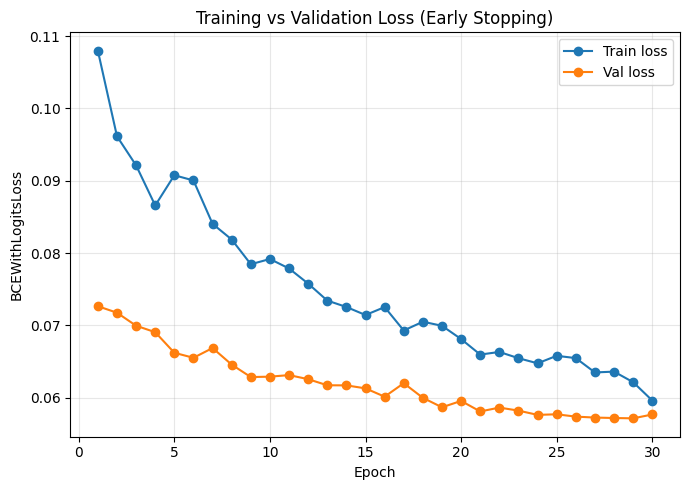

In [98]:
# Load best
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
print("Loaded best model from:", BEST_PATH)

# ------------------------
# 9) Plot train/val loss curves
# ------------------------
plt.figure(figsize=(7,5))
plt.plot(range(1, len(train_losses)+1), train_losses, marker="o", label="Train loss")
plt.plot(range(1, len(val_losses)+1), val_losses, marker="o", label="Val loss")
plt.xlabel("Epoch")
plt.ylabel("BCEWithLogitsLoss")
plt.title("Training vs Validation Loss (Early Stopping)")
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [99]:
from sklearn.metrics import precision_recall_curve

def find_best_threshold(y_true, p):
    prec, rec, thr = precision_recall_curve(y_true, p)
    f1 = 2 * prec * rec / (prec + rec + 1e-8)
    idx = np.argmax(f1)
    return thr[idx], f1[idx]

best_thr, best_f1 = find_best_threshold(y_val, p_val)
print("Best threshold:", best_thr, "Best F1:", best_f1)

Best threshold: 0.3145112 Best F1: 0.2499999954882813


In [100]:
# ------------------------
# 10) Final evaluation (VAL + TEST)
#     Report metrics robust for imbalance + confusion matrix
# ------------------------
def evaluate_split(name, loader, thr=0.314):
    y, p = predict_proba(loader)
    metrics, cm = compute_binary_metrics(y, p, thr=thr)
    metrics["Split"] = name
    metrics["Loss"] = float(eval_loss(loader))
    return metrics, cm, y, p

m_val, cm_val, yv, pv = evaluate_split("Validation", val_loader, thr=0.314)
m_test, cm_test, yt, pt = evaluate_split("Test", test_loader, thr=0.314)

results = pd.DataFrame([m_val, m_test])[
    ["Split","Loss","AUC","PR_AUC","BalancedAcc","Sensitivity","Specificity","Precision","Recall","F1","MCC","TN","FP","FN","TP"]
].round(4)

print(results)

        Split    Loss     AUC  PR_AUC  BalancedAcc  Sensitivity  Specificity  \
0  Validation  0.0572  0.6663  0.1525       0.6108       0.4773       0.7443   
1        Test  0.0575  0.6536  0.1744       0.6180       0.5301       0.7058   

   Precision  Recall      F1     MCC   TN   FP  FN  TP  
0     0.1567  0.4773  0.2360  0.1423  329  113  23  21  
1     0.1457  0.5301  0.2286  0.1428  619  258  39  44  


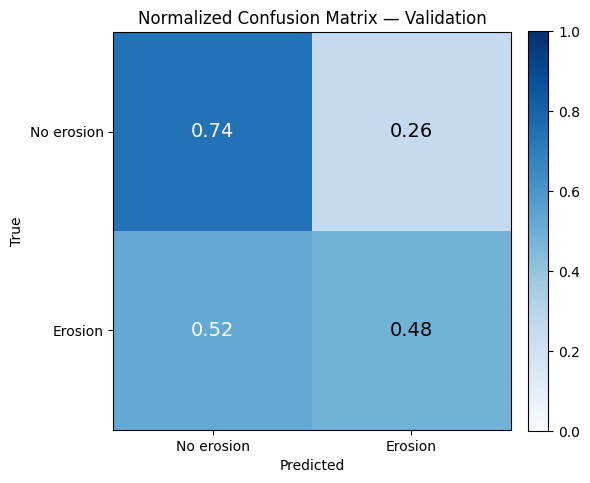

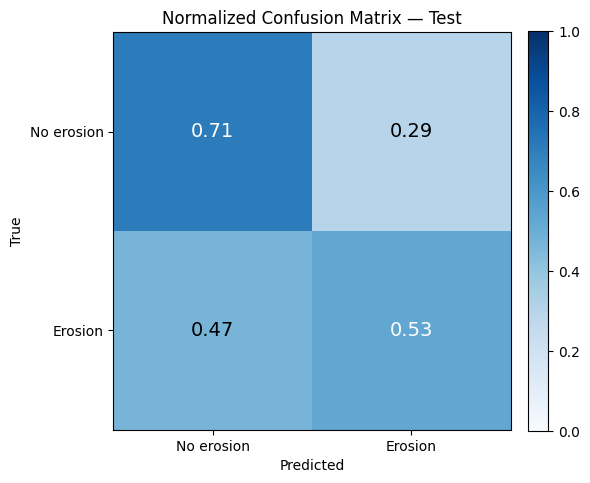

In [101]:
# ------------------------
# 11) Confusion matrices (normalized)
# ------------------------
def plot_cm(cm, title):
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)
    fig, ax = plt.subplots(figsize=(6,6))
    im = ax.imshow(cm_norm, vmin=0, vmax=1, cmap="Blues")
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(["No erosion","Erosion"])
    ax.set_yticklabels(["No erosion","Erosion"])
    ax.set_xlabel("Predicted"); ax.set_ylabel("True")
    ax.set_title(title)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f"{cm_norm[i,j]:.2f}",
                    ha="center", va="center",
                    color="white" if cm_norm[i,j] > 0.5 else "black", fontsize=14)
    plt.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
    plt.tight_layout()
    plt.show()

plot_cm(cm_val,  "Normalized Confusion Matrix — Validation")
plot_cm(cm_test, "Normalized Confusion Matrix — Test")

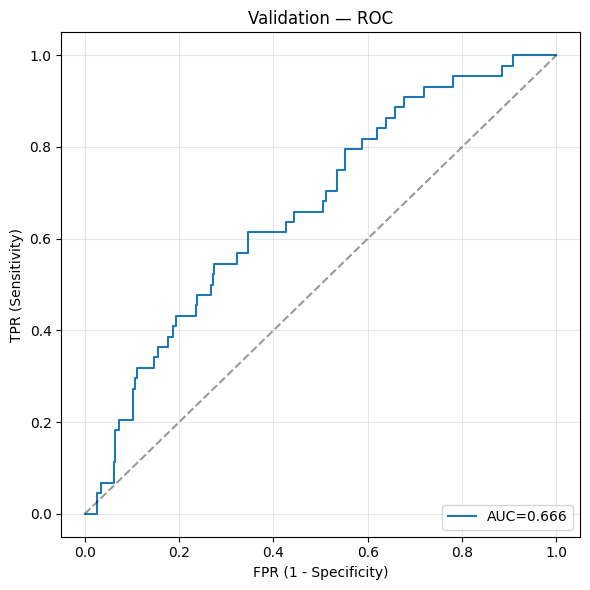

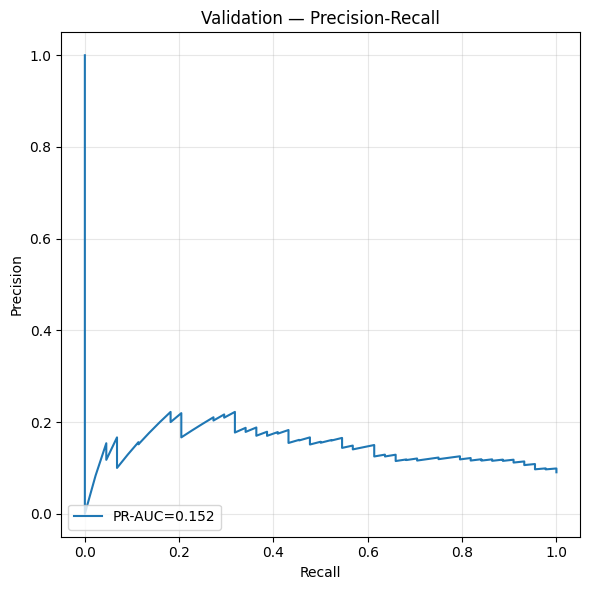

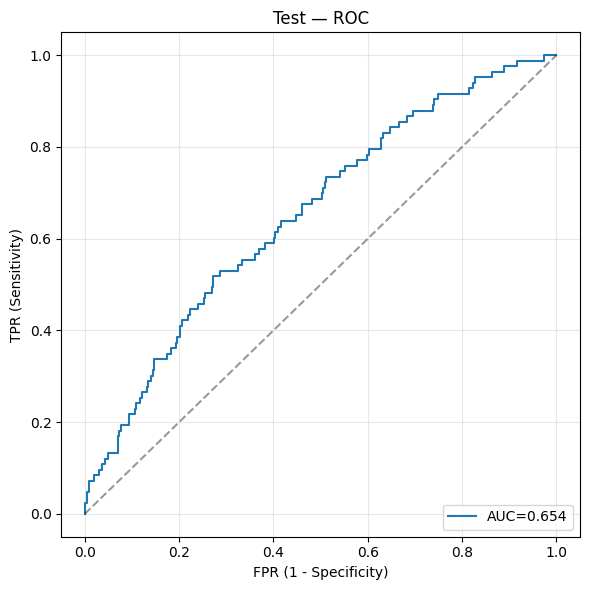

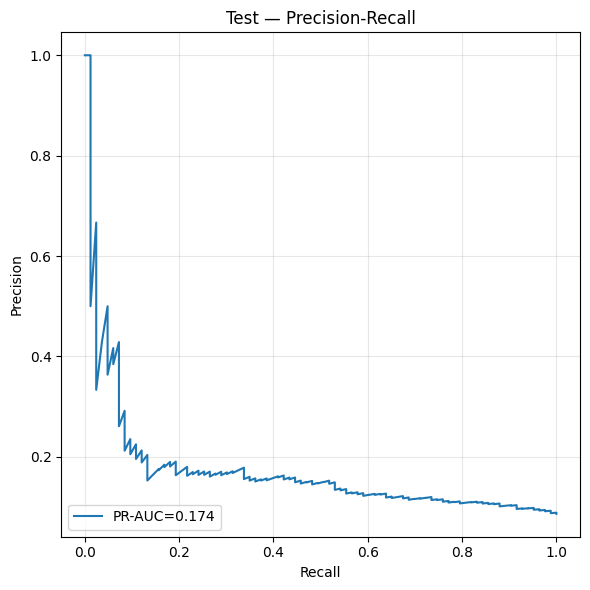

In [102]:
# 12) ROC + PR curves (VAL & TEST)
# ------------------------
def plot_roc_pr(y, p, title_prefix):
    # ROC
    if len(np.unique(y)) == 2:
        fpr, tpr, _ = roc_curve(y, p)
        auc_ = roc_auc_score(y, p)
        plt.figure(figsize=(6,6))
        plt.plot(fpr, tpr, label=f"AUC={auc_:.3f}")
        plt.plot([0,1],[0,1],"k--",alpha=0.4)
        plt.xlabel("FPR (1 - Specificity)")
        plt.ylabel("TPR (Sensitivity)")
        plt.title(f"{title_prefix} — ROC")
        plt.legend(loc="lower right")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()

        # PR
        prec, rec, _ = precision_recall_curve(y, p)
        ap = average_precision_score(y, p)
        plt.figure(figsize=(6,6))
        plt.plot(rec, prec, label=f"PR-AUC={ap:.3f}")
        plt.xlabel("Recall")
        plt.ylabel("Precision")
        plt.title(f"{title_prefix} — Precision-Recall")
        plt.legend(loc="lower left")
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()
    else:
        print(f"{title_prefix}: ROC/PR skipped (single-class labels).")

plot_roc_pr(yv, pv, "Validation")
plot_roc_pr(yt, pt, "Test")

In [103]:
# ------------------------
# 13) Show example predictions on TEST (qualitative generalization check)
# ------------------------
@torch.no_grad()
def show_test_predictions(df_test, n=10, thr=0.314):
    model.eval()
    idxs = np.random.choice(len(df_test), size=min(n, len(df_test)), replace=False)
    plt.figure(figsize=(16, 6))
    for i, idx in enumerate(idxs, 1):
        r = df_test.iloc[idx]
        img = Image.open(r["image_path"]).convert("L")
        x = EROBoneDataset(df_test.iloc[[idx]], augment=False, mean=train_mean, std=train_std)[0][0].unsqueeze(0).to(device)
        logit = model(x).item()
        p = 1 / (1 + np.exp(-logit))
        y_true = int(r["ero_bin"])
        y_hat = int(p >= thr)

        plt.subplot(2, (len(idxs)+1)//2, i)
        plt.imshow(img, cmap="gray")
        plt.axis("off")
        plt.title(f"{r['bone']} | true={y_true} pred={y_hat} p={p:.2f}", fontsize=10)
    plt.tight_layout()
    plt.show()

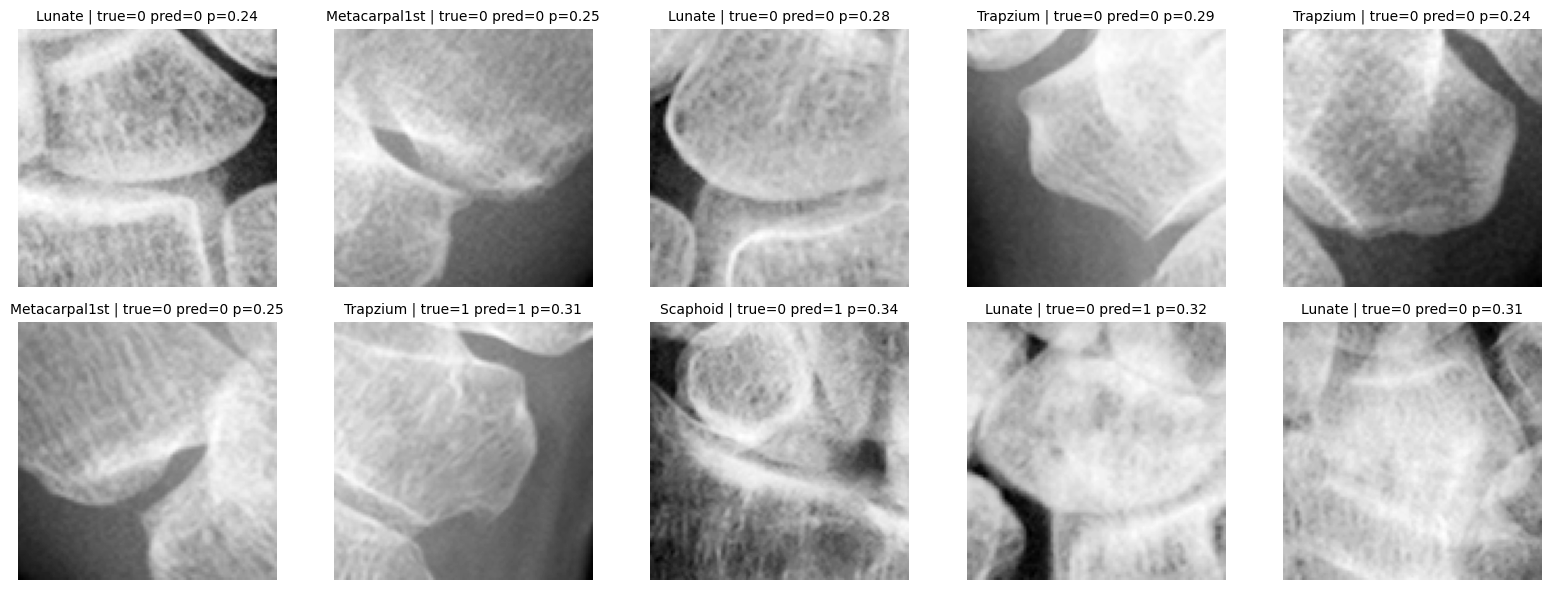

In [104]:
show_test_predictions(df_test, n=10, thr=0.314)

In [105]:
from pathlib import Path
import json
import torch

# =========================================================
# 14) EXPORT FINAL MODEL FOR WEB APP / DEPLOYMENT
# =========================================================

EXPORT_DIR = Path("/kaggle/working/final_model_artifacts")
EXPORT_DIR.mkdir(parents=True, exist_ok=True)

FINAL_CHECKPOINT_PATH = EXPORT_DIR / "ero_resnet18_checkpoint.pth"
FINAL_CONFIG_PATH = EXPORT_DIR / "ero_resnet18_config.json"
FINAL_SCRIPTED_PATH = EXPORT_DIR / "ero_resnet18_scripted.pt"

# Recharger le meilleur modèle avant export
model.load_state_dict(torch.load(BEST_PATH, map_location=device))
model.eval()

# utiliser le meilleur threshold trouvé sur validation
final_threshold = float(best_thr) if "best_thr" in globals() else 0.314

# checkpoint complet
checkpoint = {
    "model_class": "EROBinaryResNet18",
    "backbone": "resnet18",
    "dropout": 0.6,
    "input_size": [224, 224],
    "num_classes": 1,
    "threshold": final_threshold,
    "train_mean": train_mean,
    "train_std": train_std,
    "class_names": {
        "0": "No erosion",
        "1": "Erosion"
    },
    "state_dict": model.state_dict()
}

# sauvegarde du checkpoint
torch.save(checkpoint, FINAL_CHECKPOINT_PATH)

# sauvegarde config lisible en JSON
config = {
    "model_class": "EROBinaryResNet18",
    "backbone": "resnet18",
    "dropout": 0.6,
    "input_size": [224, 224],
    "num_classes": 1,
    "threshold": final_threshold,
    "train_mean": train_mean,
    "train_std": train_std,
    "class_names": {
        "0": "No erosion",
        "1": "Erosion"
    }
}

with open(FINAL_CONFIG_PATH, "w") as f:
    json.dump(config, f, indent=4)

# export TorchScript (pratique pour déploiement)
example_input = torch.randn(1, 3, 224, 224).to(device)

try:
    scripted_model = torch.jit.trace(model, example_input)
    scripted_model.save(str(FINAL_SCRIPTED_PATH))
    print(f"✅ TorchScript model saved to: {FINAL_SCRIPTED_PATH}")
except Exception as e:
    print(f"⚠️ TorchScript export failed: {e}")

print(f"✅ Checkpoint saved to: {FINAL_CHECKPOINT_PATH}")
print(f"✅ Config saved to: {FINAL_CONFIG_PATH}")

✅ TorchScript model saved to: /kaggle/working/final_model_artifacts/ero_resnet18_scripted.pt
✅ Checkpoint saved to: /kaggle/working/final_model_artifacts/ero_resnet18_checkpoint.pth
✅ Config saved to: /kaggle/working/final_model_artifacts/ero_resnet18_config.json


In [106]:
# =========================================================
# ABLATION STUDY V2 — CONFIGURATION AND COMMON FUNCTIONS
# =========================================================

import gc
import json
import random
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

# ---------------------------------------------------------
# Vérification du GPU et des objets du notebook
# ---------------------------------------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))
else:
    raise RuntimeError("Aucun GPU CUDA détecté.")

required_objects = [
    "df_train",
    "df_val",
    "df_test",
    "train_mean",
    "train_std",
    "EROBoneDataset",
    "EROBinaryResNet18"
]

missing_objects = [
    name for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        f"Objets manquants dans le notebook : {missing_objects}"
    )


# ---------------------------------------------------------
# Configuration identique au modèle initial
# ---------------------------------------------------------
ABLATION_DIR = Path(
    "/kaggle/working/ablation_studies_v2"
)
ABLATION_DIR.mkdir(
    parents=True,
    exist_ok=True
)

ABLATION_SEED = 42
MAX_EPOCHS = 30
EARLY_STOPPING_PATIENCE = 4

TRAIN_BATCH_SIZE = 32
EVAL_BATCH_SIZE = 64

LEARNING_RATE = 1e-4
WEIGHT_DECAY = 1e-3
DROPOUT = 0.6

FOCAL_ALPHA = 0.75
FOCAL_GAMMA = 2.0

N_POSITIVE = int(
    (df_train["ero_bin"] == 1).sum()
)

N_NEGATIVE = int(
    (df_train["ero_bin"] == 0).sum()
)

POSITIVE_WEIGHT = (
    N_NEGATIVE / max(N_POSITIVE, 1)
)

print("Training positives:", N_POSITIVE)
print("Training negatives:", N_NEGATIVE)
print("BCE positive weight:", POSITIVE_WEIGHT)


# ---------------------------------------------------------
# Reproduction du comportement aléatoire initial
# ---------------------------------------------------------
def set_ablation_seed(seed=42):
    random.seed(seed)
    np.random.seed(seed)

    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

    # Identique au notebook initial
    torch.backends.cudnn.deterministic = False
    torch.backends.cudnn.benchmark = True


# ---------------------------------------------------------
# Focal loss initiale du notebook
# Utilisée uniquement pour reproduire l'ancien résultat.
# ---------------------------------------------------------
class LegacyFocalLoss(nn.Module):

    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()

        self.alpha = float(alpha)
        self.gamma = float(gamma)

        self.bce = nn.BCEWithLogitsLoss(
            reduction="none"
        )

    def forward(self, logits, targets):
        bce = self.bce(
            logits,
            targets
        )

        probabilities = torch.sigmoid(logits)

        p_t = (
            targets * probabilities
            + (1.0 - targets)
            * (1.0 - probabilities)
        )

        loss = (
            self.alpha
            * (1.0 - p_t).pow(self.gamma)
            * bce
        )

        return loss.mean()


# ---------------------------------------------------------
# Focal loss corrigée
# alpha pondère réellement les deux classes.
# ---------------------------------------------------------
class CorrectedBinaryFocalLoss(nn.Module):

    def __init__(self, alpha=0.75, gamma=2.0):
        super().__init__()

        self.alpha = float(alpha)
        self.gamma = float(gamma)

    def forward(self, logits, targets):
        targets = targets.float()

        bce = F.binary_cross_entropy_with_logits(
            logits,
            targets,
            reduction="none"
        )

        probabilities = torch.sigmoid(logits)

        p_t = (
            targets * probabilities
            + (1.0 - targets)
            * (1.0 - probabilities)
        )

        alpha_t = (
            targets * self.alpha
            + (1.0 - targets)
            * (1.0 - self.alpha)
        )

        focal_weight = (
            alpha_t
            * (1.0 - p_t).pow(self.gamma)
        )

        return (
            focal_weight * bce
        ).mean()


# ---------------------------------------------------------
# Création de la fonction de perte
# ---------------------------------------------------------
def build_ablation_criterion(loss_name):

    if loss_name == "bce":
        return nn.BCEWithLogitsLoss()

    if loss_name == "weighted_bce":
        positive_weight = torch.tensor(
            [POSITIVE_WEIGHT],
            dtype=torch.float32,
            device=device
        )

        return nn.BCEWithLogitsLoss(
            pos_weight=positive_weight
        )

    if loss_name == "corrected_focal":
        return CorrectedBinaryFocalLoss(
            alpha=FOCAL_ALPHA,
            gamma=FOCAL_GAMMA
        )

    if loss_name == "legacy_focal":
        return LegacyFocalLoss(
            alpha=FOCAL_ALPHA,
            gamma=FOCAL_GAMMA
        )

    raise ValueError(
        f"Loss inconnue : {loss_name}"
    )


# ---------------------------------------------------------
# DataLoaders
# ---------------------------------------------------------
def build_ablation_loaders(use_augmentation):

    train_dataset = EROBoneDataset(
        df_train,
        augment=use_augmentation,
        mean=train_mean,
        std=train_std
    )

    validation_dataset = EROBoneDataset(
        df_val,
        augment=False,
        mean=train_mean,
        std=train_std
    )

    test_dataset = EROBoneDataset(
        df_test,
        augment=False,
        mean=train_mean,
        std=train_std
    )

    train_loader_exp = DataLoader(
        train_dataset,
        batch_size=TRAIN_BATCH_SIZE,
        shuffle=True,
        num_workers=0,
        pin_memory=True
    )

    validation_loader_exp = DataLoader(
        validation_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    test_loader_exp = DataLoader(
        test_dataset,
        batch_size=EVAL_BATCH_SIZE,
        shuffle=False,
        num_workers=0,
        pin_memory=True
    )

    return (
        train_loader_exp,
        validation_loader_exp,
        test_loader_exp
    )


# ---------------------------------------------------------
# Nouveau ResNet-18 initialisé pour chaque expérience
# ---------------------------------------------------------
def build_ablation_model():

    net = EROBinaryResNet18(
        dropout=DROPOUT
    ).to(device)

    for parameter in net.backbone.parameters():
        parameter.requires_grad = False

    for parameter in net.backbone.fc.parameters():
        parameter.requires_grad = True

    return net


# ---------------------------------------------------------
# Une époque d'entraînement
# model.train() reproduit le comportement initial,
# y compris la mise à jour des statistiques BatchNorm.
# ---------------------------------------------------------
def train_ablation_epoch(
    net,
    loader,
    criterion,
    optimizer
):
    net.train()

    total_loss = 0.0

    for images, targets in loader:
        images = images.to(
            device,
            non_blocking=True
        )

        targets = targets.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        logits = net(images)

        loss = criterion(
            logits,
            targets
        )

        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    return total_loss / len(loader)


# ---------------------------------------------------------
# Perte de validation
# ---------------------------------------------------------
@torch.no_grad()
def evaluate_ablation_loss(
    net,
    loader,
    criterion
):
    net.eval()

    total_loss = 0.0

    for images, targets in loader:
        images = images.to(
            device,
            non_blocking=True
        )

        targets = targets.to(
            device,
            non_blocking=True
        )

        logits = net(images)

        loss = criterion(
            logits,
            targets
        )

        total_loss += loss.item()

    return total_loss / len(loader)


# ---------------------------------------------------------
# Prédictions probabilistes
# ---------------------------------------------------------
@torch.no_grad()
def predict_ablation_probabilities(
    net,
    loader
):
    net.eval()

    all_targets = []
    all_probabilities = []

    for images, targets in loader:
        images = images.to(
            device,
            non_blocking=True
        )

        logits = net(images)

        probabilities = torch.sigmoid(
            logits
        )

        all_targets.append(
            targets.numpy()
        )

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

    y_true = np.concatenate(
        all_targets
    ).astype(int)

    y_probability = np.concatenate(
        all_probabilities
    )

    return y_true, y_probability


# ---------------------------------------------------------
# Seuil maximisant le F1 sur la validation
# ---------------------------------------------------------
def select_validation_threshold(
    y_true,
    probabilities
):
    precision, recall, thresholds = (
        precision_recall_curve(
            y_true,
            probabilities
        )
    )

    if len(thresholds) == 0:
        return 0.5, 0.0

    f1_scores = (
        2.0
        * precision[:-1]
        * recall[:-1]
        / (
            precision[:-1]
            + recall[:-1]
            + 1e-12
        )
    )

    best_index = int(
        np.nanargmax(f1_scores)
    )

    return (
        float(thresholds[best_index]),
        float(f1_scores[best_index])
    )


# ---------------------------------------------------------
# Métriques sur le test
# ---------------------------------------------------------
def compute_ablation_metrics(
    y_true,
    probabilities,
    threshold
):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    tn, fp, fn, tp = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    ).ravel()

    sensitivity = (
        tp / max(tp + fn, 1)
    )

    specificity = (
        tn / max(tn + fp, 1)
    )

    return {
        "ROC-AUC": float(
            roc_auc_score(
                y_true,
                probabilities
            )
        ),
        "PR-AUC": float(
            average_precision_score(
                y_true,
                probabilities
            )
        ),
        "Sensitivity": float(sensitivity),
        "Specificity": float(specificity),
        "TN": int(tn),
        "FP": int(fp),
        "FN": int(fn),
        "TP": int(tp)
    }

Device: cuda
GPU: Tesla T4
Training positives: 293
Training negatives: 3061
BCE positive weight: 10.447098976109215


In [107]:
# =========================================================
# RUN ONE CONTROLLED ABLATION EXPERIMENT
# =========================================================

def run_ablation_experiment(config):

    experiment_name = config["name"]
    loss_name = config["loss"]
    use_augmentation = config["augmentation"]

    print("\n" + "=" * 80)
    print("Experiment:", experiment_name)
    print("Loss:", loss_name)
    print("Augmentation:", use_augmentation)
    print("=" * 80)

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # Même graine avant chaque expérience
    set_ablation_seed(
        ABLATION_SEED
    )

    (
        train_loader_exp,
        validation_loader_exp,
        test_loader_exp
    ) = build_ablation_loaders(
        use_augmentation=use_augmentation
    )

    net = build_ablation_model()

    criterion = build_ablation_criterion(
        loss_name
    )

    optimizer = torch.optim.AdamW(
        net.backbone.fc.parameters(),
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=2,
            min_lr=1e-6
        )
    )

    checkpoint_path = (
        ABLATION_DIR
        / f"{experiment_name}_best.pt"
    )

    best_validation_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "validation_loss": [],
        "learning_rate": []
    }

    for epoch in range(
        1,
        MAX_EPOCHS + 1
    ):
        train_loss = train_ablation_epoch(
            net,
            train_loader_exp,
            criterion,
            optimizer
        )

        validation_loss = (
            evaluate_ablation_loss(
                net,
                validation_loader_exp,
                criterion
            )
        )

        scheduler.step(
            validation_loss
        )

        current_learning_rate = (
            optimizer.param_groups[0]["lr"]
        )

        history["train_loss"].append(
            float(train_loss)
        )

        history["validation_loss"].append(
            float(validation_loss)
        )

        history["learning_rate"].append(
            float(current_learning_rate)
        )

        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"train={train_loss:.5f} | "
            f"val={validation_loss:.5f} | "
            f"lr={current_learning_rate:.2e}"
        )

        if (
            validation_loss
            < best_validation_loss - 1e-4
        ):
            best_validation_loss = (
                validation_loss
            )

            best_epoch = epoch

            epochs_without_improvement = 0

            torch.save(
                {
                    "model_state_dict":
                        net.state_dict(),
                    "config":
                        config,
                    "best_epoch":
                        best_epoch,
                    "best_validation_loss":
                        best_validation_loss,
                    "seed":
                        ABLATION_SEED
                },
                checkpoint_path
            )

            print("  Best checkpoint saved")

        else:
            epochs_without_improvement += 1

            print(
                "  No improvement: "
                f"{epochs_without_improvement}/"
                f"{EARLY_STOPPING_PATIENCE}"
            )

            if (
                epochs_without_improvement
                >= EARLY_STOPPING_PATIENCE
            ):
                print("  Early stopping")
                break

    # -----------------------------------------------------
    # Recharger le meilleur checkpoint
    # -----------------------------------------------------
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )

    net.load_state_dict(
        checkpoint["model_state_dict"]
    )

    net.eval()

    # -----------------------------------------------------
    # Recalculer les probabilités du meilleur modèle
    # sur la validation
    # -----------------------------------------------------
    (
        validation_targets,
        validation_probabilities
    ) = predict_ablation_probabilities(
        net,
        validation_loader_exp
    )

    (
        selected_threshold,
        validation_f1
    ) = select_validation_threshold(
        validation_targets,
        validation_probabilities
    )

    validation_roc_auc = roc_auc_score(
        validation_targets,
        validation_probabilities
    )

    validation_pr_auc = average_precision_score(
        validation_targets,
        validation_probabilities
    )

    # -----------------------------------------------------
    # Évaluation finale sur le test
    # -----------------------------------------------------
    (
        test_targets,
        test_probabilities
    ) = predict_ablation_probabilities(
        net,
        test_loader_exp
    )

    test_metrics = compute_ablation_metrics(
        test_targets,
        test_probabilities,
        threshold=selected_threshold
    )

    result = {
        "Experiment":
            experiment_name,
        "Model":
            "ResNet-18",
        "Loss":
            config["display_loss"],
        "Augmentation":
            "Yes" if use_augmentation else "No",
        "ROC-AUC":
            test_metrics["ROC-AUC"],
        "PR-AUC":
            test_metrics["PR-AUC"],
        "Sensitivity":
            test_metrics["Sensitivity"],
        "Specificity":
            test_metrics["Specificity"],
        "Validation threshold":
            selected_threshold,
        "Validation F1":
            validation_f1,
        "Validation ROC-AUC":
            float(validation_roc_auc),
        "Validation PR-AUC":
            float(validation_pr_auc),
        "Best epoch":
            int(best_epoch),
        "Best validation loss":
            float(best_validation_loss),
        "TN":
            test_metrics["TN"],
        "FP":
            test_metrics["FP"],
        "FN":
            test_metrics["FN"],
        "TP":
            test_metrics["TP"]
    }

    output = {
        "config": config,
        "result": result,
        "history": history
    }

    history_path = (
        ABLATION_DIR
        / f"{experiment_name}_results.json"
    )

    with open(
        history_path,
        "w"
    ) as file:
        json.dump(
            output,
            file,
            indent=4
        )

    print(
        f"Best epoch: {best_epoch}"
    )

    print(
        "Selected validation threshold: "
        f"{selected_threshold:.6f}"
    )

    print(
        f"Test ROC-AUC: "
        f"{result['ROC-AUC']:.4f}"
    )

    print(
        f"Test PR-AUC: "
        f"{result['PR-AUC']:.4f}"
    )

    print(
        f"Sensitivity: "
        f"{result['Sensitivity']:.4f}"
    )

    print(
        f"Specificity: "
        f"{result['Specificity']:.4f}"
    )

    del net
    del optimizer
    del scheduler
    del criterion

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

In [108]:
# =========================================================
# BASELINE REPRODUCTION + FINAL ABLATIONS
# =========================================================

# ---------------------------------------------------------
# 1. Contrôle : reproduction exacte de l'ancien pipeline
# Cette ligne ne sera pas intégrée au tableau de l'article.
# ---------------------------------------------------------
legacy_baseline_config = {
    "name":
        "diagnostic_legacy_focal_augmentation",
    "loss":
        "legacy_focal",
    "display_loss":
        "Legacy focal loss",
    "augmentation":
        True
}

legacy_baseline_result = (
    run_ablation_experiment(
        legacy_baseline_config
    )
)

PREVIOUS_REPORTED_ROC_AUC = 0.6536

legacy_auc = (
    legacy_baseline_result["ROC-AUC"]
)

auc_difference = (
    legacy_auc
    - PREVIOUS_REPORTED_ROC_AUC
)

print("\n" + "=" * 80)
print("BASELINE REPRODUCTION CHECK")
print("=" * 80)

print(
    "Previously reported ROC-AUC:",
    PREVIOUS_REPORTED_ROC_AUC
)

print(
    "Reproduced ROC-AUC:",
    round(legacy_auc, 4)
)

print(
    "Difference:",
    round(auc_difference, 4)
)

if abs(auc_difference) <= 0.03:
    print(
        "Baseline reproduction acceptable."
    )
else:
    print(
        "Warning: baseline not reproduced. "
        "Do not interpret the ablation table yet."
    )


# ---------------------------------------------------------
# 2. Ablations contrôlées pour le papier
# ---------------------------------------------------------
ABLATION_CONFIGS = [
    {
        "name":
            "resnet18_bce_augmentation",
        "loss":
            "bce",
        "display_loss":
            "Binary cross-entropy",
        "augmentation":
            True
    },
    {
        "name":
            "resnet18_weighted_bce_augmentation",
        "loss":
            "weighted_bce",
        "display_loss":
            "Weighted binary cross-entropy",
        "augmentation":
            True
    },
    {
        "name":
            "resnet18_corrected_focal_augmentation",
        "loss":
            "corrected_focal",
        "display_loss":
            "Focal loss",
        "augmentation":
            True
    },
    {
        "name":
            "resnet18_bce_no_augmentation",
        "loss":
            "bce",
        "display_loss":
            "Binary cross-entropy",
        "augmentation":
            False
    },
    {
        "name":
            "resnet18_corrected_focal_no_augmentation",
        "loss":
            "corrected_focal",
        "display_loss":
            "Focal loss",
        "augmentation":
            False
    }
]


ablation_results = []

for experiment_config in ABLATION_CONFIGS:

    experiment_result = (
        run_ablation_experiment(
            experiment_config
        )
    )

    ablation_results.append(
        experiment_result
    )

    # Sauvegarde intermédiaire après chaque expérience
    pd.DataFrame(
        ablation_results
    ).to_csv(
        ABLATION_DIR
        / "ablation_results_detailed.csv",
        index=False
    )


# ---------------------------------------------------------
# Tableau détaillé
# ---------------------------------------------------------
ablation_results_detailed = pd.DataFrame(
    ablation_results
)

detailed_columns = [
    "Experiment",
    "Model",
    "Loss",
    "Augmentation",
    "ROC-AUC",
    "PR-AUC",
    "Sensitivity",
    "Specificity",
    "Validation threshold",
    "Validation F1",
    "Validation ROC-AUC",
    "Validation PR-AUC",
    "Best epoch",
    "Best validation loss",
    "TN",
    "FP",
    "FN",
    "TP"
]

ablation_results_detailed = (
    ablation_results_detailed[
        detailed_columns
    ]
)

display(
    ablation_results_detailed.round(4)
)


# ---------------------------------------------------------
# Tableau destiné au papier
# ---------------------------------------------------------
paper_columns = [
    "Model",
    "Loss",
    "Augmentation",
    "ROC-AUC",
    "PR-AUC",
    "Sensitivity",
    "Specificity"
]

ablation_table_for_paper = (
    ablation_results_detailed[
        paper_columns
    ]
    .copy()
    .round(4)
)

display(
    ablation_table_for_paper
)


# ---------------------------------------------------------
# Sauvegarde des résultats
# ---------------------------------------------------------
ablation_results_detailed.to_csv(
    ABLATION_DIR
    / "ablation_results_detailed.csv",
    index=False
)

ablation_table_for_paper.to_csv(
    ABLATION_DIR
    / "ablation_table_for_paper.csv",
    index=False
)

pd.DataFrame(
    [legacy_baseline_result]
).to_csv(
    ABLATION_DIR
    / "legacy_baseline_reproduction.csv",
    index=False
)

print(
    "\nDetailed results:",
    ABLATION_DIR
    / "ablation_results_detailed.csv"
)

print(
    "Paper table:",
    ABLATION_DIR
    / "ablation_table_for_paper.csv"
)

print(
    "Baseline diagnostic:",
    ABLATION_DIR
    / "legacy_baseline_reproduction.csv"
)


Experiment: diagnostic_legacy_focal_augmentation
Loss: legacy_focal
Augmentation: True
Epoch 01/30 | train=0.10564 | val=0.06890 | lr=1.00e-04
  Best checkpoint saved
Epoch 02/30 | train=0.09392 | val=0.06689 | lr=1.00e-04
  Best checkpoint saved
Epoch 03/30 | train=0.09289 | val=0.06673 | lr=1.00e-04
  Best checkpoint saved
Epoch 04/30 | train=0.09211 | val=0.06537 | lr=1.00e-04
  Best checkpoint saved
Epoch 05/30 | train=0.08958 | val=0.06436 | lr=1.00e-04
  Best checkpoint saved
Epoch 06/30 | train=0.08323 | val=0.06364 | lr=1.00e-04
  Best checkpoint saved
Epoch 07/30 | train=0.08372 | val=0.06284 | lr=1.00e-04
  Best checkpoint saved
Epoch 08/30 | train=0.08161 | val=0.06301 | lr=1.00e-04
  No improvement: 1/4
Epoch 09/30 | train=0.08060 | val=0.06190 | lr=1.00e-04
  Best checkpoint saved
Epoch 10/30 | train=0.07528 | val=0.06123 | lr=1.00e-04
  Best checkpoint saved
Epoch 11/30 | train=0.07891 | val=0.06067 | lr=1.00e-04
  Best checkpoint saved
Epoch 12/30 | train=0.07370 | val=

,Experiment,Model,Loss,Augmentation,ROC-AUC,PR-AUC,Sensitivity,Specificity,Validation threshold,Validation F1,Validation ROC-AUC,Validation PR-AUC,Best epoch,Best validation loss,TN,FP,FN,TP
0,resnet18_bce_augmentation,ResNet-18,Binary cross-entropy,Yes,0.6043,0.1370,0.2410,0.8780,0.1321,0.2783,0.6239,0.1524,28,0.2840,770,107,63,20
1,resnet18_weighted_bce_augmentation,ResNet-18,Weighted binary cross-entropy,Yes,0.6614,0.1729,0.1566,0.9498,0.6066,0.2826,0.6709,0.1780,30,1.1782,833,44,70,13
2,resnet18_corrected_focal_augmentation,ResNet-18,Focal loss,Yes,0.6512,0.1610,0.1807,0.9384,0.4355,0.2917,0.6680,0.1800,28,0.0374,823,54,68,15
3,resnet18_bce_no_augmentation,ResNet-18,Binary cross-entropy,No,0.7482,0.2251,0.1446,0.9749,0.1787,0.2683,0.6588,0.1647,30,0.2793,855,22,71,12
4,resnet18_corrected_focal_no_augmentation,ResNet-18,Focal loss,No,0.7667,0.2432,0.5904,0.7811,0.4121,0.2591,0.6906,0.1915,25,0.0366,685,192,34,49


,Model,Loss,Augmentation,ROC-AUC,PR-AUC,Sensitivity,Specificity
0,ResNet-18,Binary cross-entropy,Yes,0.6043,0.1370,0.2410,0.8780
1,ResNet-18,Weighted binary cross-entropy,Yes,0.6614,0.1729,0.1566,0.9498
2,ResNet-18,Focal loss,Yes,0.6512,0.1610,0.1807,0.9384
3,ResNet-18,Binary cross-entropy,No,0.7482,0.2251,0.1446,0.9749
4,ResNet-18,Focal loss,No,0.7667,0.2432,0.5904,0.7811



Detailed results: /kaggle/working/ablation_studies_v2/ablation_results_detailed.csv
Paper table: /kaggle/working/ablation_studies_v2/ablation_table_for_paper.csv
Baseline diagnostic: /kaggle/working/ablation_studies_v2/legacy_baseline_reproduction.csv


In [109]:
# =========================================================
# STRONGER ARCHITECTURE BASELINES
# DenseNet-121, EfficientNet-B0 and ResNet-50
# =========================================================

import gc
import json
from pathlib import Path

import numpy as np
import pandas as pd
import torch
import torch.nn as nn

from torchvision import models
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score
)

# ---------------------------------------------------------
# Vérifier que la section d'ablation V2 a été exécutée
# ---------------------------------------------------------
required_architecture_objects = [
    "df_train",
    "df_val",
    "df_test",
    "train_mean",
    "train_std",
    "CorrectedBinaryFocalLoss",
    "build_ablation_loaders",
    "set_ablation_seed",
    "train_ablation_epoch",
    "evaluate_ablation_loss",
    "predict_ablation_probabilities",
    "select_validation_threshold",
    "compute_ablation_metrics",
    "ablation_results_detailed",
    "ABLATION_SEED",
    "MAX_EPOCHS",
    "EARLY_STOPPING_PATIENCE",
    "LEARNING_RATE",
    "WEIGHT_DECAY",
    "DROPOUT",
    "FOCAL_ALPHA",
    "FOCAL_GAMMA"
]

missing_architecture_objects = [
    name
    for name in required_architecture_objects
    if name not in globals()
]

if missing_architecture_objects:
    raise RuntimeError(
        "Exécuter d'abord les cellules d'ablation V2. "
        f"Objets manquants : {missing_architecture_objects}"
    )


# ---------------------------------------------------------
# Répertoire de sauvegarde
# ---------------------------------------------------------
ARCHITECTURE_DIR = Path(
    "/kaggle/working/architecture_baselines"
)

ARCHITECTURE_DIR.mkdir(
    parents=True,
    exist_ok=True
)


# ---------------------------------------------------------
# Architectures supplémentaires
# ResNet-18 n'est pas réentraîné :
# sa ligne finale est récupérée depuis les ablations.
# ---------------------------------------------------------
ARCHITECTURE_CONFIGS = [
    {
        "name": "densenet121",
        "display_name": "DenseNet-121"
    },
    {
        "name": "efficientnet_b0",
        "display_name": "EfficientNet-B0"
    },
    {
        "name": "resnet50",
        "display_name": "ResNet-50"
    }
]


# ---------------------------------------------------------
# Modèle générique de classification binaire
# ---------------------------------------------------------
class BinaryPretrainedClassifier(nn.Module):

    def __init__(
        self,
        architecture,
        dropout=0.6
    ):
        super().__init__()

        self.architecture = architecture

        if architecture == "densenet121":

            backbone = models.densenet121(
                weights=models.DenseNet121_Weights.DEFAULT
            )

            # Geler tout le backbone préentraîné
            for parameter in backbone.parameters():
                parameter.requires_grad = False

            in_features = backbone.classifier.in_features

            backbone.classifier = nn.Sequential(
                nn.Dropout(p=dropout),
                nn.Linear(in_features, 1)
            )

        elif architecture == "efficientnet_b0":

            backbone = models.efficientnet_b0(
                weights=models.EfficientNet_B0_Weights.DEFAULT
            )

            for parameter in backbone.parameters():
                parameter.requires_grad = False

            in_features = backbone.classifier[-1].in_features

            backbone.classifier = nn.Sequential(
                nn.Dropout(p=dropout),
                nn.Linear(in_features, 1)
            )

        elif architecture == "resnet50":

            backbone = models.resnet50(
                weights=models.ResNet50_Weights.DEFAULT
            )

            for parameter in backbone.parameters():
                parameter.requires_grad = False

            in_features = backbone.fc.in_features

            backbone.fc = nn.Sequential(
                nn.Dropout(p=dropout),
                nn.Linear(in_features, 1)
            )

        else:
            raise ValueError(
                f"Architecture inconnue : {architecture}"
            )

        self.backbone = backbone

    def forward(self, images):

        logits = self.backbone(images)

        return logits.squeeze(1)

    def trainable_parameters(self):

        return [
            parameter
            for parameter in self.parameters()
            if parameter.requires_grad
        ]


# ---------------------------------------------------------
# Vérification GPU
# ---------------------------------------------------------
print("Device utilisé :", device)

if device.type == "cuda":
    print("GPU :", torch.cuda.get_device_name(0))
else:
    raise RuntimeError(
        "Aucun GPU CUDA détecté."
    )

Device utilisé : cuda
GPU : Tesla T4


In [110]:
# =========================================================
# TRAIN ONE ARCHITECTURE BASELINE
# =========================================================

def run_architecture_baseline(config):

    architecture_name = config["name"]
    display_name = config["display_name"]

    print("\n" + "=" * 80)
    print("Architecture :", display_name)
    print("Loss : corrected focal loss")
    print("Augmentation : No")
    print("=" * 80)

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    # -----------------------------------------------------
    # Même graine que les ablations
    # -----------------------------------------------------
    set_ablation_seed(
        ABLATION_SEED
    )

    # -----------------------------------------------------
    # Même découpage et même prétraitement
    # Aucune augmentation, conformément au meilleur ResNet-18
    # -----------------------------------------------------
    (
        train_loader_arch,
        validation_loader_arch,
        test_loader_arch
    ) = build_ablation_loaders(
        use_augmentation=False
    )

    # -----------------------------------------------------
    # Modèle préentraîné ImageNet
    # -----------------------------------------------------
    architecture_model = BinaryPretrainedClassifier(
        architecture=architecture_name,
        dropout=DROPOUT
    ).to(device)

    # -----------------------------------------------------
    # Même focal loss corrigée que le ResNet-18 final
    # -----------------------------------------------------
    criterion = CorrectedBinaryFocalLoss(
        alpha=FOCAL_ALPHA,
        gamma=FOCAL_GAMMA
    )

    # -----------------------------------------------------
    # Seule la tête de classification est optimisée
    # -----------------------------------------------------
    trainable_parameters = (
        architecture_model.trainable_parameters()
    )

    optimizer = torch.optim.AdamW(
        trainable_parameters,
        lr=LEARNING_RATE,
        weight_decay=WEIGHT_DECAY
    )

    scheduler = (
        torch.optim.lr_scheduler.ReduceLROnPlateau(
            optimizer,
            mode="min",
            factor=0.5,
            patience=2,
            min_lr=1e-6
        )
    )

    checkpoint_path = (
        ARCHITECTURE_DIR
        / f"{architecture_name}_best.pt"
    )

    best_validation_loss = float("inf")
    best_epoch = 0
    epochs_without_improvement = 0

    history = {
        "train_loss": [],
        "validation_loss": [],
        "learning_rate": []
    }

    # -----------------------------------------------------
    # Entraînement
    # -----------------------------------------------------
    for epoch in range(
        1,
        MAX_EPOCHS + 1
    ):

        train_loss = train_ablation_epoch(
            architecture_model,
            train_loader_arch,
            criterion,
            optimizer
        )

        validation_loss = evaluate_ablation_loss(
            architecture_model,
            validation_loader_arch,
            criterion
        )

        scheduler.step(
            validation_loss
        )

        current_learning_rate = (
            optimizer.param_groups[0]["lr"]
        )

        history["train_loss"].append(
            float(train_loss)
        )

        history["validation_loss"].append(
            float(validation_loss)
        )

        history["learning_rate"].append(
            float(current_learning_rate)
        )

        print(
            f"Epoch {epoch:02d}/{MAX_EPOCHS} | "
            f"train={train_loss:.5f} | "
            f"val={validation_loss:.5f} | "
            f"lr={current_learning_rate:.2e}"
        )

        # -------------------------------------------------
        # Sélection du meilleur checkpoint sur la val loss
        # -------------------------------------------------
        if (
            validation_loss
            < best_validation_loss - 1e-4
        ):

            best_validation_loss = (
                validation_loss
            )

            best_epoch = epoch
            epochs_without_improvement = 0

            torch.save(
                {
                    "architecture":
                        architecture_name,
                    "display_name":
                        display_name,
                    "model_state_dict":
                        architecture_model.state_dict(),
                    "best_epoch":
                        best_epoch,
                    "best_validation_loss":
                        best_validation_loss,
                    "seed":
                        ABLATION_SEED,
                    "loss":
                        "corrected_focal",
                    "augmentation":
                        False
                },
                checkpoint_path
            )

            print("  Best checkpoint saved")

        else:

            epochs_without_improvement += 1

            print(
                "  No improvement: "
                f"{epochs_without_improvement}/"
                f"{EARLY_STOPPING_PATIENCE}"
            )

            if (
                epochs_without_improvement
                >= EARLY_STOPPING_PATIENCE
            ):
                print("  Early stopping")
                break

    # -----------------------------------------------------
    # Recharger le meilleur checkpoint
    # -----------------------------------------------------
    checkpoint = torch.load(
        checkpoint_path,
        map_location=device
    )

    architecture_model.load_state_dict(
        checkpoint["model_state_dict"]
    )

    architecture_model.eval()

    # -----------------------------------------------------
    # Prédictions sur la validation
    # -----------------------------------------------------
    (
        validation_targets,
        validation_probabilities
    ) = predict_ablation_probabilities(
        architecture_model,
        validation_loader_arch
    )

    # -----------------------------------------------------
    # Seuil maximisant le F1 sur la validation uniquement
    # -----------------------------------------------------
    (
        selected_threshold,
        validation_f1
    ) = select_validation_threshold(
        validation_targets,
        validation_probabilities
    )

    validation_roc_auc = roc_auc_score(
        validation_targets,
        validation_probabilities
    )

    validation_pr_auc = average_precision_score(
        validation_targets,
        validation_probabilities
    )

    # -----------------------------------------------------
    # Évaluation finale sur le test
    # -----------------------------------------------------
    (
        test_targets,
        test_probabilities
    ) = predict_ablation_probabilities(
        architecture_model,
        test_loader_arch
    )

    test_metrics = compute_ablation_metrics(
        test_targets,
        test_probabilities,
        threshold=selected_threshold
    )

    total_parameters = sum(
        parameter.numel()
        for parameter in architecture_model.parameters()
    )

    number_trainable_parameters = sum(
        parameter.numel()
        for parameter in architecture_model.parameters()
        if parameter.requires_grad
    )

    result = {
        "Experiment":
            f"{architecture_name}_focal_no_augmentation",
        "Model":
            display_name,
        "Loss":
            "Focal loss",
        "Augmentation":
            "No",
        "ROC-AUC":
            test_metrics["ROC-AUC"],
        "PR-AUC":
            test_metrics["PR-AUC"],
        "Sensitivity":
            test_metrics["Sensitivity"],
        "Specificity":
            test_metrics["Specificity"],
        "Validation threshold":
            selected_threshold,
        "Validation F1":
            validation_f1,
        "Validation ROC-AUC":
            float(validation_roc_auc),
        "Validation PR-AUC":
            float(validation_pr_auc),
        "Best epoch":
            int(best_epoch),
        "Best validation loss":
            float(best_validation_loss),
        "TN":
            test_metrics["TN"],
        "FP":
            test_metrics["FP"],
        "FN":
            test_metrics["FN"],
        "TP":
            test_metrics["TP"],
        "Total parameters":
            int(total_parameters),
        "Trainable parameters":
            int(number_trainable_parameters)
    }

    # -----------------------------------------------------
    # Sauvegarde JSON
    # -----------------------------------------------------
    result_path = (
        ARCHITECTURE_DIR
        / f"{architecture_name}_results.json"
    )

    with open(
        result_path,
        "w"
    ) as file:

        json.dump(
            {
                "config": config,
                "result": result,
                "history": history
            },
            file,
            indent=4
        )

    print(
        f"Best epoch: {best_epoch}"
    )

    print(
        "Validation threshold: "
        f"{selected_threshold:.6f}"
    )

    print(
        f"Test ROC-AUC: "
        f"{result['ROC-AUC']:.4f}"
    )

    print(
        f"Test PR-AUC: "
        f"{result['PR-AUC']:.4f}"
    )

    print(
        f"Sensitivity: "
        f"{result['Sensitivity']:.4f}"
    )

    print(
        f"Specificity: "
        f"{result['Specificity']:.4f}"
    )

    # -----------------------------------------------------
    # Libération GPU
    # -----------------------------------------------------
    del architecture_model
    del optimizer
    del scheduler
    del criterion

    gc.collect()

    if torch.cuda.is_available():
        torch.cuda.empty_cache()

    return result

In [111]:
# =========================================================
# RUN STRONGER BASELINES AND BUILD FINAL COMPARISON TABLE
# =========================================================

architecture_results = []

# ---------------------------------------------------------
# Entraîner uniquement les trois architectures nouvelles
# ---------------------------------------------------------
for architecture_config in ARCHITECTURE_CONFIGS:

    architecture_result = (
        run_architecture_baseline(
            architecture_config
        )
    )

    architecture_results.append(
        architecture_result
    )

    # Sauvegarde intermédiaire
    pd.DataFrame(
        architecture_results
    ).to_csv(
        ARCHITECTURE_DIR
        / "architecture_results_intermediate.csv",
        index=False
    )


architecture_results_df = pd.DataFrame(
    architecture_results
)


# ---------------------------------------------------------
# Récupérer le ResNet-18 final depuis les ablations
# Focal loss corrigée + sans augmentation
# ---------------------------------------------------------
resnet18_mask = (
    (ablation_results_detailed["Model"] == "ResNet-18")
    & (ablation_results_detailed["Loss"] == "Focal loss")
    & (ablation_results_detailed["Augmentation"] == "No")
)

if resnet18_mask.sum() == 0:
    raise RuntimeError(
        "La ligne ResNet-18 + focal loss + "
        "sans augmentation est introuvable."
    )

resnet18_reference = (
    ablation_results_detailed.loc[
        resnet18_mask
    ]
    .iloc[[-1]]
    .copy()
)


# ---------------------------------------------------------
# Colonnes détaillées communes
# ---------------------------------------------------------
comparison_columns = [
    "Model",
    "Loss",
    "Augmentation",
    "ROC-AUC",
    "PR-AUC",
    "Sensitivity",
    "Specificity",
    "Validation threshold",
    "Validation F1",
    "Validation ROC-AUC",
    "Validation PR-AUC",
    "Best epoch",
    "Best validation loss",
    "TN",
    "FP",
    "FN",
    "TP"
]


architecture_comparison_detailed = pd.concat(
    [
        resnet18_reference[
            comparison_columns
        ],
        architecture_results_df[
            comparison_columns
        ]
    ],
    ignore_index=True
)


# ---------------------------------------------------------
# Affichage détaillé
# ---------------------------------------------------------
display(
    architecture_comparison_detailed.round(4)
)


# ---------------------------------------------------------
# Tableau destiné au papier
# ---------------------------------------------------------
paper_columns = [
    "Model",
    "Loss",
    "Augmentation",
    "ROC-AUC",
    "PR-AUC",
    "Sensitivity",
    "Specificity"
]

architecture_table_for_paper = (
    architecture_comparison_detailed[
        paper_columns
    ]
    .copy()
    .round(4)
)

display(
    architecture_table_for_paper
)


# ---------------------------------------------------------
# Identifier automatiquement le meilleur ROC-AUC
# ---------------------------------------------------------
best_model_index = (
    architecture_comparison_detailed[
        "ROC-AUC"
    ].idxmax()
)

best_model_row = (
    architecture_comparison_detailed.loc[
        best_model_index
    ]
)

print("\n" + "=" * 80)
print("BEST ARCHITECTURE")
print("=" * 80)

print(
    "Model:",
    best_model_row["Model"]
)

print(
    "ROC-AUC:",
    round(
        best_model_row["ROC-AUC"],
        4
    )
)

print(
    "PR-AUC:",
    round(
        best_model_row["PR-AUC"],
        4
    )
)

print(
    "Sensitivity:",
    round(
        best_model_row["Sensitivity"],
        4
    )
)

print(
    "Specificity:",
    round(
        best_model_row["Specificity"],
        4
    )
)

print(
    "Validation threshold:",
    round(
        best_model_row["Validation threshold"],
        4
    )
)


# ---------------------------------------------------------
# Sauvegarde finale
# ---------------------------------------------------------
architecture_comparison_detailed.to_csv(
    ARCHITECTURE_DIR
    / "architecture_comparison_detailed.csv",
    index=False
)

architecture_table_for_paper.to_csv(
    ARCHITECTURE_DIR
    / "architecture_table_for_paper.csv",
    index=False
)

print(
    "\nDetailed comparison saved to:",
    ARCHITECTURE_DIR
    / "architecture_comparison_detailed.csv"
)

print(
    "Paper table saved to:",
    ARCHITECTURE_DIR
    / "architecture_table_for_paper.csv"
)


Architecture : DenseNet-121
Loss : corrected focal loss
Augmentation : No


Downloading: "https://download.pytorch.org/models/densenet121-a639ec97.pth" to /root/.cache/torch/hub/checkpoints/densenet121-a639ec97.pth
100%|██████████| 30.8M/30.8M [00:00<00:00, 162MB/s]


Epoch 01/30 | train=0.05780 | val=0.04721 | lr=1.00e-04
  Best checkpoint saved
Epoch 02/30 | train=0.05292 | val=0.04598 | lr=1.00e-04
  Best checkpoint saved
Epoch 03/30 | train=0.05140 | val=0.04698 | lr=1.00e-04
  No improvement: 1/4
Epoch 04/30 | train=0.04955 | val=0.04484 | lr=1.00e-04
  Best checkpoint saved
Epoch 05/30 | train=0.04914 | val=0.04332 | lr=1.00e-04
  Best checkpoint saved
Epoch 06/30 | train=0.04706 | val=0.04324 | lr=1.00e-04
  No improvement: 1/4
Epoch 07/30 | train=0.04627 | val=0.04315 | lr=1.00e-04
  Best checkpoint saved
Epoch 08/30 | train=0.04709 | val=0.04236 | lr=1.00e-04
  Best checkpoint saved
Epoch 09/30 | train=0.04380 | val=0.04183 | lr=1.00e-04
  Best checkpoint saved
Epoch 10/30 | train=0.04361 | val=0.04298 | lr=1.00e-04
  No improvement: 1/4
Epoch 11/30 | train=0.04234 | val=0.04179 | lr=1.00e-04
  No improvement: 2/4
Epoch 12/30 | train=0.04311 | val=0.04097 | lr=1.00e-04
  Best checkpoint saved
Epoch 13/30 | train=0.04083 | val=0.04091 | lr=1

Downloading: "https://download.pytorch.org/models/efficientnet_b0_rwightman-7f5810bc.pth" to /root/.cache/torch/hub/checkpoints/efficientnet_b0_rwightman-7f5810bc.pth
100%|██████████| 20.5M/20.5M [00:00<00:00, 131MB/s] 


Epoch 01/30 | train=0.04482 | val=0.04029 | lr=1.00e-04
  Best checkpoint saved
Epoch 02/30 | train=0.04174 | val=0.03959 | lr=1.00e-04
  Best checkpoint saved
Epoch 03/30 | train=0.04120 | val=0.03958 | lr=1.00e-04
  No improvement: 1/4
Epoch 04/30 | train=0.04017 | val=0.03877 | lr=1.00e-04
  Best checkpoint saved
Epoch 05/30 | train=0.04005 | val=0.03838 | lr=1.00e-04
  Best checkpoint saved
Epoch 06/30 | train=0.03899 | val=0.03828 | lr=1.00e-04
  No improvement: 1/4
Epoch 07/30 | train=0.03913 | val=0.03811 | lr=1.00e-04
  Best checkpoint saved
Epoch 08/30 | train=0.03761 | val=0.03805 | lr=1.00e-04
  No improvement: 1/4
Epoch 09/30 | train=0.03774 | val=0.03783 | lr=1.00e-04
  Best checkpoint saved
Epoch 10/30 | train=0.03809 | val=0.03793 | lr=1.00e-04
  No improvement: 1/4
Epoch 11/30 | train=0.03726 | val=0.03806 | lr=1.00e-04
  No improvement: 2/4
Epoch 12/30 | train=0.03638 | val=0.03782 | lr=1.00e-04
  No improvement: 3/4
Epoch 13/30 | train=0.03706 | val=0.03786 | lr=1.00e

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
100%|██████████| 97.8M/97.8M [00:00<00:00, 196MB/s]


Epoch 01/30 | train=0.04362 | val=0.04089 | lr=1.00e-04
  Best checkpoint saved
Epoch 02/30 | train=0.04181 | val=0.03964 | lr=1.00e-04
  Best checkpoint saved
Epoch 03/30 | train=0.03950 | val=0.03937 | lr=1.00e-04
  Best checkpoint saved
Epoch 04/30 | train=0.03933 | val=0.03890 | lr=1.00e-04
  Best checkpoint saved
Epoch 05/30 | train=0.03863 | val=0.03852 | lr=1.00e-04
  Best checkpoint saved
Epoch 06/30 | train=0.03820 | val=0.03823 | lr=1.00e-04
  Best checkpoint saved
Epoch 07/30 | train=0.03732 | val=0.03795 | lr=1.00e-04
  Best checkpoint saved
Epoch 08/30 | train=0.03678 | val=0.03783 | lr=1.00e-04
  Best checkpoint saved
Epoch 09/30 | train=0.03652 | val=0.03767 | lr=1.00e-04
  Best checkpoint saved
Epoch 10/30 | train=0.03669 | val=0.03753 | lr=1.00e-04
  Best checkpoint saved
Epoch 11/30 | train=0.03512 | val=0.03733 | lr=1.00e-04
  Best checkpoint saved
Epoch 12/30 | train=0.03532 | val=0.03742 | lr=1.00e-04
  No improvement: 1/4
Epoch 13/30 | train=0.03490 | val=0.03734 

,Model,Loss,Augmentation,ROC-AUC,PR-AUC,Sensitivity,Specificity,Validation threshold,Validation F1,Validation ROC-AUC,Validation PR-AUC,Best epoch,Best validation loss,TN,FP,FN,TP
0,ResNet-18,Focal loss,No,0.7667,0.2432,0.5904,0.7811,0.4121,0.2591,0.6906,0.1915,25,0.0366,685,192,34,49
1,DenseNet-121,Focal loss,No,0.7569,0.2334,0.5181,0.8096,0.4252,0.2420,0.6050,0.1829,25,0.0392,710,167,40,43
2,EfficientNet-B0,Focal loss,No,0.6720,0.1416,0.6265,0.5838,0.3883,0.2329,0.6545,0.1337,9,0.0378,512,365,31,52
3,ResNet-50,Focal loss,No,0.7671,0.1962,0.2169,0.9225,0.4430,0.2921,0.6723,0.2143,11,0.0373,809,68,65,18


,Model,Loss,Augmentation,ROC-AUC,PR-AUC,Sensitivity,Specificity
0,ResNet-18,Focal loss,No,0.7667,0.2432,0.5904,0.7811
1,DenseNet-121,Focal loss,No,0.7569,0.2334,0.5181,0.8096
2,EfficientNet-B0,Focal loss,No,0.6720,0.1416,0.6265,0.5838
3,ResNet-50,Focal loss,No,0.7671,0.1962,0.2169,0.9225



BEST ARCHITECTURE
Model: ResNet-50
ROC-AUC: 0.7671
PR-AUC: 0.1962
Sensitivity: 0.2169
Specificity: 0.9225
Validation threshold: 0.443

Detailed comparison saved to: /kaggle/working/architecture_baselines/architecture_comparison_detailed.csv
Paper table saved to: /kaggle/working/architecture_baselines/architecture_table_for_paper.csv


In [112]:
# =========================================================
# FINAL RESNET-18 OUTPUTS — LOAD MODEL AND RECOMPUTE METRICS
# Configuration:
# ResNet-18 + corrected focal loss + no augmentation
# =========================================================

import json
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import torch

from torch.utils.data import DataLoader
from sklearn.metrics import (
    roc_auc_score,
    average_precision_score,
    precision_recall_curve,
    confusion_matrix
)

# ---------------------------------------------------------
# Chemins
# ---------------------------------------------------------
FINAL_EXPERIMENT_NAME = (
    "resnet18_corrected_focal_no_augmentation"
)

ABLATION_V2_DIR = Path(
    "/kaggle/working/ablation_studies_v2"
)

FINAL_CHECKPOINT_PATH = (
    ABLATION_V2_DIR
    / f"{FINAL_EXPERIMENT_NAME}_best.pt"
)

FINAL_RESULTS_JSON_PATH = (
    ABLATION_V2_DIR
    / f"{FINAL_EXPERIMENT_NAME}_results.json"
)

FINAL_OUTPUT_DIR = Path(
    "/kaggle/working/resnet18_focal_noaug_outputs"
)

FINAL_OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

print("Checkpoint:", FINAL_CHECKPOINT_PATH)
print("Results JSON:", FINAL_RESULTS_JSON_PATH)
print("Output directory:", FINAL_OUTPUT_DIR)

if not FINAL_CHECKPOINT_PATH.exists():
    raise FileNotFoundError(
        f"Checkpoint introuvable : {FINAL_CHECKPOINT_PATH}"
    )

if not FINAL_RESULTS_JSON_PATH.exists():
    raise FileNotFoundError(
        f"Fichier JSON introuvable : {FINAL_RESULTS_JSON_PATH}"
    )


# ---------------------------------------------------------
# Vérification des objets du notebook
# ---------------------------------------------------------
required_objects = [
    "df_val",
    "df_test",
    "train_mean",
    "train_std",
    "EROBoneDataset",
    "EROBinaryResNet18"
]

missing_objects = [
    name
    for name in required_objects
    if name not in globals()
]

if missing_objects:
    raise RuntimeError(
        "Objets manquants. Exécuter d'abord les cellules "
        f"de préparation du notebook : {missing_objects}"
    )


# ---------------------------------------------------------
# Device
# ---------------------------------------------------------
device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if device.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))


# ---------------------------------------------------------
# Charger le JSON contenant l'historique et les métadonnées
# ---------------------------------------------------------
with open(
    FINAL_RESULTS_JSON_PATH,
    "r"
) as file:
    final_training_payload = json.load(file)

final_training_history = final_training_payload.get(
    "history",
    {}
)

final_saved_result = final_training_payload.get(
    "result",
    {}
)


# ---------------------------------------------------------
# Charger le meilleur checkpoint
# ---------------------------------------------------------
try:
    final_checkpoint = torch.load(
        FINAL_CHECKPOINT_PATH,
        map_location=device,
        weights_only=False
    )
except TypeError:
    final_checkpoint = torch.load(
        FINAL_CHECKPOINT_PATH,
        map_location=device
    )

final_model = EROBinaryResNet18(
    dropout=0.6
).to(device)

state_dict = final_checkpoint.get(
    "model_state_dict",
    final_checkpoint
)

final_model.load_state_dict(
    state_dict
)

final_model.eval()

print(
    "Best epoch from checkpoint:",
    final_checkpoint.get(
        "best_epoch",
        final_saved_result.get("Best epoch")
    )
)

print(
    "Best validation loss from checkpoint:",
    final_checkpoint.get(
        "best_validation_loss",
        final_saved_result.get(
            "Best validation loss"
        )
    )
)


# ---------------------------------------------------------
# DataLoaders sans augmentation
# ---------------------------------------------------------
final_val_dataset = EROBoneDataset(
    df_val,
    augment=False,
    mean=train_mean,
    std=train_std
)

final_test_dataset = EROBoneDataset(
    df_test,
    augment=False,
    mean=train_mean,
    std=train_std
)

final_val_loader = DataLoader(
    final_val_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)

final_test_loader = DataLoader(
    final_test_dataset,
    batch_size=64,
    shuffle=False,
    num_workers=0,
    pin_memory=(device.type == "cuda")
)


# ---------------------------------------------------------
# Prédictions probabilistes
# ---------------------------------------------------------
@torch.inference_mode()
def predict_final_probabilities(
    model,
    loader
):
    model.eval()

    all_targets = []
    all_probabilities = []

    for images, targets in loader:
        images = images.to(
            device,
            non_blocking=True
        )

        logits = model(images)

        probabilities = torch.sigmoid(
            logits
        )

        all_targets.append(
            targets.cpu().numpy()
        )

        all_probabilities.append(
            probabilities.cpu().numpy()
        )

    y_true = np.concatenate(
        all_targets
    ).astype(int).reshape(-1)

    probabilities = np.concatenate(
        all_probabilities
    ).astype(float).reshape(-1)

    return y_true, probabilities


final_y_val, final_p_val = (
    predict_final_probabilities(
        final_model,
        final_val_loader
    )
)

final_y_test, final_p_test = (
    predict_final_probabilities(
        final_model,
        final_test_loader
    )
)


# ---------------------------------------------------------
# Sélection du seuil sur la validation uniquement
# ---------------------------------------------------------
val_precision_curve, val_recall_curve, val_thresholds = (
    precision_recall_curve(
        final_y_val,
        final_p_val
    )
)

if len(val_thresholds) == 0:
    raise RuntimeError(
        "Impossible de calculer un seuil de validation."
    )

val_f1_by_threshold = (
    2.0
    * val_precision_curve[:-1]
    * val_recall_curve[:-1]
    / (
        val_precision_curve[:-1]
        + val_recall_curve[:-1]
        + 1e-12
    )
)

final_threshold_index = int(
    np.nanargmax(
        val_f1_by_threshold
    )
)

final_threshold = float(
    val_thresholds[
        final_threshold_index
    ]
)

final_validation_f1 = float(
    val_f1_by_threshold[
        final_threshold_index
    ]
)

final_threshold_precision = float(
    val_precision_curve[
        final_threshold_index
    ]
)

final_threshold_recall = float(
    val_recall_curve[
        final_threshold_index
    ]
)


# ---------------------------------------------------------
# Métriques d'un split
# ---------------------------------------------------------
def compute_final_split_metrics(
    y_true,
    probabilities,
    threshold
):
    predictions = (
        probabilities >= threshold
    ).astype(int)

    cm = confusion_matrix(
        y_true,
        predictions,
        labels=[0, 1]
    )

    tn, fp, fn, tp = cm.ravel()

    sensitivity = (
        tp / max(tp + fn, 1)
    )

    specificity = (
        tn / max(tn + fp, 1)
    )

    false_negative_rate = (
        fn / max(tp + fn, 1)
    )

    false_positive_rate = (
        fp / max(tn + fp, 1)
    )

    precision = (
        tp / max(tp + fp, 1)
    )

    f1_score = (
        2.0
        * precision
        * sensitivity
        / (
            precision
            + sensitivity
            + 1e-12
        )
    )

    return {
        "roc_auc": float(
            roc_auc_score(
                y_true,
                probabilities
            )
        ),
        "pr_auc": float(
            average_precision_score(
                y_true,
                probabilities
            )
        ),
        "sensitivity": float(sensitivity),
        "specificity": float(specificity),
        "false_negative_rate":
            float(false_negative_rate),
        "false_positive_rate":
            float(false_positive_rate),
        "precision": float(precision),
        "f1": float(f1_score),
        "tn": int(tn),
        "fp": int(fp),
        "fn": int(fn),
        "tp": int(tp),
        "confusion_matrix": cm,
        "predictions": predictions
    }


final_val_metrics = compute_final_split_metrics(
    final_y_val,
    final_p_val,
    final_threshold
)

final_test_metrics = compute_final_split_metrics(
    final_y_test,
    final_p_test,
    final_threshold
)


# ---------------------------------------------------------
# Résumé des résultats recalculés
# ---------------------------------------------------------
print("\n" + "=" * 75)
print("FINAL RESNET-18 RESULTS")
print("=" * 75)

print(
    f"Validation threshold: "
    f"{final_threshold:.6f}"
)

print(
    f"Validation F1 used for threshold selection: "
    f"{final_validation_f1:.4f}"
)

print(
    f"Validation ROC-AUC: "
    f"{final_val_metrics['roc_auc']:.4f}"
)

print(
    f"Validation PR-AUC: "
    f"{final_val_metrics['pr_auc']:.4f}"
)

print(
    f"Test ROC-AUC: "
    f"{final_test_metrics['roc_auc']:.4f}"
)

print(
    f"Test PR-AUC: "
    f"{final_test_metrics['pr_auc']:.4f}"
)

print(
    f"Test sensitivity: "
    f"{final_test_metrics['sensitivity']:.4f}"
)

print(
    f"Test specificity: "
    f"{final_test_metrics['specificity']:.4f}"
)

print(
    "Test confusion matrix:",
    final_test_metrics["confusion_matrix"],
    sep="\n"
)


# ---------------------------------------------------------
# Vérification par rapport aux résultats attendus
# ---------------------------------------------------------
expected_results = {
    "threshold": 0.4121,
    "validation_f1": 0.2591,
    "validation_roc_auc": 0.6906,
    "validation_pr_auc": 0.1915,
    "test_roc_auc": 0.7667,
    "test_pr_auc": 0.2432,
    "sensitivity": 0.5904,
    "specificity": 0.7811,
    "tn": 685,
    "fp": 192,
    "fn": 34,
    "tp": 49
}

observed_results = {
    "threshold": final_threshold,
    "validation_f1": final_validation_f1,
    "validation_roc_auc":
        final_val_metrics["roc_auc"],
    "validation_pr_auc":
        final_val_metrics["pr_auc"],
    "test_roc_auc":
        final_test_metrics["roc_auc"],
    "test_pr_auc":
        final_test_metrics["pr_auc"],
    "sensitivity":
        final_test_metrics["sensitivity"],
    "specificity":
        final_test_metrics["specificity"],
    "tn": final_test_metrics["tn"],
    "fp": final_test_metrics["fp"],
    "fn": final_test_metrics["fn"],
    "tp": final_test_metrics["tp"]
}

for metric_name, expected_value in expected_results.items():
    observed_value = observed_results[
        metric_name
    ]

    if isinstance(expected_value, int):
        matches = (
            int(observed_value)
            == expected_value
        )
    else:
        matches = np.isclose(
            observed_value,
            expected_value,
            atol=5e-4
        )

    status = "OK" if matches else "CHECK"

    print(
        f"{status:5s} | "
        f"{metric_name:24s} | "
        f"observed={observed_value} | "
        f"expected={expected_value}"
    )


# ---------------------------------------------------------
# Fichier des prédictions individuelles du test
# ---------------------------------------------------------
test_predictions_df = df_test[
    [
        "identifier",
        "bone",
        "image_path",
        "ero_bin"
    ]
].copy()

test_predictions_df.insert(
    0,
    "image_id",
    (
        test_predictions_df["identifier"]
        .astype(str)
        + "__"
        + test_predictions_df["bone"]
        .astype(str)
    )
)

test_predictions_df = (
    test_predictions_df.rename(
        columns={
            "ero_bin": "true_label",
            "bone": "anatomical_region"
        }
    )
)

test_predictions_df[
    "predicted_probability"
] = final_p_test

test_predictions_df[
    "predicted_label"
] = final_test_metrics["predictions"]

test_predictions_df[
    "threshold"
] = final_threshold

test_predictions_df[
    "distance_to_threshold"
] = np.abs(
    final_p_test - final_threshold
)

test_predictions_df[
    "prediction_category"
] = np.select(
    [
        (
            (test_predictions_df["true_label"] == 1)
            & (
                test_predictions_df[
                    "predicted_label"
                ] == 1
            )
        ),
        (
            (test_predictions_df["true_label"] == 0)
            & (
                test_predictions_df[
                    "predicted_label"
                ] == 0
            )
        ),
        (
            (test_predictions_df["true_label"] == 0)
            & (
                test_predictions_df[
                    "predicted_label"
                ] == 1
            )
        ),
        (
            (test_predictions_df["true_label"] == 1)
            & (
                test_predictions_df[
                    "predicted_label"
                ] == 0
            )
        )
    ],
    [
        "True positive",
        "True negative",
        "False positive",
        "False negative"
    ],
    default="Unknown"
)

TEST_PREDICTIONS_CSV = (
    FINAL_OUTPUT_DIR
    / "test_predictions_resnet18_focal_noaug.csv"
)

test_predictions_df.to_csv(
    TEST_PREDICTIONS_CSV,
    index=False
)


# ---------------------------------------------------------
# Fichier des prédictions individuelles de validation
# ---------------------------------------------------------
val_predictions_df = df_val[
    [
        "identifier",
        "bone",
        "image_path",
        "ero_bin"
    ]
].copy()

val_predictions_df.insert(
    0,
    "image_id",
    (
        val_predictions_df["identifier"]
        .astype(str)
        + "__"
        + val_predictions_df["bone"]
        .astype(str)
    )
)

val_predictions_df = (
    val_predictions_df.rename(
        columns={
            "ero_bin": "true_label",
            "bone": "anatomical_region"
        }
    )
)

val_predictions_df[
    "predicted_probability"
] = final_p_val

val_predictions_df[
    "predicted_label"
] = final_val_metrics["predictions"]

val_predictions_df[
    "threshold"
] = final_threshold

val_predictions_df.to_csv(
    FINAL_OUTPUT_DIR
    / "validation_predictions_resnet18_focal_noaug.csv",
    index=False
)


# ---------------------------------------------------------
# CSV récapitulatif des métriques
# ---------------------------------------------------------
best_epoch = int(
    final_checkpoint.get(
        "best_epoch",
        final_saved_result.get(
            "Best epoch",
            -1
        )
    )
)

best_validation_loss = float(
    final_checkpoint.get(
        "best_validation_loss",
        final_saved_result.get(
            "Best validation loss",
            np.nan
        )
    )
)

final_seed = int(
    final_checkpoint.get(
        "seed",
        42
    )
)

metrics_summary = pd.DataFrame(
    [
        {
            "model": "ResNet-18",
            "loss": "Corrected binary focal loss",
            "focal_alpha": 0.75,
            "focal_gamma": 2.0,
            "augmentation": "No",
            "best_epoch": best_epoch,
            "best_validation_loss":
                best_validation_loss,
            "validation_threshold":
                final_threshold,
            "validation_f1":
                final_validation_f1,
            "validation_roc_auc":
                final_val_metrics["roc_auc"],
            "validation_pr_auc":
                final_val_metrics["pr_auc"],
            "test_roc_auc":
                final_test_metrics["roc_auc"],
            "test_pr_auc":
                final_test_metrics["pr_auc"],
            "sensitivity":
                final_test_metrics["sensitivity"],
            "specificity":
                final_test_metrics["specificity"],
            "false_negative_rate":
                final_test_metrics[
                    "false_negative_rate"
                ],
            "false_positive_rate":
                final_test_metrics[
                    "false_positive_rate"
                ],
            "precision":
                final_test_metrics["precision"],
            "test_f1":
                final_test_metrics["f1"],
            "tn": final_test_metrics["tn"],
            "fp": final_test_metrics["fp"],
            "fn": final_test_metrics["fn"],
            "tp": final_test_metrics["tp"],
            "seed": final_seed
        }
    ]
)

METRICS_CSV_PATH = (
    FINAL_OUTPUT_DIR
    / "metrics_resnet18_focal_noaug.csv"
)

metrics_summary.to_csv(
    METRICS_CSV_PATH,
    index=False
)

display(
    metrics_summary.round(4)
)

print(
    "\nSaved:",
    TEST_PREDICTIONS_CSV
)

print(
    "Saved:",
    METRICS_CSV_PATH
)

Checkpoint: /kaggle/working/ablation_studies_v2/resnet18_corrected_focal_no_augmentation_best.pt
Results JSON: /kaggle/working/ablation_studies_v2/resnet18_corrected_focal_no_augmentation_results.json
Output directory: /kaggle/working/resnet18_focal_noaug_outputs
Device: cuda
GPU: Tesla T4
Best epoch from checkpoint: 25
Best validation loss from checkpoint: 0.03656726493500173

FINAL RESNET-18 RESULTS
Validation threshold: 0.412071
Validation F1 used for threshold selection: 0.2591
Validation ROC-AUC: 0.6906
Validation PR-AUC: 0.1915
Test ROC-AUC: 0.7667
Test PR-AUC: 0.2432
Test sensitivity: 0.5904
Test specificity: 0.7811
Test confusion matrix:
[[685 192]
 [ 34  49]]
OK    | threshold                | observed=0.41207146644592285 | expected=0.4121
OK    | validation_f1            | observed=0.25906735751260135 | expected=0.2591
OK    | validation_roc_auc       | observed=0.6905594405594406 | expected=0.6906
OK    | validation_pr_auc        | observed=0.19148405780230876 | expected=0.1

,model,loss,focal_alpha,focal_gamma,augmentation,best_epoch,best_validation_loss,validation_threshold,validation_f1,validation_roc_auc,...,specificity,false_negative_rate,false_positive_rate,precision,test_f1,tn,fp,fn,tp,seed
0,ResNet-18,Corrected binary focal loss,0.75,2.0,No,25,0.0366,0.4121,0.2591,0.6906,...,0.7811,0.4096,0.2189,0.2033,0.3025,685,192,34,49,42



Saved: /kaggle/working/resnet18_focal_noaug_outputs/test_predictions_resnet18_focal_noaug.csv
Saved: /kaggle/working/resnet18_focal_noaug_outputs/metrics_resnet18_focal_noaug.csv


Saved: /kaggle/working/resnet18_focal_noaug_outputs/ROC_RESNET18_FOCAL_NOAUG.png


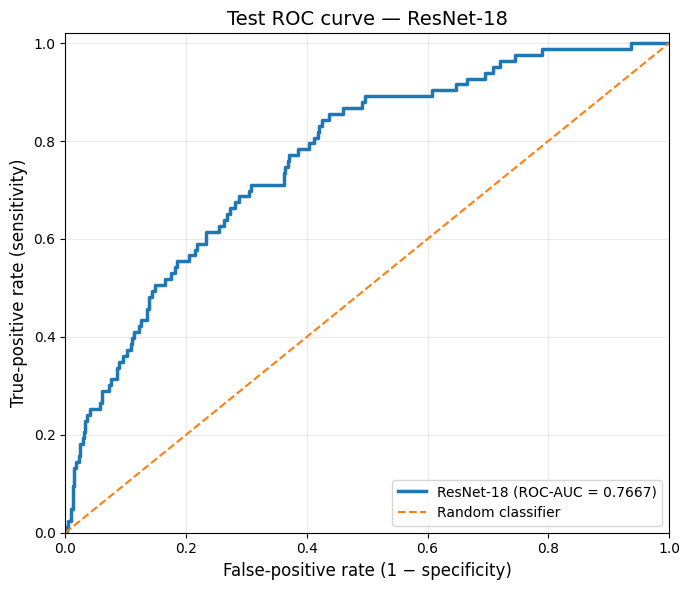

Saved: /kaggle/working/resnet18_focal_noaug_outputs/PR_RESNET18_FOCAL_NOAUG.png


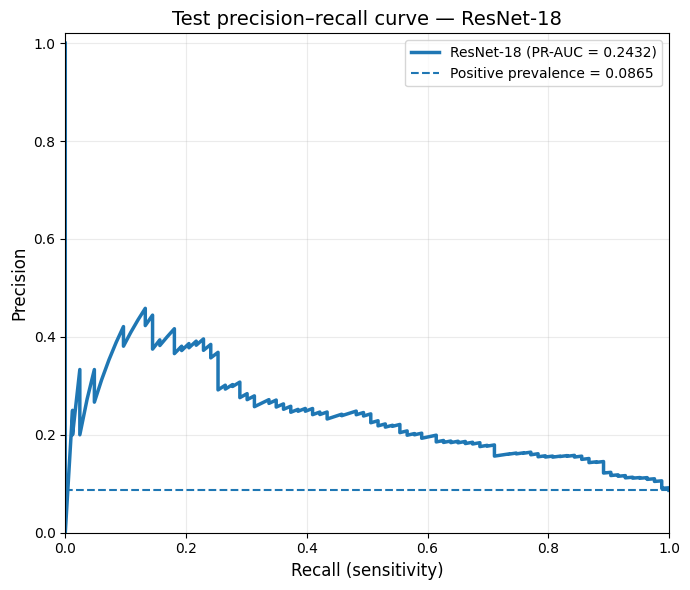

Saved: /kaggle/working/resnet18_focal_noaug_outputs/CM_VAL_RESNET18_FOCAL_NOAUG.png


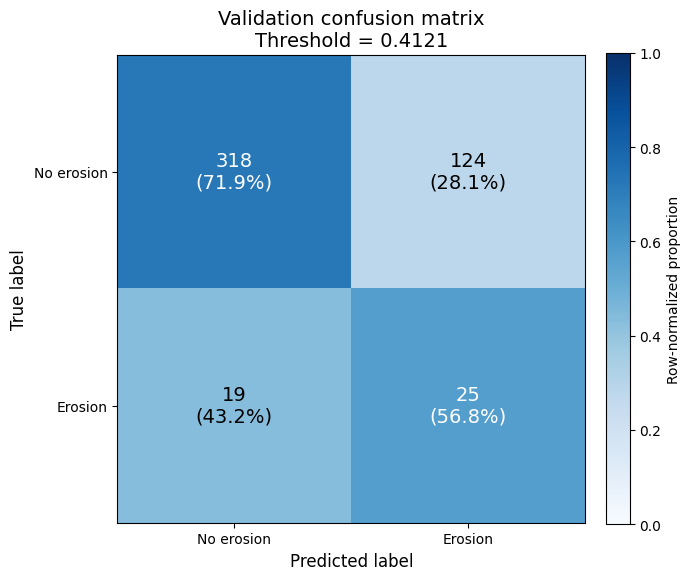

Saved: /kaggle/working/resnet18_focal_noaug_outputs/CM_TEST_RESNET18_FOCAL_NOAUG.png


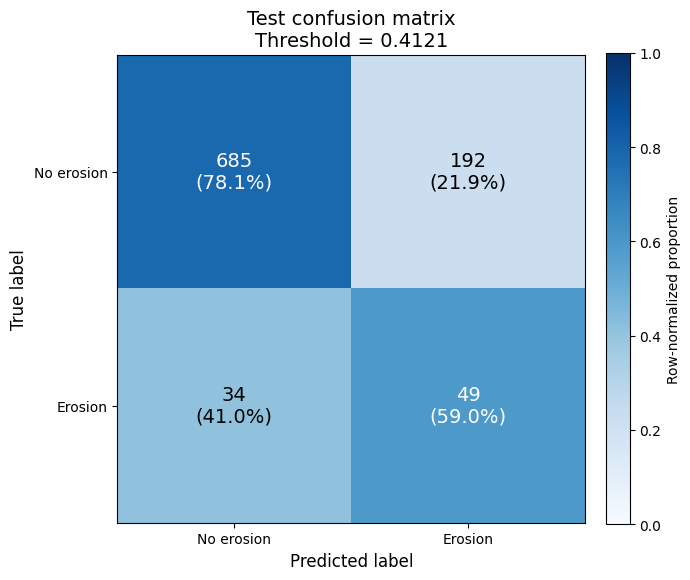

Saved: /kaggle/working/resnet18_focal_noaug_outputs/THRESHOLD_SELECTION_RESNET18_FOCAL_NOAUG.png


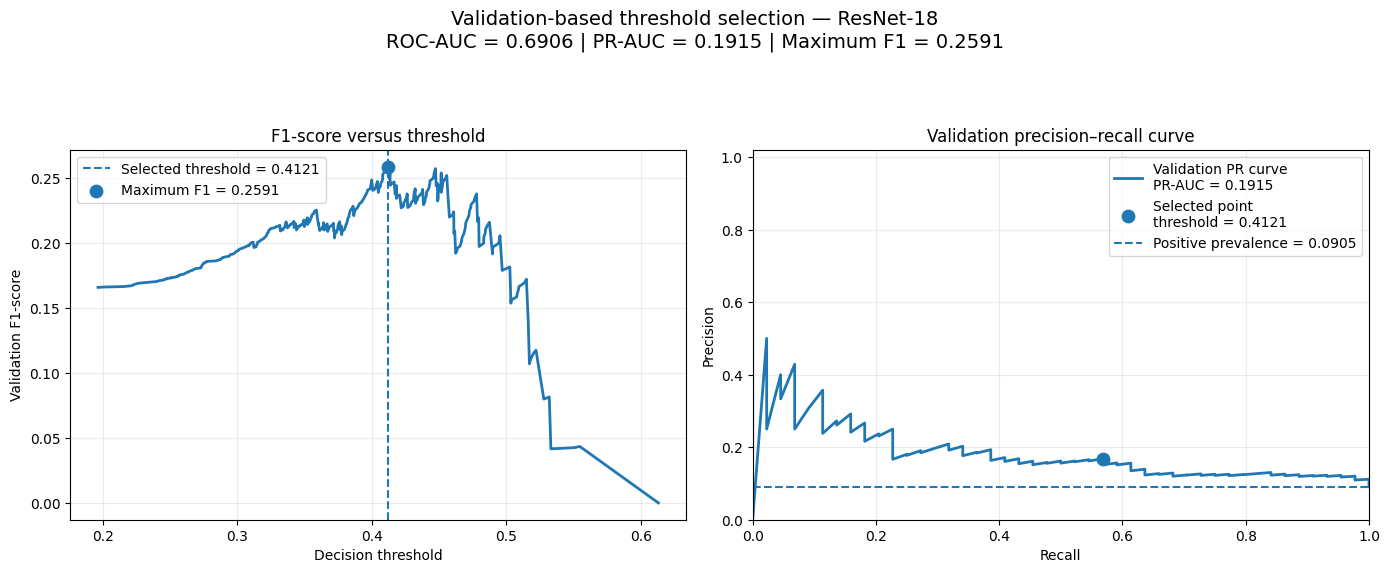

Saved: /kaggle/working/resnet18_focal_noaug_outputs/LOSS_CURVES_RESNET18_FOCAL_NOAUG.png


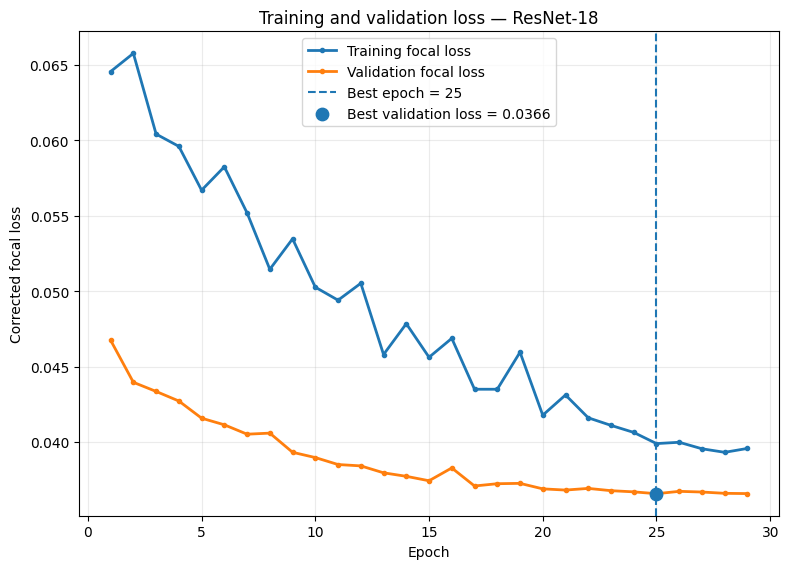

In [113]:
# =========================================================
# FINAL RESNET-18 OUTPUTS — QUANTITATIVE FIGURES
# =========================================================

import shutil
import matplotlib.pyplot as plt

from sklearn.metrics import (
    roc_curve,
    precision_recall_curve
)


# ---------------------------------------------------------
# Sauvegarder sous le nouveau nom et sous l'ancien nom
# utilisé par le poster
# ---------------------------------------------------------
def save_final_figure(
    figure,
    explicit_filename,
    legacy_filename=None
):
    explicit_path = (
        FINAL_OUTPUT_DIR
        / explicit_filename
    )

    figure.savefig(
        explicit_path,
        dpi=300,
        bbox_inches="tight"
    )

    if legacy_filename is not None:
        # Copie dans le dossier de sortie final
        figure.savefig(
            FINAL_OUTPUT_DIR
            / legacy_filename,
            dpi=300,
            bbox_inches="tight"
        )

        # Remplacement direct de l'ancien fichier Kaggle
        figure.savefig(
            Path("/kaggle/working")
            / legacy_filename,
            dpi=300,
            bbox_inches="tight"
        )

    print("Saved:", explicit_path)


# =========================================================
# 1. COURBE ROC DU TEST
# =========================================================
test_fpr, test_tpr, test_roc_thresholds = (
    roc_curve(
        final_y_test,
        final_p_test
    )
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

ax.plot(
    test_fpr,
    test_tpr,
    linewidth=2.5,
    label=(
        "ResNet-18 "
        f"(ROC-AUC = "
        f"{final_test_metrics['roc_auc']:.4f})"
    )
)

ax.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    linewidth=1.5,
    label="Random classifier"
)

ax.set_xlabel(
    "False-positive rate (1 − specificity)",
    fontsize=12
)

ax.set_ylabel(
    "True-positive rate (sensitivity)",
    fontsize=12
)

ax.set_title(
    "Test ROC curve — ResNet-18",
    fontsize=14
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
ax.legend(loc="lower right")

fig.tight_layout()

save_final_figure(
    fig,
    "ROC_RESNET18_FOCAL_NOAUG.png",
    legacy_filename="ROC.png"
)

plt.show()


# =========================================================
# 2. COURBE PRÉCISION–RAPPEL DU TEST
# =========================================================
test_precision_curve, test_recall_curve, _ = (
    precision_recall_curve(
        final_y_test,
        final_p_test
    )
)

test_positive_prevalence = float(
    final_y_test.mean()
)

fig, ax = plt.subplots(
    figsize=(7, 6)
)

ax.plot(
    test_recall_curve,
    test_precision_curve,
    linewidth=2.5,
    label=(
        "ResNet-18 "
        f"(PR-AUC = "
        f"{final_test_metrics['pr_auc']:.4f})"
    )
)

ax.axhline(
    y=test_positive_prevalence,
    linestyle="--",
    linewidth=1.5,
    label=(
        "Positive prevalence = "
        f"{test_positive_prevalence:.4f}"
    )
)

ax.set_xlabel(
    "Recall (sensitivity)",
    fontsize=12
)

ax.set_ylabel(
    "Precision",
    fontsize=12
)

ax.set_title(
    "Test precision–recall curve — ResNet-18",
    fontsize=14
)

ax.set_xlim(0, 1)
ax.set_ylim(0, 1.02)
ax.grid(alpha=0.25)
ax.legend(loc="upper right")

fig.tight_layout()

save_final_figure(
    fig,
    "PR_RESNET18_FOCAL_NOAUG.png",
    legacy_filename="PRECISION.png"
)

plt.show()


# =========================================================
# 3–4. MATRICES DE CONFUSION
# =========================================================
def plot_final_confusion_matrix(
    cm,
    split_name,
    threshold,
    explicit_filename,
    legacy_filename
):
    cm = np.asarray(
        cm,
        dtype=int
    )

    row_totals = cm.sum(
        axis=1,
        keepdims=True
    )

    cm_normalized = (
        cm
        / np.maximum(
            row_totals,
            1
        )
    )

    fig, ax = plt.subplots(
        figsize=(6.8, 6)
    )

    image = ax.imshow(
        cm_normalized,
        vmin=0,
        vmax=1,
        cmap="Blues"
    )

    ax.set_xticks([0, 1])
    ax.set_yticks([0, 1])

    ax.set_xticklabels(
        [
            "No erosion",
            "Erosion"
        ]
    )

    ax.set_yticklabels(
        [
            "No erosion",
            "Erosion"
        ]
    )

    ax.set_xlabel(
        "Predicted label",
        fontsize=12
    )

    ax.set_ylabel(
        "True label",
        fontsize=12
    )

    ax.set_title(
        f"{split_name} confusion matrix\n"
        f"Threshold = {threshold:.4f}",
        fontsize=14
    )

    for row in range(2):
        for column in range(2):
            count = cm[
                row,
                column
            ]

            percentage = cm_normalized[
                row,
                column
            ]

            text_color = (
                "white"
                if percentage > 0.5
                else "black"
            )

            ax.text(
                column,
                row,
                (
                    f"{count}\n"
                    f"({percentage:.1%})"
                ),
                ha="center",
                va="center",
                fontsize=14,
                color=text_color
            )

    colorbar = fig.colorbar(
        image,
        ax=ax,
        fraction=0.046,
        pad=0.04
    )

    colorbar.set_label(
        "Row-normalized proportion"
    )

    fig.tight_layout()

    save_final_figure(
        fig,
        explicit_filename,
        legacy_filename
    )

    plt.show()


plot_final_confusion_matrix(
    final_val_metrics[
        "confusion_matrix"
    ],
    split_name="Validation",
    threshold=final_threshold,
    explicit_filename=(
        "CM_VAL_RESNET18_FOCAL_NOAUG.png"
    ),
    legacy_filename="MATR_C_EVA.png"
)

plot_final_confusion_matrix(
    final_test_metrics[
        "confusion_matrix"
    ],
    split_name="Test",
    threshold=final_threshold,
    explicit_filename=(
        "CM_TEST_RESNET18_FOCAL_NOAUG.png"
    ),
    legacy_filename="MATR_C_TEST.png"
)


# =========================================================
# 5. FIGURE DE SÉLECTION DU SEUIL
# =========================================================
fig, axes = plt.subplots(
    1,
    2,
    figsize=(14, 5.8)
)

# F1 en fonction du seuil
axes[0].plot(
    val_thresholds,
    val_f1_by_threshold,
    linewidth=2
)

axes[0].axvline(
    final_threshold,
    linestyle="--",
    linewidth=1.5,
    label=(
        f"Selected threshold = "
        f"{final_threshold:.4f}"
    )
)

axes[0].scatter(
    [final_threshold],
    [final_validation_f1],
    s=80,
    zorder=3,
    label=(
        f"Maximum F1 = "
        f"{final_validation_f1:.4f}"
    )
)

axes[0].set_xlabel(
    "Decision threshold"
)

axes[0].set_ylabel(
    "Validation F1-score"
)

axes[0].set_title(
    "F1-score versus threshold"
)

axes[0].grid(alpha=0.25)
axes[0].legend()


# Courbe précision–rappel de validation
axes[1].plot(
    val_recall_curve,
    val_precision_curve,
    linewidth=2,
    label=(
        "Validation PR curve\n"
        f"PR-AUC = "
        f"{final_val_metrics['pr_auc']:.4f}"
    )
)

axes[1].scatter(
    [final_threshold_recall],
    [final_threshold_precision],
    s=80,
    zorder=3,
    label=(
        f"Selected point\n"
        f"threshold = "
        f"{final_threshold:.4f}"
    )
)

validation_prevalence = float(
    final_y_val.mean()
)

axes[1].axhline(
    validation_prevalence,
    linestyle="--",
    linewidth=1.5,
    label=(
        "Positive prevalence = "
        f"{validation_prevalence:.4f}"
    )
)

axes[1].set_xlabel(
    "Recall"
)

axes[1].set_ylabel(
    "Precision"
)

axes[1].set_title(
    "Validation precision–recall curve"
)

axes[1].set_xlim(0, 1)
axes[1].set_ylim(0, 1.02)
axes[1].grid(alpha=0.25)
axes[1].legend(loc="upper right")

fig.suptitle(
    (
        "Validation-based threshold selection — "
        "ResNet-18\n"
        f"ROC-AUC = "
        f"{final_val_metrics['roc_auc']:.4f} | "
        f"PR-AUC = "
        f"{final_val_metrics['pr_auc']:.4f} | "
        f"Maximum F1 = "
        f"{final_validation_f1:.4f}"
    ),
    fontsize=14
)

fig.tight_layout(
    rect=[0, 0, 1, 0.90]
)

save_final_figure(
    fig,
    (
        "THRESHOLD_SELECTION_"
        "RESNET18_FOCAL_NOAUG.png"
    )
)

plt.show()


# =========================================================
# 7. COURBES DE PERTE
# =========================================================
training_losses = final_training_history.get(
    "train_loss",
    []
)

validation_losses = final_training_history.get(
    "validation_loss",
    []
)

if (
    len(training_losses) == 0
    or len(validation_losses) == 0
):
    warnings.warn(
        "L'historique des pertes est absent du JSON."
    )

else:
    epochs = np.arange(
        1,
        len(training_losses) + 1
    )

    fig, ax = plt.subplots(
        figsize=(8, 5.8)
    )

    ax.plot(
        epochs,
        training_losses,
        marker="o",
        markersize=3,
        linewidth=2,
        label="Training focal loss"
    )

    ax.plot(
        epochs,
        validation_losses,
        marker="o",
        markersize=3,
        linewidth=2,
        label="Validation focal loss"
    )

    ax.axvline(
        best_epoch,
        linestyle="--",
        linewidth=1.5,
        label=(
            f"Best epoch = {best_epoch}"
        )
    )

    if (
        1 <= best_epoch
        <= len(validation_losses)
    ):
        ax.scatter(
            [best_epoch],
            [
                validation_losses[
                    best_epoch - 1
                ]
            ],
            s=80,
            zorder=3,
            label=(
                "Best validation loss = "
                f"{best_validation_loss:.4f}"
            )
        )

    ax.set_xlabel(
        "Epoch"
    )

    ax.set_ylabel(
        "Corrected focal loss"
    )

    ax.set_title(
        "Training and validation loss — ResNet-18"
    )

    ax.grid(alpha=0.25)
    ax.legend()

    fig.tight_layout()

    save_final_figure(
        fig,
        (
            "LOSS_CURVES_"
            "RESNET18_FOCAL_NOAUG.png"
        )
    )

    plt.show()

Saved: /kaggle/working/resnet18_focal_noaug_outputs/PRED_TEST_RESNET18_FOCAL_NOAUG.png


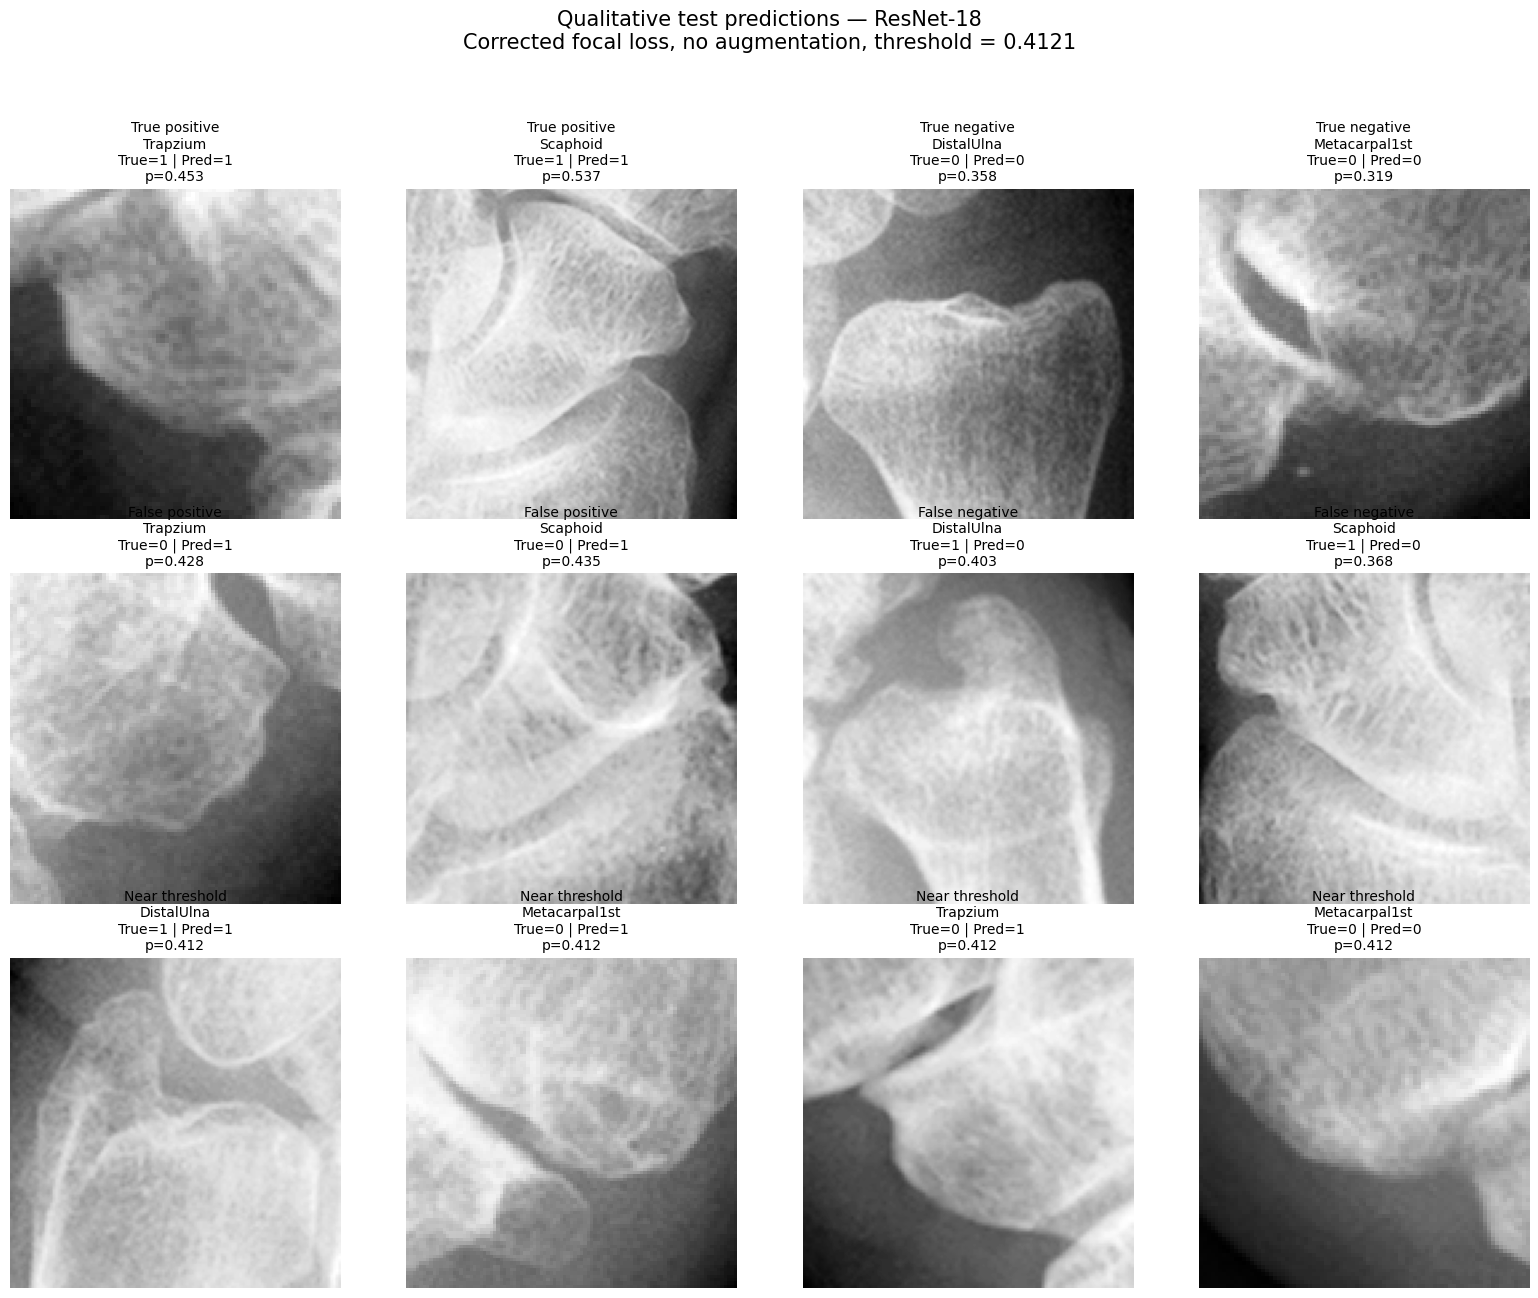


FINAL OUTPUT FILES
CM_TEST_RESNET18_FOCAL_NOAUG.png
CM_VAL_RESNET18_FOCAL_NOAUG.png
LOSS_CURVES_RESNET18_FOCAL_NOAUG.png
MATR_C_EVA.png
MATR_C_TEST.png
PRECISION.png
PRED_TEST.png
PRED_TEST_RESNET18_FOCAL_NOAUG.png
PR_RESNET18_FOCAL_NOAUG.png
ROC.png
ROC_RESNET18_FOCAL_NOAUG.png
THRESHOLD_SELECTION_RESNET18_FOCAL_NOAUG.png
metrics_resnet18_focal_noaug.csv
qualitative_examples_resnet18_focal_noaug.csv
test_predictions_resnet18_focal_noaug.csv
validation_predictions_resnet18_focal_noaug.csv

ZIP archive: /kaggle/working/resnet18_focal_noaug_outputs.zip


In [114]:
# =========================================================
# FINAL RESNET-18 OUTPUTS — QUALITATIVE PREDICTIONS
# =========================================================

from PIL import Image


# ---------------------------------------------------------
# Sélection équilibrée des exemples
# ---------------------------------------------------------
QUALITATIVE_SEED = 42

rng = np.random.default_rng(
    QUALITATIVE_SEED
)

selected_indices = []
selected_labels = []


def add_examples_from_category(
    dataframe,
    category,
    number
):
    candidate_indices = dataframe.index[
        dataframe["prediction_category"]
        == category
    ].to_numpy()

    candidate_indices = np.array(
        [
            index
            for index in candidate_indices
            if index not in selected_indices
        ]
    )

    if len(candidate_indices) == 0:
        return

    number_to_select = min(
        number,
        len(candidate_indices)
    )

    chosen_indices = rng.choice(
        candidate_indices,
        size=number_to_select,
        replace=False
    )

    for index in chosen_indices:
        selected_indices.append(
            int(index)
        )

        selected_labels.append(
            category
        )


# Deux exemples de chaque catégorie principale
add_examples_from_category(
    test_predictions_df,
    "True positive",
    2
)

add_examples_from_category(
    test_predictions_df,
    "True negative",
    2
)

add_examples_from_category(
    test_predictions_df,
    "False positive",
    2
)

add_examples_from_category(
    test_predictions_df,
    "False negative",
    2
)


# ---------------------------------------------------------
# Ajouter quatre cas proches du seuil
# ---------------------------------------------------------
remaining_near_threshold = (
    test_predictions_df
    .loc[
        ~test_predictions_df.index.isin(
            selected_indices
        )
    ]
    .sort_values(
        "distance_to_threshold",
        ascending=True
    )
    .head(4)
)

for index in remaining_near_threshold.index:
    selected_indices.append(
        int(index)
    )

    selected_labels.append(
        "Near threshold"
    )


# ---------------------------------------------------------
# Compléter jusqu'à 12 images si une catégorie manque
# ---------------------------------------------------------
TARGET_NUMBER_OF_IMAGES = 12

if len(selected_indices) < TARGET_NUMBER_OF_IMAGES:
    remaining_indices = (
        test_predictions_df.index[
            ~test_predictions_df.index.isin(
                selected_indices
            )
        ]
        .to_numpy()
    )

    number_missing = min(
        TARGET_NUMBER_OF_IMAGES
        - len(selected_indices),
        len(remaining_indices)
    )

    if number_missing > 0:
        additional_indices = rng.choice(
            remaining_indices,
            size=number_missing,
            replace=False
        )

        for index in additional_indices:
            selected_indices.append(
                int(index)
            )

            selected_labels.append(
                test_predictions_df.loc[
                    index,
                    "prediction_category"
                ]
            )


# ---------------------------------------------------------
# Afficher les images
# ---------------------------------------------------------
number_of_images = len(
    selected_indices
)

number_of_columns = 4

number_of_rows = int(
    np.ceil(
        number_of_images
        / number_of_columns
    )
)

fig, axes = plt.subplots(
    number_of_rows,
    number_of_columns,
    figsize=(
        16,
        4.4 * number_of_rows
    )
)

axes = np.atleast_1d(
    axes
).ravel()

for subplot_index, (
    dataframe_index,
    selection_label
) in enumerate(
    zip(
        selected_indices,
        selected_labels
    )
):
    row = test_predictions_df.loc[
        dataframe_index
    ]

    image = Image.open(
        row["image_path"]
    ).convert("L")

    axis = axes[
        subplot_index
    ]

    axis.imshow(
        image,
        cmap="gray"
    )

    axis.axis("off")

    axis.set_title(
        (
            f"{selection_label}\n"
            f"{row['anatomical_region']}\n"
            f"True={int(row['true_label'])} | "
            f"Pred={int(row['predicted_label'])}\n"
            f"p={row['predicted_probability']:.3f}"
        ),
        fontsize=10
    )


# Masquer les axes inutilisés
for subplot_index in range(
    number_of_images,
    len(axes)
):
    axes[subplot_index].axis(
        "off"
    )


fig.suptitle(
    (
        "Qualitative test predictions — ResNet-18\n"
        f"Corrected focal loss, no augmentation, "
        f"threshold = {final_threshold:.4f}"
    ),
    fontsize=15
)

fig.tight_layout(
    rect=[0, 0, 1, 0.94]
)

save_final_figure(
    fig,
    "PRED_TEST_RESNET18_FOCAL_NOAUG.png",
    legacy_filename="PRED_TEST.png"
)

plt.show()


# ---------------------------------------------------------
# Sauvegarder la liste exacte des images affichées
# ---------------------------------------------------------
qualitative_examples_df = (
    test_predictions_df.loc[
        selected_indices
    ]
    .copy()
)

qualitative_examples_df.insert(
    0,
    "display_group",
    selected_labels
)

qualitative_examples_df.to_csv(
    FINAL_OUTPUT_DIR
    / (
        "qualitative_examples_"
        "resnet18_focal_noaug.csv"
    ),
    index=False
)


# ---------------------------------------------------------
# Créer une archive ZIP de toutes les sorties
# ---------------------------------------------------------
archive_base_path = str(
    Path("/kaggle/working")
    / "resnet18_focal_noaug_outputs"
)

archive_path = shutil.make_archive(
    archive_base_path,
    "zip",
    root_dir=FINAL_OUTPUT_DIR
)

print("\n" + "=" * 75)
print("FINAL OUTPUT FILES")
print("=" * 75)

for output_file in sorted(
    FINAL_OUTPUT_DIR.iterdir()
):
    print(output_file.name)

print("\nZIP archive:", archive_path)